# BestSeller Prediction: Logistic Regression from Scratch
**PDAN8412 · Part 2 · Louis Francois Fourie (ST10152431)**

**DATASET:** *Amazon Kindle Books Dataset 2023* from Kaggle (`kindle_data-v2.csv`): about 130,000 Kindle ebooks scraped from Amazon.com in October 2023, well above the brief's minimum of 10,000 records. Each row is one book's product page, with 16 columns covering what the book is (title, author, seller, category, publication date), how it is sold (price, Kindle Unlimited), how readers rated it (stars, review count) and which Amazon badges it carried on the day of the scrape, including the target, `isBestSeller`.
[Amazon Kindle Books Dataset 2023 (130K Books)](https://www.kaggle.com/datasets/asaniczka/amazon-kindle-books-dataset-2023-130k-books) · Kaggle · file used: `kindle_data-v2.csv`

**PROBLEM:** The book press wants to know, before investing in a title, whether it is likely to become a bestseller, and which characteristics of a book make that more likely. The model must be a logistic regression built from scratch, without a machine-learning library doing the training, on a dataset we sourced ourselves.

**SOLUTION:** Treat it as a yes/no (binary) classification task with `isBestSeller` as the target. First explore the data to understand each column and its link to bestsellers, then clean it and turn the useful columns into numeric features. Next, write logistic regression in NumPy (sigmoid, log loss, gradient descent), train it on one part of the data, tune it on a second and score it once on a held-out test set. Finally, compare it with simple baselines and read its weights to explain which book characteristics drive bestseller status.

Github: 

### Imports, download dataset, and a quick first look
###### (*explained according to plan*)

In [1]:
# --- Imports: everything lives here ---
# One deliberate exception: scikit-learn is imported only in the referee section,
# so a marker can see at a glance that no library model is used before it.
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from scipy.stats import chi2_contingency                               # chi-square test, used by cramers_v below
from matplotlib.patches import Patch                                     # coloured legend keys for the chart below
from sklearn.model_selection import train_test_split                    # used only to shuffle and divide the book keys
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.metrics import precision_recall_curve

from matplotlib.patches import Patch
import json
from datetime import date
from pathlib import Path

# --- Settings ---
SEED = 42
rng = np.random.default_rng(SEED)

ROOT = Path.cwd().parent              # the notebook runs inside notebooks/, so go up one level
DATA_DIR = ROOT / "data"
MODEL_DIR = ROOT / "models"
FIG_DIR = ROOT / "reports" / "figures"
for d in (DATA_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("NumPy", np.__version__, "| pandas", pd.__version__)
print("Project folder:", ROOT)

/home/francois/miniconda3/envs/ml/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NumPy 2.4.6 | pandas 3.0.5
Project folder: /home/francois/projects/bestseller_lr


In [2]:
path = kagglehub.dataset_download("asaniczka/amazon-kindle-books-dataset-2023-130k-books")
print(path)
for f in os.listdir(path):
    print(f, "->", pd.read_csv(os.path.join(path, f), nrows=0).columns.tolist())

/home/francois/.cache/kagglehub/datasets/asaniczka/amazon-kindle-books-dataset-2023-130k-books/versions/35
kindle_data-v2.csv -> ['asin', 'title', 'author', 'soldBy', 'imgUrl', 'productURL', 'stars', 'reviews', 'price', 'isKindleUnlimited', 'category_id', 'isBestSeller', 'isEditorsPick', 'isGoodReadsChoice', 'publishedDate', 'category_name']


In [3]:
BOOKS_FILE = "kindle_data-v2.csv"
df_raw = pd.read_csv(os.path.join(path, BOOKS_FILE))

print(df_raw.shape)
df_raw.info()
display(df_raw.head())

(133102, 16)
<class 'pandas.DataFrame'>
RangeIndex: 133102 entries, 0 to 133101
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   asin               133102 non-null  str    
 1   title              133102 non-null  str    
 2   author             132677 non-null  str    
 3   soldBy             123869 non-null  str    
 4   imgUrl             133102 non-null  str    
 5   productURL         133102 non-null  str    
 6   stars              133102 non-null  float64
 7   reviews            133102 non-null  int64  
 8   price              133102 non-null  float64
 9   isKindleUnlimited  133102 non-null  bool   
 10  category_id        133102 non-null  int64  
 11  isBestSeller       133102 non-null  bool   
 12  isEditorsPick      133102 non-null  bool   
 13  isGoodReadsChoice  133102 non-null  bool   
 14  publishedDate      84086 non-null   str    
 15  category_name      133102 non-null  str    
dtype

,asin,title,author,soldBy,imgUrl,productURL,stars,reviews,price,isKindleUnlimited,category_id,isBestSeller,isEditorsPick,isGoodReadsChoice,publishedDate,category_name
0,B00TZE87S4,Adult Children of Emotionally Immature Parents...,Lindsay C. Gibson,Amazon.com Services LLC,https://m.media-amazon.com/images/I/713KZTsaYp...,https://www.amazon.com/dp/B00TZE87S4,4.8,0,9.99,False,6,True,False,False,2015-06-01,Parenting & Relationships
1,B08WCKY8MB,"From Strength to Strength: Finding Success, Ha...",Arthur C. Brooks,Penguin Group (USA) LLC,https://m.media-amazon.com/images/I/A1LZcJFs9E...,https://www.amazon.com/dp/B08WCKY8MB,4.4,0,16.99,False,6,False,False,False,2022-02-15,Parenting & Relationships
2,B09KPS84CJ,Good Inside: A Guide to Becoming the Parent Yo...,Becky Kennedy,HarperCollins Publishers,https://m.media-amazon.com/images/I/71RIWM0sv6...,https://www.amazon.com/dp/B09KPS84CJ,4.8,0,16.99,False,6,False,True,False,2022-09-13,Parenting & Relationships
3,B07S7QPG6J,Everything I Know About Love: A Memoir,Dolly Alderton,HarperCollins Publishers,https://m.media-amazon.com/images/I/71QdQpTiKZ...,https://www.amazon.com/dp/B07S7QPG6J,4.2,0,9.95,True,6,False,True,False,2020-02-25,Parenting & Relationships
4,B00N6PEQV0,The Seven Principles for Making Marriage Work:...,John Gottman,Random House LLC,https://m.media-amazon.com/images/I/813o4WOs+w...,https://www.amazon.com/dp/B00N6PEQV0,4.7,0,13.99,False,6,False,False,False,2015-05-05,Parenting & Relationships


In [4]:
target = df_raw["isBestSeller"]
print("Column type:", target.dtype)
print(target.value_counts(dropna=False))

pos = int(target.sum())
neg = len(target) - pos
print(f"\nBestsellers: {pos:,} of {len(target):,} ({pos / len(target):.2%})")
print(f"That's 1 bestseller for every {neg / pos:.0f} other books")

Column type: bool
isBestSeller
False    130866
True       2236
Name: count, dtype: int64

Bestsellers: 2,236 of 133,102 (1.68%)
That's 1 bestseller for every 59 other books


### Exploratory Data Analysis

##### EDA findings & notes

<details>
<summary><b>Click to open: what each EDA section found and decided</b></summary>

**First look:** The dataset holds **133,102 Kindle books across 16 columns**, scraped from Amazon in October 2023. The target, `isBestSeller`, is a clean True/False column with no missing values. Only **2,236 books (1.68%, about 1 in 59)** carry the bestseller badge, so a model that always answers "not a bestseller" would score 98.32% accuracy while catching none. Accuracy is therefore not used to judge models; PR-AUC, precision, recall and F1 are used instead, and random guessing sets the PR-AUC floor at 0.0168. Three columns have gaps: `publishedDate` is missing for 49,016 books (36.8%), `soldBy` for 9,233 (6.9%) and `author` for 425. Dropping those rows would discard over a third of the data, so they are kept and handled during data preparation.

**EDA 1: Data quality, dates, stars and reviews, duplicates.** The blanks in dates, sellers and authors are unrelated to the bestseller label, so all rows are kept: a missing seller becomes "Unknown" and a missing date gets a flag. There are no impossible values, but price (median $9.99, max $682) and reviews are very skewed, so both are log-transformed. 6 books are dated after the snapshot (pre-orders), so age is clipped at 0. 61,488 books show a star rating but 0 reviews; these are lost counts, not real zeros, so they become missing with a flag, leaving only 3,182 truly unrated books. Stars barely separate bestsellers (AUC about 0.50) and reviews only moderately (AUC 0.538, rising to 0.587 once lost counts are left out). 885 books appear as 1,792 listings (different editions, 52 of which disagree on the label), so the data is split by book (title + author) to keep every edition of a book in the same split.

**EDA 2: Class balance and hidden blank authors.** With only about 1 bestseller in 60 books, bestsellers are given extra weight during training and every split keeps the same bestseller rate (stratified split). Two authors are hidden blanks ("none" and "unknown"), so they are set to missing like the real blanks; otherwise they would look like one very prolific author.

**EDA 3: Category.** The 31 categories range from 0.27% (LGBTQ+) to 5.34% (Nonfiction) bestsellers, a weak-to-moderate link (Cramér's V = 0.079). The badge is not simply "top N per category", category sizes look capped by the scraper, and some labels are noisy. `category_id` repeats `category_name` and is dropped; `category_name` is one-hot encoded with Mystery, Thriller & Suspense (an average category) as the reference.

**EDA 4: Price.** Cheaper books are far more often bestsellers: 7.49% at $1–2.98 against 0.62% at $15+, with a sharp step at $2.99. The pattern holds inside 27 of 31 categories (bestseller median $5.99 vs $9.99), so it is not just a category effect. None of the 93 most expensive books is a bestseller; they are textbooks and box sets. Price enters the model as `log_price` plus an `is_under_2_99` flag. Titles mentioning hardcover or paperback were checked in cleaning (P2) and kept, as they turned out to be Kindle listings that mention a print edition.

**EDA 5: Seller and Kindle Unlimited.** The 49 seller names include duplicates and imprints, so they are grouped into 12 publisher groups (V = 0.056). Kindle Unlimited is the strongest single feature (V = 0.114): KU books are 5× as likely to be bestsellers (4.09% vs 0.79%) and make up 65.5% of all bestsellers. KU wins in all 31 categories, and the gap is even larger inside categories (+5.13 points) than overall (+3.30), so the effect is not a category mix. Big publishers rarely use KU and charge more, so KU, price and publisher go into the model together and each weight is read with the others held equal. Free books only look strong because of De Marque's free classics (1.69% without them), so no separate `is_free` flag is used; `publisher_grp` already captures it.

**EDA 6: Authors.** No single author dominates (J.K. Rowling leads with 16 bestsellers) and some "authors" are brands (DK, Hourly History). 89% of the 1,926 bestselling authors have just one bestseller. Authors with only one book in the data do worst (1.24% vs about 2%), so a `single_book_author` flag is used, counted on the training split only. Author names and author bestseller rates are never used as features, because they would leak the label.

**EDA 7: Recency and titles.** New books are twice as likely to carry the badge (3.54% at 0–3 months vs 1.07% at 10+ years); this is a snapshot effect, since every book is age 0 at launch, so age goes in Set B only. Colon titles do slightly better (1.86% vs 1.32%) and "A Novel" titles much worse (0.56%, mostly Big Five fiction), while series markers and brackets make no difference. Longer titles go with more bestsellers, mainly inside KU (21+ words: 8.08% in KU vs 0.70% outside). Success phrases ("bestselling", "#1") are rare (969 titles) and barely linked to the label, so they pose no leakage risk. Kept: `title_words` (capped at 30), `has_colon`, `has_a_novel`. Dropped: `has_series`, `has_brackets`.

**EDA 8: Editors' Pick and Goodreads Choice badges.** Books with these badges are never bestsellers (0 of 7,023, against about 118 expected). Each book shows at most one badge, so the bestseller label of these books cannot be trusted. They are prestige books (about 70–76% Big Five, rarely in KU). The 7,023 badge books and both badge columns are removed, leaving 126,079 books (1.77% bestsellers).

**EDA 9: Feature strength and correlation.** The strongest features are all known before launch: KU (V = 0.114), price (0.088), category (0.079) and publisher (0.056). After-launch signals are weaker: reviews (0.052), age (0.050) and stars (0.020), so only a small gap between Set A and Set B is expected. No pair of planned features is strongly correlated (highest 0.51), so all planned features are kept, with an L2 penalty as a safeguard.

</details>

##### EDA 1 

In [5]:
# First look: what does each column hold?
print(f"{len(df_raw):,} rows x {df_raw.shape[1]} columns")               # how big the dataset is

with pd.option_context("display.max_columns", None,                     # show every column (no "..." hiding some)
                       "display.max_colwidth", 40):                      # cut long text (titles, links) at 40 characters
    print("\nThe first 10 books:")
    display(df_raw.head(10))                                             # the first 10 rows, all 16 columns

    print("\nFive bestsellers, for comparison:")                         # the first 10 rows are probably all non-bestsellers
    display(df_raw[df_raw["isBestSeller"]].head(5))                      # so also show five books where isBestSeller is True

# A one-line guide per column: its type, an example value, how many different values and blanks it has
guide = pd.DataFrame({
    "type": df_raw.dtypes.astype(str),                                   # number, text, True/False...
    "example (row 0)": df_raw.iloc[0].astype(str).str.slice(0, 60),      # the first book's value, cut to 60 characters
    "distinct values": df_raw.nunique(),                                 # how many different values the column has
    "blanks": df_raw.isna().sum(),                                       # how many empty cells (same as 1a)
})
print("\nColumn guide:")
display(guide)

133,102 rows x 16 columns

The first 10 books:


,asin,title,author,soldBy,imgUrl,productURL,stars,reviews,price,isKindleUnlimited,category_id,isBestSeller,isEditorsPick,isGoodReadsChoice,publishedDate,category_name
0,B00TZE87S4,Adult Children of Emotionally Immatu...,Lindsay C. Gibson,Amazon.com Services LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B00TZE87S4,4.8,0,9.99,False,6,True,False,False,2015-06-01,Parenting & Relationships
1,B08WCKY8MB,From Strength to Strength: Finding S...,Arthur C. Brooks,Penguin Group (USA) LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B08WCKY8MB,4.4,0,16.99,False,6,False,False,False,2022-02-15,Parenting & Relationships
2,B09KPS84CJ,Good Inside: A Guide to Becoming the...,Becky Kennedy,HarperCollins Publishers,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B09KPS84CJ,4.8,0,16.99,False,6,False,True,False,2022-09-13,Parenting & Relationships
3,B07S7QPG6J,Everything I Know About Love: A Memoir,Dolly Alderton,HarperCollins Publishers,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B07S7QPG6J,4.2,0,9.95,True,6,False,True,False,2020-02-25,Parenting & Relationships
4,B00N6PEQV0,The Seven Principles for Making Marr...,John Gottman,Random House LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B00N6PEQV0,4.7,0,13.99,False,6,False,False,False,2015-05-05,Parenting & Relationships
5,B000OVLKMM,The Glass Castle: A Memoir,Jeannette Walls,Simon and Schuster Digital Sales Inc,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B000OVLKMM,4.6,0,13.99,False,6,False,False,False,2005-03-01,Parenting & Relationships
6,B00AEBEQUK,Expecting Better: Why the Convention...,Emily Oster,Penguin Group (USA) LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B00AEBEQUK,4.6,0,14.99,False,6,True,False,False,NaN,Parenting & Relationships
7,B0BN5742KY,Never Enough: When Achievement Cultu...,Jennifer Breheny Wallace,Penguin Group (USA) LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B0BN5742KY,4.6,0,15.99,False,6,False,True,False,2023-08-22,Parenting & Relationships
8,B098PXH8CK,Unmasking Autism: Discovering the Ne...,Devon Price,Random House LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B098PXH8CK,4.7,0,12.99,False,6,True,False,False,2022-04-05,Parenting & Relationships
9,B087D5YQXB,What Happened to You?: Conversations...,Oprah Winfrey,Macmillan,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B087D5YQXB,4.7,0,14.99,True,6,False,True,False,2021-04-27,Parenting & Relationships



Five bestsellers, for comparison:


,asin,title,author,soldBy,imgUrl,productURL,stars,reviews,price,isKindleUnlimited,category_id,isBestSeller,isEditorsPick,isGoodReadsChoice,publishedDate,category_name
0,B00TZE87S4,Adult Children of Emotionally Immatu...,Lindsay C. Gibson,Amazon.com Services LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B00TZE87S4,4.8,0,9.99,False,6,True,False,False,2015-06-01,Parenting & Relationships
6,B00AEBEQUK,Expecting Better: Why the Convention...,Emily Oster,Penguin Group (USA) LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B00AEBEQUK,4.6,0,14.99,False,6,True,False,False,NaN,Parenting & Relationships
8,B098PXH8CK,Unmasking Autism: Discovering the Ne...,Devon Price,Random House LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B098PXH8CK,4.7,0,12.99,False,6,True,False,False,2022-04-05,Parenting & Relationships
11,B0B69SQNJY,A Little Pinprick (Rainey Paxton Ser...,Paige Dearth,Amazon.com Services LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B0B69SQNJY,4.6,0,5.99,True,6,True,False,False,NaN,Parenting & Relationships
17,B0CBL7RV55,It Starts with the Egg: How the Scie...,Rebecca Fett,Amazon.com Services LLC,https://m.media-amazon.com/images/I/...,https://www.amazon.com/dp/B0CBL7RV55,4.7,0,9.99,False,6,True,False,False,NaN,Parenting & Relationships



Column guide:


,type,example (row 0),distinct values,blanks
asin,str,B00TZE87S4,133102,0
title,str,Adult Children of Emotionally Immature Parents...,131913,0
author,str,Lindsay C. Gibson,72805,425
soldBy,str,Amazon.com Services LLC,49,9233
imgUrl,str,https://m.media-amazon.com/images/I/713KZTsaYp...,132909,0
productURL,str,https://www.amazon.com/dp/B00TZE87S4,133102,0
stars,float64,4.8,38,0
reviews,int64,0,8441,0
price,float64,9.99,4795,0
isKindleUnlimited,bool,False,2,0


In [6]:
# Real blanks (NaN): how much is missing per column?
eda = df_raw.copy()                                                    # work on a copy, so df_raw is never changed
BASE_RATE = eda["isBestSeller"].mean()                                 # overall bestseller rate: the yardstick for every comparison
print(f"Overall bestseller rate: {BASE_RATE:.2%}\n")

missing = df_raw.isna().sum().to_frame("missing")                      # count NaN in every original column
missing["share"] = (missing["missing"] / len(df_raw)).round(4)         # the same count as a share of all rows
display(missing[missing["missing"] > 0].sort_values("missing", ascending=False))   # only columns with gaps

# Does a gap tell us anything about bestsellers?
for col in ["publishedDate", "soldBy", "author"]:
    gap = eda[col].isna()                                              # True where this column is blank
    print(f"{col:14s} rate when missing: {eda.loc[gap, 'isBestSeller'].mean():.2%} "
          f"({gap.sum():,} books) | when present: {eda.loc[~gap, 'isBestSeller'].mean():.2%}")

Overall bestseller rate: 1.68%



,missing,share
publishedDate,49016,0.3683
soldBy,9233,0.0694
author,425,0.0032


publishedDate  rate when missing: 1.71% (49,016 books) | when present: 1.66%
soldBy         rate when missing: 1.95% (9,233 books) | when present: 1.66%
author         rate when missing: 1.88% (425 books) | when present: 1.68%


In [7]:
# Hidden blanks: text that looks filled in but means "missing"
text_cols = ["title", "author", "soldBy", "category_name", "publishedDate"]
placeholders = {"", "unknown", "n/a", "na", "none", "null", "-"}        # common stand-ins for "missing"
for col in text_cols:
    s = eda[col].dropna().str.strip().str.lower()                       # skip real blanks, trim spaces, lower-case
    print(f"{col:14s} placeholder-like values: {s.isin(placeholders).sum()}")

# Zeros that may really mean "no data"
print("\nBooks with 0 stars:  ", (eda["stars"] == 0).sum())             # usually "no ratings yet"
print("Books with 0 reviews:", (eda["reviews"] == 0).sum())
print("Free books (price 0):", (eda["price"] == 0).sum())

# Impossible values: any count above 0 is a data error
print("\nNegative prices:  ", (eda["price"] < 0).sum())
print("Stars outside 0-5:", (~eda["stars"].between(0, 5)).sum())       # between() includes both ends
print("Negative reviews: ", (eda["reviews"] < 0).sum())

title          placeholder-like values: 0
author         placeholder-like values: 2
soldBy         placeholder-like values: 0
category_name  placeholder-like values: 0
publishedDate  placeholder-like values: 0

Books with 0 stars:   3182
Books with 0 reviews: 64670
Free books (price 0): 4066

Negative prices:   0
Stars outside 0-5: 0
Negative reviews:  0


In [8]:
# Extremes: the spread of each number, from the bottom 1% to the maximum
display(eda[["price", "reviews", "stars"]]
        .quantile([0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1.0])            # 0.5 = median, 1.0 = maximum
        .round(2))

# The ten most expensive books: real, or errors?
display(eda.nlargest(10, "price")[["title", "author", "soldBy", "price", "category_name"]])

,price,reviews,stars
0.010,0.00,0.00,0.0
0.250,4.99,0.00,4.4
0.500,9.99,4.00,4.5
0.750,14.99,365.00,4.7
0.990,101.65,13752.99,5.0
0.999,282.99,65117.41,5.0
1.000,682.00,618227.00,5.0


,title,author,soldBy,price,category_name
123336,Drugs in Litigation: Damage Awards Involving P...,LexisNexis Editorial Staff,Amazon.com Services LLC,682.00,Law
125981,Broker-Dealer Regulation,Clifford E. Kirsch,Amazon.com Services LLC,662.00,Law
15712,Youmans and Winn Neurological Surgery E-Book: ...,H. Richard Winn,Amazon.com Services LLC,636.99,Science & Math
123725,How to Write a Patent Application,Jeffrey G. Sheldon,Amazon.com Services LLC,629.00,Law
113257,The Collected Works of C. G. Jung: Revised and...,C. G. Jung,Amazon.com Services LLC,549.99,"Health, Fitness & Dieting"
117647,"The Art of Aesthetic Surgery, Three Volume Set...",Foad Nahai,Amazon.com Services LLC,543.99,Medical
117177,"Perforator Flaps: Anatomy, Technique, & Clinic...",Phillip N. Blondeel,Amazon.com Services LLC,481.49,Medical
124945,International Commercial Arbitration: Three Vo...,Gary B. Born,Amazon.com Services LLC,480.00,Law
124152,LexisNexis Practice Guide: Florida Personal In...,Ervin A. Gonzalez,Amazon.com Services LLC,465.99,Law
125127,Private Equity Funds: Formation and Operations,Stephanie R. Breslow,Amazon.com Services LLC,462.00,Law


Dates present but unreadable: 0
Earliest: 1806-01-01 | Latest: 2024-01-16
Dated after the snapshot (not yet released): 6
Dated before 1990: 279


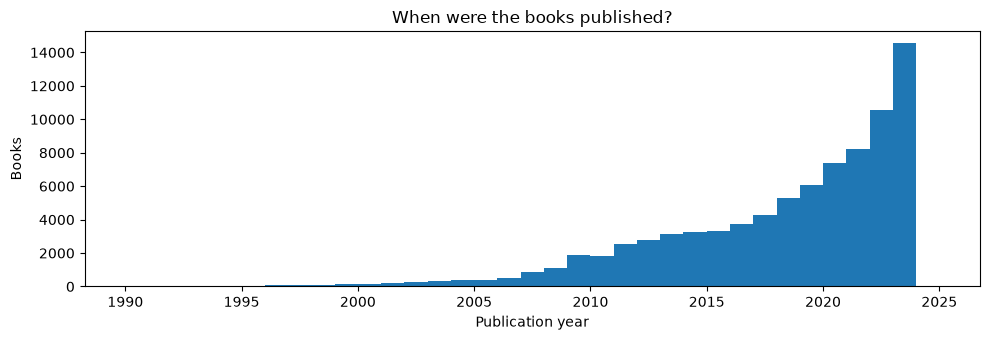

In [9]:
# Dates: do they convert, and are they in a sensible range?
SNAPSHOT = pd.Timestamp("2023-10-01")                                  # Kaggle says the data was scraped in October 2023
eda["pub_date"] = pd.to_datetime(eda["publishedDate"], errors="coerce", format="mixed")   # text -> dates; bad ones become NaT
eda["pub_year"] = eda["pub_date"].dt.year                              # NaN where the date is missing
eda["age_months"] = (SNAPSHOT - eda["pub_date"]).dt.days / 30.44       # months from publication to the scrape (used in 1g and 7a)


def save(fig, name):
    """Tidy the layout, save the chart to reports/figures, then show it."""
    fig.tight_layout()                                                 # stop labels overlapping
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150)                      # file used later in the report
    plt.show()


unreadable = eda["pub_date"].isna() & eda["publishedDate"].notna()     # had text, but it wasn't a date
print("Dates present but unreadable:", unreadable.sum())
print("Earliest:", eda["pub_date"].min().date(), "| Latest:", eda["pub_date"].max().date())
print("Dated after the snapshot (not yet released):", (eda["pub_date"] > SNAPSHOT).sum())
print("Dated before 1990:", (eda["pub_date"] < "1990-01-01").sum())   # very old: reprints of classics, or errors

years = eda["pub_year"].dropna()                                       # publication year of every dated book
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(years[years >= 1990], bins=range(1990, 2026))                  # one bar per year from 1990
ax.set_xlabel("Publication year")
ax.set_ylabel("Books")
ax.set_title("When were the books published?")
save(fig, "eda_01d_publication_years")

ALL books:


Reviews,Has reviews (1+),Shows 0 reviews,Total
Stars,,,
Has a star rating,68432,61488,129920
No star rating (0 stars),0,3182,3182
Total,68432,64670,133102


BESTSELLERS only:


Reviews,Has reviews (1+),Shows 0 reviews,Total
Stars,,,
Has a star rating,1230,1001,2231
No star rating (0 stars),0,5,5
Total,1230,1006,2236


Bestseller rate | 0 reviews: 1.56% | 1+ reviews: 1.80%

Star ratings of books that show 0 reviews but have stars:


count    61488.00
mean         4.51
std          0.30
min          1.00
25%          4.40
50%          4.60
75%          4.70
max          5.00
Name: stars, dtype: float64

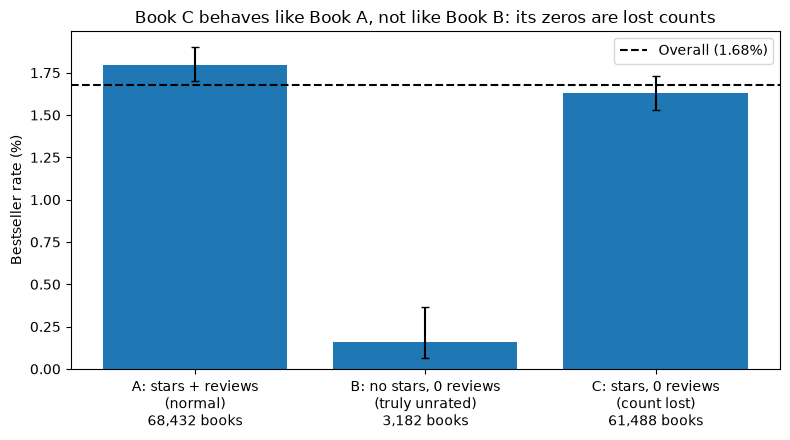

In [10]:
# The reviews puzzle: do "0 stars" and "0 reviews" line up?

# --- Helpers used from here on (bestseller rates, intervals, AUC and rate charts) ---
def wilson_ci(k, n, z=1.96):
    """95% confidence interval for a rate of k bestsellers out of n books (Wilson method, good for rare events)."""
    p = k / n                                                          # observed rate
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)                     # centre of the interval
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)   # half its width
    return centre - half, centre + half


def rate_table(df, col, min_books=0, sort_by_rate=True):
    """Bestseller rate per group, with counts beside it so tiny groups can't fool us."""
    t = (df.groupby(col, observed=True)["isBestSeller"]                # one group per value of col
           .agg(books="count", bestsellers="sum", rate="mean"))        # group size, bestsellers, and their share
    t["vs_overall"] = t["rate"] / BASE_RATE                            # 2.0 = twice the overall rate
    t = t[t["books"] >= min_books]                                     # optionally hide groups too small to trust
    return t.sort_values("rate", ascending=False) if sort_by_rate else t


def rate_table_ci(df, col, min_books=0, sort_by_rate=True):
    """rate_table plus a 95% confidence interval for each group's rate."""
    t = rate_table(df, col, min_books=min_books, sort_by_rate=sort_by_rate)
    t["ci_low"], t["ci_high"] = wilson_ci(t["bestsellers"], t["books"])   # plausible range for the true rate
    return t


def single_feature_auc(x, y):
    """Chance a random bestseller scores higher on x than a random non-bestseller (0.5 = no signal)."""
    d = pd.DataFrame({"x": x, "y": y}).dropna()                        # rows where the feature exists
    ranks = d["x"].rank()                                              # ties share the average rank
    n_pos = int(d["y"].sum())                                          # bestsellers
    n_neg = len(d) - n_pos                                             # everything else
    return (ranks[d["y"]].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def rate_bars(ax, t, title, horizontal=True):
    """Bar chart of bestseller rates with 95% intervals, and the overall rate as a dashed line."""
    if horizontal:
        t = t.iloc[::-1]                                               # so the first row ends up at the top
    labels = t.index.astype(str)
    err = np.clip([(t["rate"] - t["ci_low"]) * 100, (t["ci_high"] - t["rate"]) * 100], 0, None)   # interval arms
    if horizontal:
        ax.barh(labels, t["rate"] * 100, xerr=err, capsize=2)
        ax.axvline(BASE_RATE * 100, ls="--", color="black", label=f"Overall ({BASE_RATE:.2%})")
        ax.set_xlabel("Bestseller rate (%)")
    else:
        ax.bar(labels, t["rate"] * 100, yerr=err, capsize=3)
        ax.axhline(BASE_RATE * 100, ls="--", color="black", label=f"Overall ({BASE_RATE:.2%})")
        ax.set_ylabel("Bestseller rate (%)")
    ax.set_title(title)
    ax.legend()


# --- The check ---
# Give each book plain-English labels instead of True/False
stars_lbl = eda["stars"].eq(0).map({False: "Has a star rating", True: "No star rating (0 stars)"})
rev_lbl   = eda["reviews"].eq(0).map({False: "Has reviews (1+)", True: "Shows 0 reviews"})

print("ALL books:")
display(pd.crosstab(stars_lbl, rev_lbl, margins=True, margins_name="Total",   # margins=True adds the Total row and column
                    rownames=["Stars"], colnames=["Reviews"]))

best = eda["isBestSeller"]                                                     # True for the 2,236 bestsellers
print("BESTSELLERS only:")
display(pd.crosstab(stars_lbl[best], rev_lbl[best], margins=True, margins_name="Total",
                    rownames=["Stars"], colnames=["Reviews"]))

zero_rev = eda["reviews"] == 0                                                 # True where reviews is 0
print(f"Bestseller rate | 0 reviews: {eda.loc[zero_rev, 'isBestSeller'].mean():.2%} "
      f"| 1+ reviews: {eda.loc[~zero_rev, 'isBestSeller'].mean():.2%}")

print("\nStar ratings of books that show 0 reviews but have stars:")
display(eda.loc[zero_rev & (eda["stars"] > 0), "stars"].describe().round(2))   # normal-looking stars = capture problem

# Chart: bestseller rate of the three kinds of book
kind = pd.Series(np.select([(eda["stars"] > 0) & ~zero_rev,                    # Book A: stars and reviews
                            (eda["stars"] == 0) & zero_rev,                    # Book B: neither
                            (eda["stars"] > 0) & zero_rev],                    # Book C: stars but 0 reviews
                           ["A: stars + reviews\n(normal)", "B: no stars, 0 reviews\n(truly unrated)",
                            "C: stars, 0 reviews\n(count lost)"], default="Other"), index=eda.index)
kind_tab = rate_table_ci(eda, kind, sort_by_rate=False)                         # rate and interval per kind
kind_tab = kind_tab.drop(index="Other", errors="ignore")                       # "reviews but no stars" never happens
kind_tab.index = [f"{k}\n{n:,} books" for k, n in zip(kind_tab.index, kind_tab["books"])]   # add the book count to each label
fig, ax = plt.subplots(figsize=(8, 4.5))
rate_bars(ax, kind_tab, "Book C behaves like Book A, not like Book B: its zeros are lost counts", horizontal=False)
save(fig, "eda_01e_reviews_puzzle")

In [11]:
# What the stars and reviews columns really hold: examples of each kind of book
cols = ["title", "stars", "reviews", "isBestSeller"]                     # only the columns we care about here

kinds = {
    "Book A – has stars and reviews (normal)":      (df_raw["stars"] > 0) & (df_raw["reviews"] > 0),
    "Book B – no stars, 0 reviews (truly unrated)": (df_raw["stars"] == 0) & (df_raw["reviews"] == 0),
    "Book C – has stars, but 0 reviews (count lost)": (df_raw["stars"] > 0) & (df_raw["reviews"] == 0),
}

with pd.option_context("display.max_colwidth", 50):                      # cut long titles at 50 characters
    for name, mask in kinds.items():                                      # once for each kind of book
        print(f"\n{name}: {mask.sum():,} books")                          # how many books are this kind
        display(df_raw.loc[mask, cols].head(3))                           # show 3 examples

    print("\nThe 5 most-reviewed books:")
    display(df_raw.nlargest(5, "reviews")[cols])                          # biggest review counts in the data


Book A – has stars and reviews (normal): 68,432 books


,title,stars,reviews,isBestSeller
28600,The Covenant of Water (Oprah's Book Club),4.7,31767,False
28601,Tom Lake: A Reese's Book Club Pick,4.4,10325,False
28602,Lessons in Chemistry: A Novel,4.6,219990,False



Book B – no stars, 0 reviews (truly unrated): 3,182 books


,title,stars,reviews,isBestSeller
588,Fighting for the Soul of Your Child: A Practic...,0.0,0,False
914,"The Emotional Life of Babies : Find closeness,...",0.0,0,False
950,Quick Start Guide: Narcissistic Abuse Recovery,0.0,0,False



Book C – has stars, but 0 reviews (count lost): 61,488 books


,title,stars,reviews,isBestSeller
0,Adult Children of Emotionally Immature Parents...,4.8,0,True
1,"From Strength to Strength: Finding Success, Ha...",4.4,0,False
2,Good Inside: A Guide to Becoming the Parent Yo...,4.8,0,False



The 5 most-reviewed books:


,title,stars,reviews,isBestSeller
28874,Where the Crawdads Sing,4.7,618227,False
28628,It Ends with Us: A Novel,4.7,296710,False
28641,The Nightingale: A Novel,4.7,289251,False
30579,"The Silent Patient: The record-breaking, multi...",4.4,272608,False
28634,Reminders of Him: A Novel,4.7,242575,False


,books,bestsellers,rate,vs_overall,ci_low,ci_high
stars_band,,,,,,
Under 3.5,814,23,0.0283,1.6820,0.0189,0.0420
3.5-3.9,3256,62,0.0190,1.1335,0.0149,0.0243
4.0-4.2,12547,209,0.0167,0.9916,0.0146,0.0190
4.3-4.5,49210,845,0.0172,1.0222,0.0161,0.0184
4.6-4.7,44212,731,0.0165,0.9842,0.0154,0.0178
4.8-5.0,19881,361,0.0182,1.0809,0.0164,0.0201


,books,bestsellers,rate,vs_overall,ci_low,ci_high
reviews_band,,,,,,
1-9,3834,36,0.0094,0.5589,0.0068,0.0130
10-99,15339,230,0.0150,0.8926,0.0132,0.0170
100-999,29621,472,0.0159,0.9485,0.0146,0.0174
1k-10k,17562,399,0.0227,1.3524,0.0206,0.0250
10k-100k,2021,91,0.0450,2.6803,0.0368,0.0550
100k+,55,2,0.0364,2.1646,0.0100,0.1232


AUC, stars (rated books):              0.495
AUC, reviews (lost counts left as 0):  0.538
AUC, reviews (usable counts only):     0.587
AUC, reviews per month (usable counts): 0.700
Median reviews (usable counts) | bestsellers: 514 | the rest: 301


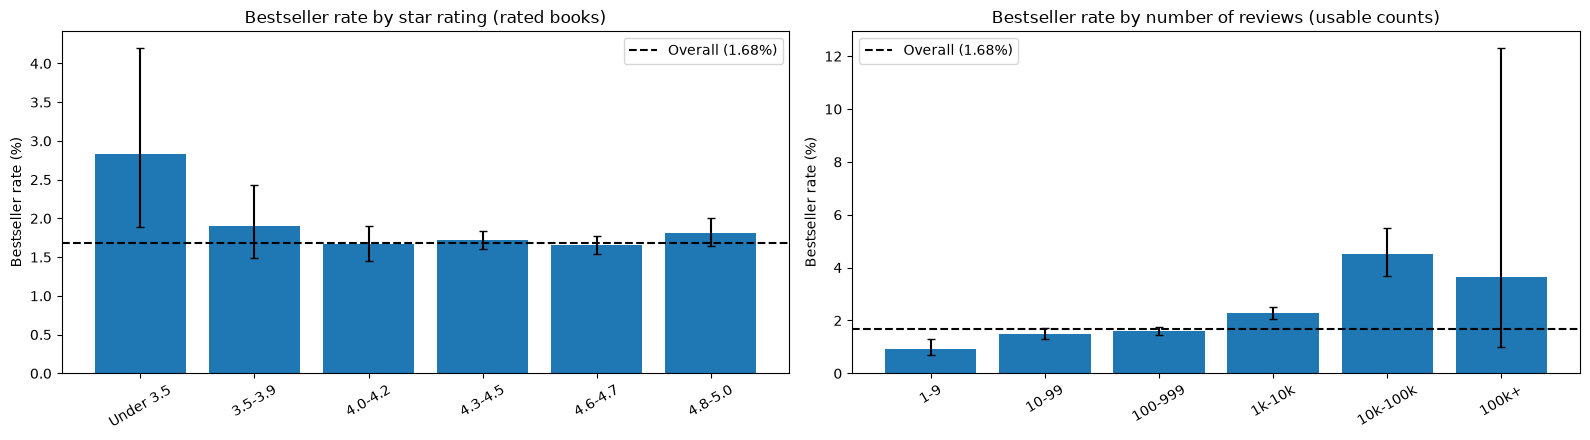

In [12]:
# Do stars and reviews predict bestsellers? (lost review counts from 1e left out)
eda["stars_band"] = pd.cut(eda["stars"], [-0.01, 0, 3.49, 3.99, 4.29, 4.59, 4.79, 5.0],
                           labels=["No ratings (0)", "Under 3.5", "3.5-3.9", "4.0-4.2", "4.3-4.5", "4.6-4.7", "4.8-5.0"])
eda["reviews_band"] = pd.cut(eda["reviews"], [-1, 0, 9, 99, 999, 9_999, 99_999, np.inf],
                             labels=["0", "1-9", "10-99", "100-999", "1k-10k", "10k-100k", "100k+"])
eda["reviews_per_month"] = np.where(eda["age_months"] >= 1,            # out for at least a month before the scrape
                                    eda["reviews"] / eda["age_months"], np.nan)

y = eda["isBestSeller"]
rated = eda["stars"] > 0                                                 # books with a star rating
captured = ~((eda["reviews"] == 0) & rated)                              # leaves out the 61,488 lost counts (1e)

stars_tab = rate_table_ci(eda[rated], "stars_band", sort_by_rate=False)              # rated books only (unrated: see 1e)
reviews_tab = rate_table_ci(eda[captured & rated], "reviews_band", sort_by_rate=False)   # usable counts only
display(stars_tab.round(4))
display(reviews_tab.round(4))

print(f"AUC, stars (rated books):              {single_feature_auc(eda.loc[rated, 'stars'], y[rated]):.3f}")
print(f"AUC, reviews (lost counts left as 0):  {single_feature_auc(eda['reviews'], y):.3f}")
print(f"AUC, reviews (usable counts only):     {single_feature_auc(eda.loc[captured, 'reviews'], y[captured]):.3f}")
speed_ok = captured & eda["reviews_per_month"].notna()                  # usable counts, out for at least a month
print(f"AUC, reviews per month (usable counts): {single_feature_auc(eda.loc[speed_ok, 'reviews_per_month'], y[speed_ok]):.3f}")
print(f"Median reviews (usable counts) | bestsellers: {eda.loc[captured & y, 'reviews'].median():,.0f} "
      f"| the rest: {eda.loc[captured & ~y, 'reviews'].median():,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
rate_bars(axes[0], stars_tab, "Bestseller rate by star rating (rated books)", horizontal=False)
rate_bars(axes[1], reviews_tab, "Bestseller rate by number of reviews (usable counts)", horizontal=False)
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
save(fig, "eda_01g_stars_reviews")

In [13]:
# Duplicates: is the same book listed more than once?
print("Exact duplicate rows:   ", df_raw.duplicated().sum())            # every original column identical
print("Repeated asin:          ", eda["asin"].duplicated().sum())       # same Amazon product ID (extra copies only)
book_key = (eda["title"].str.strip().str.lower() + " | "
            + eda["author"].fillna("").str.strip().str.lower())          # title + author as a "same book" key
print("Repeated title + author:", book_key.duplicated().sum())

rep = eda[eda["asin"].duplicated(keep=False)]                            # every copy of every repeated asin
if len(rep):
    print("\nExample repeated books (compare category_name and isBestSeller):")
    display(rep.sort_values("asin").head(8)[["asin", "title", "category_name", "isBestSeller", "price"]])

Exact duplicate rows:    0
Repeated asin:           0
Repeated title + author: 907


In [14]:
# The 907 title + author repeats: different editions of the same book?
book_key = (eda["title"].str.strip().str.lower() + " | "
            + eda["author"].fillna("").str.strip().str.lower())          # same key as in 1h
same = eda[book_key.duplicated(keep=False)].assign(book_key=book_key)    # every copy of every repeated title + author
print("Rows involved:", len(same), "| distinct books:", same["book_key"].nunique())

per_key = same.groupby("book_key").agg(copies=("asin", "size"),
                                       labels=("isBestSeller", "nunique"),          # 2 = copies disagree
                                       categories=("category_name", "nunique"),     # listed in different categories?
                                       prices=("price", "nunique"))                 # different prices = different editions
print("Labels disagree between copies:", int((per_key["labels"] > 1).sum()))
print("Copies sit in different categories:", int((per_key["categories"] > 1).sum()))
print("Copies have different prices:", int((per_key["prices"] > 1).sum()))
display(same.sort_values("book_key").head(10)[["title", "author", "price", "category_name", "isBestSeller", "publishedDate"]])

Rows involved: 1792 | distinct books: 885
Labels disagree between copies: 52
Copies sit in different categories: 617
Copies have different prices: 734


,title,author,price,category_name,isBestSeller,publishedDate
92900,10-Day Green Smoothie Cleanse: Lose Up to 15 P...,JJ Smith,0.00,"Cookbooks, Food & Wine",False,2015-01-05
93902,10-Day Green Smoothie Cleanse: Lose Up to 15 P...,JJ Smith,13.99,Nonfiction,False,2014-07-01
52673,100 Days of Sunlight,Abbie Emmons,7.99,Teen & Young Adult,False,2019-08-07
129078,100 Days of Sunlight,Abbie Emmons,12.69,Children's eBooks,False,2019-08-07
37028,12 Years A Slave,Solomon Northup,0.00,Biographies & Memoirs,False,2023-09-24
115007,12 Years a Slave,Solomon Northup,0.00,Sports & Outdoors,False,2019-11-26
32940,1776,David McCullough,13.99,Biographies & Memoirs,False,2005-05-24
127449,1776,David McCullough,0.00,Children's eBooks,False,NaN
30068,1984,George Orwell,13.99,Literature & Fiction,False,2013-09-03
43711,1984,George Orwell,0.00,Politics & Social Sciences,False,2023-09-27


##### EDA 2

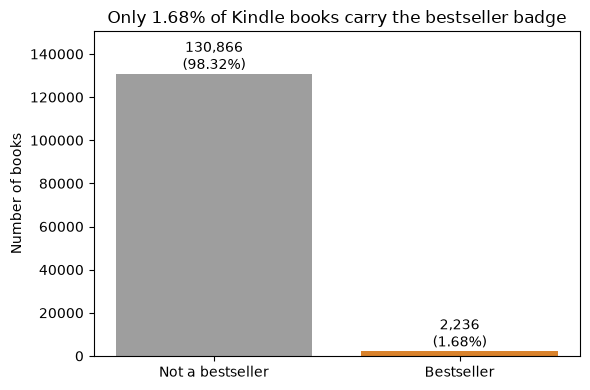

In [15]:
# Class balance chart
counts = eda["isBestSeller"].value_counts().rename({False: "Not a bestseller", True: "Bestseller"})

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color=["#9e9e9e", "#d9822b"])        # grey = not, orange = bestseller
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / len(eda):.2%})", ha="center", va="bottom")   # count and share on each bar
ax.set_ylim(0, counts.max() * 1.15)                                      # headroom so the labels fit
ax.set_ylabel("Number of books")
ax.set_title(f"Only {BASE_RATE:.2%} of Kindle books carry the bestseller badge")
save(fig, "eda_02a_class_balance")

In [16]:
# Follow-up to 1b: which authors look filled in but really mean "missing"?
placeholders = {"", "unknown", "n/a", "na", "none", "null", "-"}       # same list as in 1b
author_clean = eda["author"].str.strip().str.lower()                     # remove spaces, make lowercase
hidden = eda[author_clean.isin(placeholders)]                            # rows whose author is a placeholder

print("Authors that look filled in but mean 'missing':", len(hidden))
display(hidden[["title", "author", "soldBy", "category_name", "isBestSeller"]])   # see the actual books

print("\nThe exact placeholder values used:")
display(hidden["author"].value_counts())                                 # e.g. "Unknown" vs "N/A"

Authors that look filled in but mean 'missing': 2


,title,author,soldBy,category_name,isBestSeller
52276,SMART Recovery Family & Friends Handbook: For ...,none,Amazon.com Services LLC,Teen & Young Adult,False
130685,Rare Mary & Jane Gribbin HIS DARK MATERIALS Al...,unknown,NaN,Children's eBooks,False



The exact placeholder values used:


author
none       1
unknown    1
Name: count, dtype: int64

##### EDA 3

In [17]:
# Category name and id: are they the same information?
id_per_name = eda.groupby("category_name")["category_id"].nunique()      # ids used by each name
name_per_id = eda.groupby("category_id")["category_name"].nunique()      # names used by each id
print("Each name has exactly one id:", bool((id_per_name == 1).all()),
      "| each id has exactly one name:", bool((name_per_id == 1).all()))
print("Distinct names:", eda["category_name"].nunique(), "| distinct ids:", eda["category_id"].nunique())
print("Correlation of category_id (as a number) with bestseller:",
      round(np.corrcoef(eda["category_id"], eda["isBestSeller"])[0, 1], 3))   # meaningless: an id is a label

Each name has exactly one id: True | each id has exactly one name: True
Distinct names: 31 | distinct ids: 31
Correlation of category_id (as a number) with bestseller: -0.004


,books,bestsellers,rate,vs_overall,ci_low,ci_high,category_id,share_of_all_bestsellers
category_name,,,,,,,,
Nonfiction,899,48,0.0534,3.1783,0.0405,0.0701,29,0.0215
Literature & Fiction,4152,186,0.0448,2.6667,0.0389,0.0515,5,0.0832
Science & Math,5955,185,0.0311,1.8493,0.0270,0.0358,15,0.0827
History,2045,63,0.0308,1.8338,0.0242,0.0392,4,0.0282
"Health, Fitness & Dieting",1585,45,0.0284,1.6900,0.0213,0.0378,27,0.0201
Politics & Social Sciences,4207,113,0.0269,1.5989,0.0224,0.0322,14,0.0505
Children's eBooks,5747,152,0.0264,1.5744,0.0226,0.0309,25,0.0680
Religion & Spirituality,4970,129,0.0260,1.5451,0.0219,0.0308,30,0.0577
Teen & Young Adult,5738,148,0.0258,1.5354,0.0220,0.0302,16,0.0662


Association with bestseller: Cramér's V = 0.079 (p = 5.2e-157)
Correlation, category size vs bestseller count: 0.50
Bestsellers per category: median 60, min 4, max 186, spread (CV) 0.71


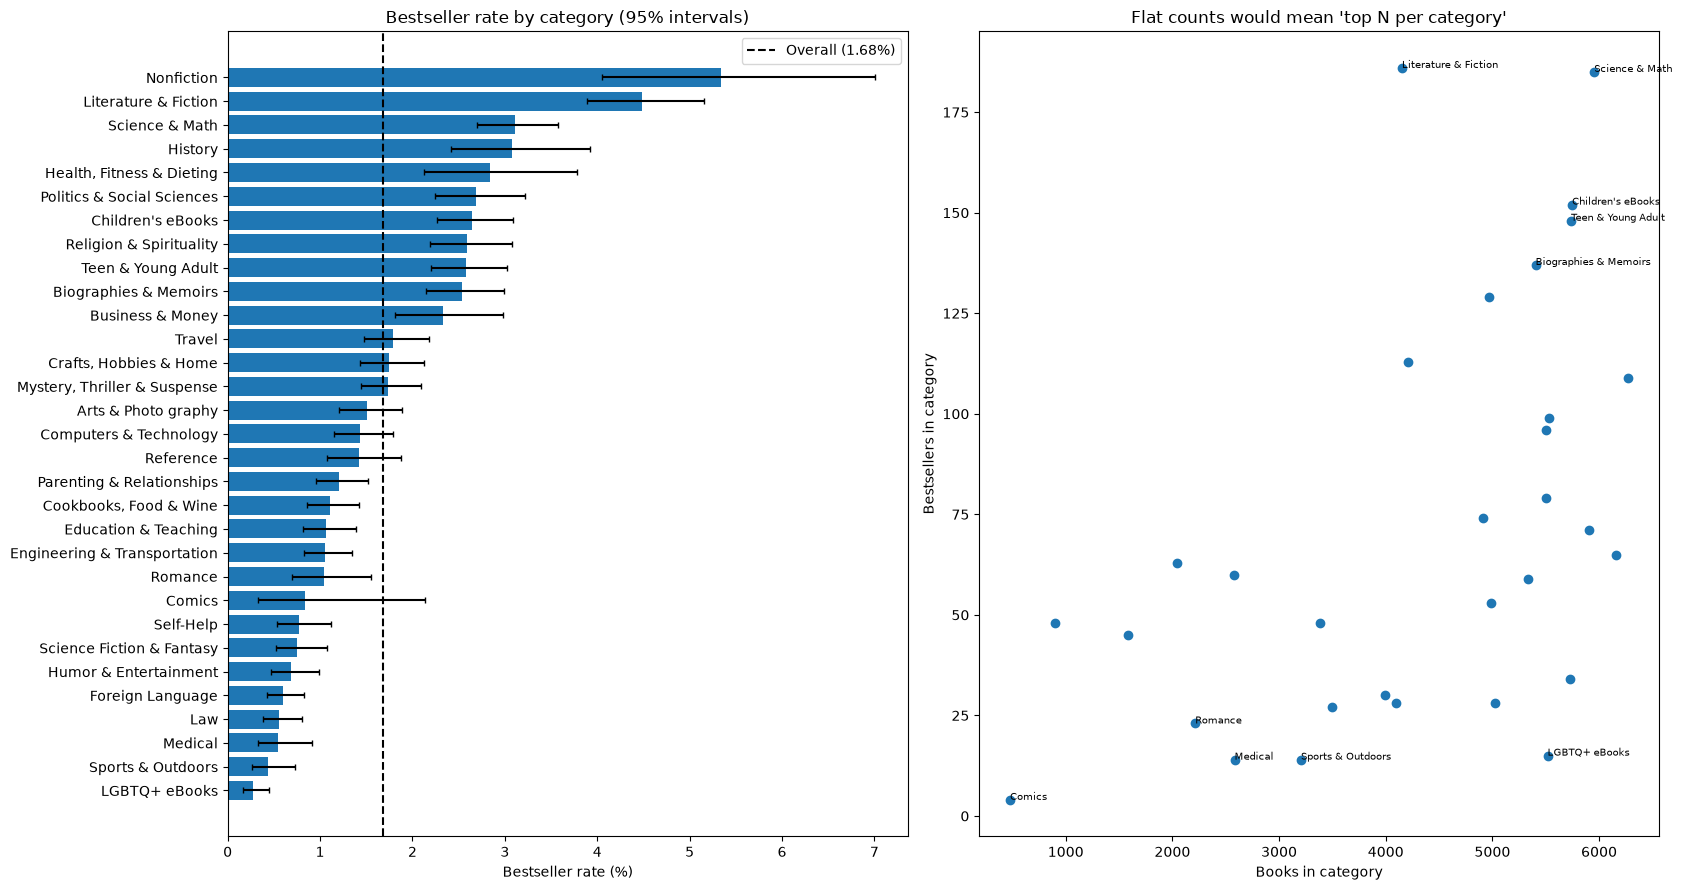

In [18]:
# Bestseller rate per category, and is the badge "top N per category"?

def cramers_v(x, y):
    """Strength of association between two categorical columns: 0 = none, 1 = perfect."""
    table = pd.crosstab(x, y)                                          # counts for every combination
    chi2, p, dof, _ = chi2_contingency(table, correction=False)        # chi-square test of independence
    n = table.to_numpy().sum()                                         # total books in the table
    return np.sqrt(chi2 / (n * (min(table.shape) - 1))), p             # Cramér's V and the p-value


cat_tab = rate_table_ci(eda, "category_name")                          # size, bestsellers, rate and interval
cat_tab["category_id"] = eda.groupby("category_name")["category_id"].first()   # the id, for reference
cat_tab["share_of_all_bestsellers"] = cat_tab["bestsellers"] / cat_tab["bestsellers"].sum()
display(cat_tab.round(4))

v, p = cramers_v(eda["category_name"], eda["isBestSeller"])
r = np.corrcoef(cat_tab["books"], cat_tab["bestsellers"])[0, 1]        # do bigger categories hold more bestsellers?
cv = cat_tab["bestsellers"].std() / cat_tab["bestsellers"].mean()      # spread of the counts (0 = all equal)
print(f"Association with bestseller: Cramér's V = {v:.3f} (p = {p:.1e})")
print(f"Correlation, category size vs bestseller count: {r:.2f}")
print(f"Bestsellers per category: median {cat_tab['bestsellers'].median():.0f}, min {cat_tab['bestsellers'].min()}, "
      f"max {cat_tab['bestsellers'].max()}, spread (CV) {cv:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(17, 9))
rate_bars(axes[0], cat_tab, "Bestseller rate by category (95% intervals)")
axes[1].scatter(cat_tab["books"], cat_tab["bestsellers"])               # one dot per category
ends = cat_tab.sort_values("bestsellers")
for name, row in pd.concat([ends.head(5), ends.tail(5)]).iterrows():  # label the 5 lowest and 5 highest
    axes[1].annotate(name[:25], (row["books"], row["bestsellers"]), fontsize=7)
axes[1].set_xlabel("Books in category")
axes[1].set_ylabel("Bestsellers in category")
axes[1].set_title("Flat counts would mean 'top N per category'")
save(fig, "eda_03_category")

##### EDA 4

,books,bestsellers,rate,vs_overall,ci_low,ci_high
price_band,,,,,,
Free,4066,92,0.0226,1.3469,0.0185,0.0277
$0.01-0.99,1780,120,0.0674,4.0130,0.0567,0.0800
$1-2.98,1710,128,0.0749,4.4558,0.0633,0.0883
$2.99-4.99,26822,721,0.0269,1.6001,0.0250,0.0289
$5-9.99,42652,663,0.0155,0.9253,0.0144,0.0168
$10-14.99,27181,333,0.0123,0.7293,0.0110,0.0136
$15+,28891,179,0.0062,0.3688,0.0054,0.0072


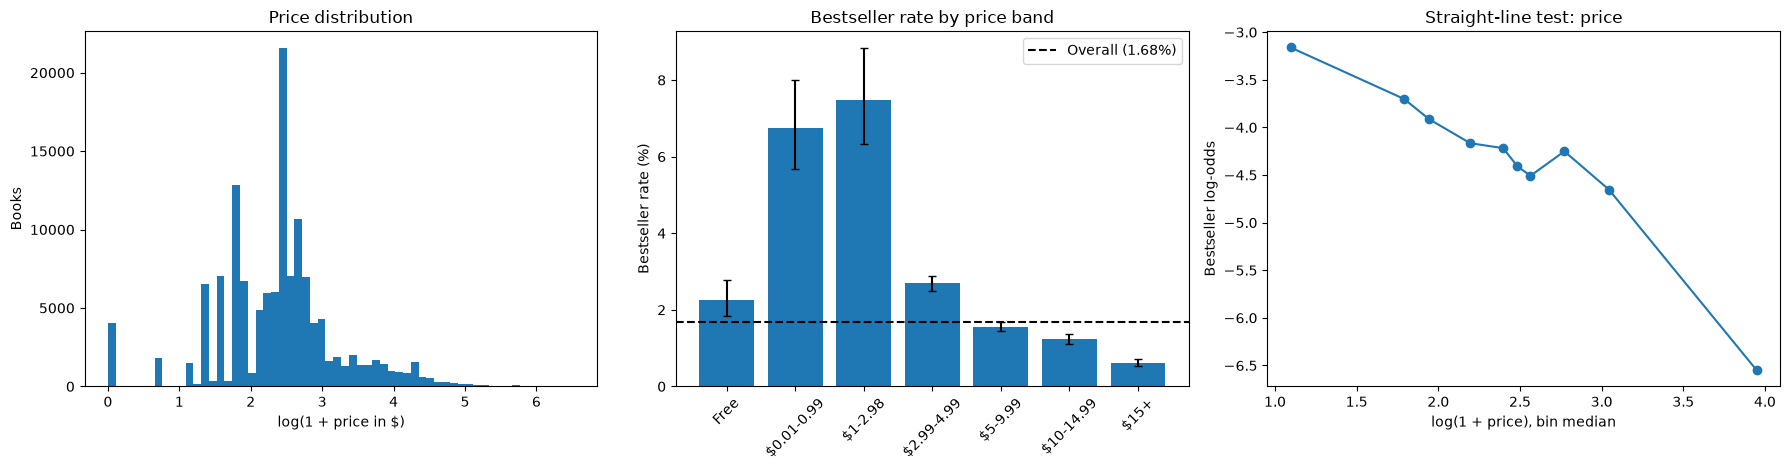

Most common prices:


,books
price,
9.99,17122
4.99,12246
3.99,6668
2.99,6455
5.99,6009
11.99,5456
12.99,5184
14.99,4537
7.99,4390


Share of books at one of these points: 46.1%


,books,bestsellers,rate,vs_overall
price,,,,
0.99,1776,119,0.0670,3.99
1.99,1424,109,0.0765,4.56
2.99,6455,230,0.0356,2.12
3.99,6668,197,0.0295,1.76
4.99,12246,260,0.0212,1.26
5.99,6009,112,0.0186,1.11
9.99,17122,247,0.0144,0.86
12.99,5184,51,0.0098,0.59
14.99,4537,80,0.0176,1.05


In [19]:
# Price overall: distribution, bands and the straight-line test
eda["log_price"] = np.log1p(eda["price"])                              # log(1 + price): tames the long right tail (1c)
eda["price_band"] = pd.cut(eda["price"], [-0.01, 0, 0.99, 2.98, 4.99, 9.99, 14.99, np.inf],
                           labels=["Free", "$0.01-0.99", "$1-2.98", "$2.99-4.99", "$5-9.99", "$10-14.99", "$15+"])


def log_odds(rate):
    """Convert a rate into log-odds, the scale logistic regression works on."""
    r = np.clip(rate, 1e-4, 1 - 1e-4)                                  # keeps log() away from 0 for empty groups
    return np.log(r / (1 - r))                                         # log(rate / (1 - rate))


def logodds_by_bin(df, col, bins=10):
    """Log-odds of being a bestseller in each of ~10 equal-sized bins of a numeric column."""
    d = df[[col, "isBestSeller"]].dropna()                             # only rows where this feature exists
    b = pd.qcut(d[col], bins, duplicates="drop")                        # equal-sized bins (fewer if many ties)
    g = d.groupby(b, observed=True).agg(x=(col, "median"),             # where each bin sits on the x-axis
                                        rate=("isBestSeller", "mean"), # bestseller rate in the bin
                                        books=(col, "size"))           # how many books the bin holds
    g["log_odds"] = log_odds(g["rate"])                                # the rate on the log-odds scale
    return g


band_tab = rate_table_ci(eda, "price_band", sort_by_rate=False)         # keep the bands in price order
display(band_tab.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].hist(eda["log_price"], bins=60)                                 # shape of prices on a log scale
axes[0].set_xlabel("log(1 + price in $)")
axes[0].set_ylabel("Books")
axes[0].set_title("Price distribution")

rate_bars(axes[1], band_tab, "Bestseller rate by price band", horizontal=False)
axes[1].tick_params(axis="x", rotation=45)

g = logodds_by_bin(eda, "log_price")                                    # the straight-line test
axes[2].plot(g["x"], g["log_odds"], marker="o")
axes[2].set_xlabel("log(1 + price), bin median")
axes[2].set_ylabel("Bestseller log-odds")
axes[2].set_title("Straight-line test: price")
save(fig, "eda_04a_price")

# Exact price points
print("Most common prices:")
display(eda["price"].round(2).value_counts().head(10).to_frame("books"))
points = [0.99, 1.99, 2.99, 3.99, 4.99, 5.99, 9.99, 12.99, 14.99]
at_point = eda[eda["price"].round(2).isin(points)]                      # books priced exactly at a common point
print(f"Share of books at one of these points: {len(at_point) / len(eda):.1%}")
display(rate_table(at_point, at_point["price"].round(2), sort_by_rate=False).round({"rate": 4, "vs_overall": 2}))

,count,mean,std,min,10%,25%,50%,75%,90%,max
isBestSeller,,,,,,,,,,
False,130866.0,15.26,22.41,0.0,2.99,4.99,9.99,14.99,30.99,682.0
True,2236.0,7.68,6.26,0.0,1.99,2.99,5.99,9.99,14.99,66.0


Free books: 4,066 | bestsellers among them: 92 (rate 2.26%)
Paid books: bestseller rate 1.66%
Single-feature AUC, price (all books): 0.341


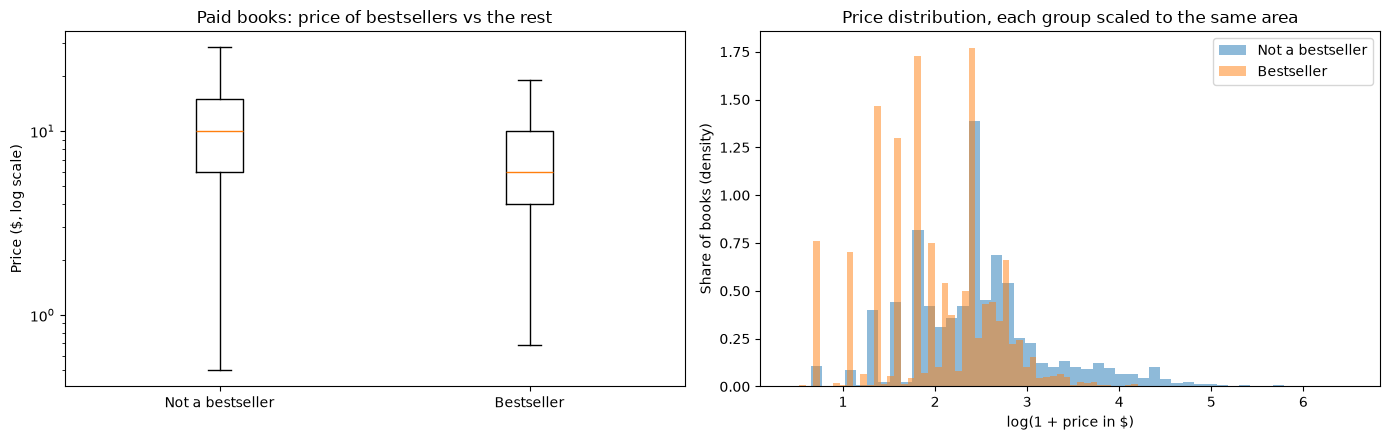

In [20]:
# Bestsellers vs the rest: how do their prices compare? (free books checked separately)
display(eda.groupby("isBestSeller")["price"]
        .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2))       # price summary for each group

free = eda["price"] == 0                                                 # free books
print(f"Free books: {free.sum():,} | bestsellers among them: {(free & eda['isBestSeller']).sum():,} "
      f"(rate {eda.loc[free, 'isBestSeller'].mean():.2%})")
print(f"Paid books: bestseller rate {eda.loc[~free, 'isBestSeller'].mean():.2%}")
print(f"Single-feature AUC, price (all books): {single_feature_auc(eda['price'], eda['isBestSeller']):.3f}")

paid = eda[~free]                                                        # paid books only, for the charts
not_best = paid.loc[~paid["isBestSeller"], "price"]
is_best = paid.loc[paid["isBestSeller"], "price"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].boxplot([not_best, is_best], showfliers=False)                   # boxes = middle 50%, line = median
axes[0].set_xticks([1, 2], ["Not a bestseller", "Bestseller"])
axes[0].set_yscale("log")                                                # log scale: prices are heavily skewed
axes[0].set_ylabel("Price ($, log scale)")
axes[0].set_title("Paid books: price of bestsellers vs the rest")

axes[1].hist(np.log1p(not_best), bins=50, density=True, alpha=0.5, label="Not a bestseller")   # density = shapes comparable
axes[1].hist(np.log1p(is_best), bins=50, density=True, alpha=0.5, label="Bestseller")
axes[1].set_xlabel("log(1 + price in $)")
axes[1].set_ylabel("Share of books (density)")
axes[1].set_title("Price distribution, each group scaled to the same area")
axes[1].legend()
save(fig, "eda_04b_price_by_group")

,books,median,p90,max,median_not_best,median_best,best_vs_not
category_name,,,,,,,
Medical,2583,22.49,84.73,543.99,22.78,4.99,0.22
Computers & Technology,5504,19.92,43.99,191.49,19.99,6.99,0.35
Law,5027,18.95,112.00,682.00,18.99,5.49,0.29
Education & Teaching,4986,17.25,57.38,200.00,17.52,4.99,0.28
Science & Math,5955,14.99,74.99,636.99,15.00,9.99,0.67
Engineering & Transportation,6162,14.99,71.18,308.75,14.99,9.99,0.67
Business & Money,2577,14.99,65.00,305.90,14.99,7.99,0.53
Politics & Social Sciences,4207,12.99,41.99,322.00,12.99,7.99,0.62
Arts & Photo graphy,4916,11.99,28.60,218.00,11.99,6.95,0.58


Bestsellers are cheaper in 27 of 31 categories


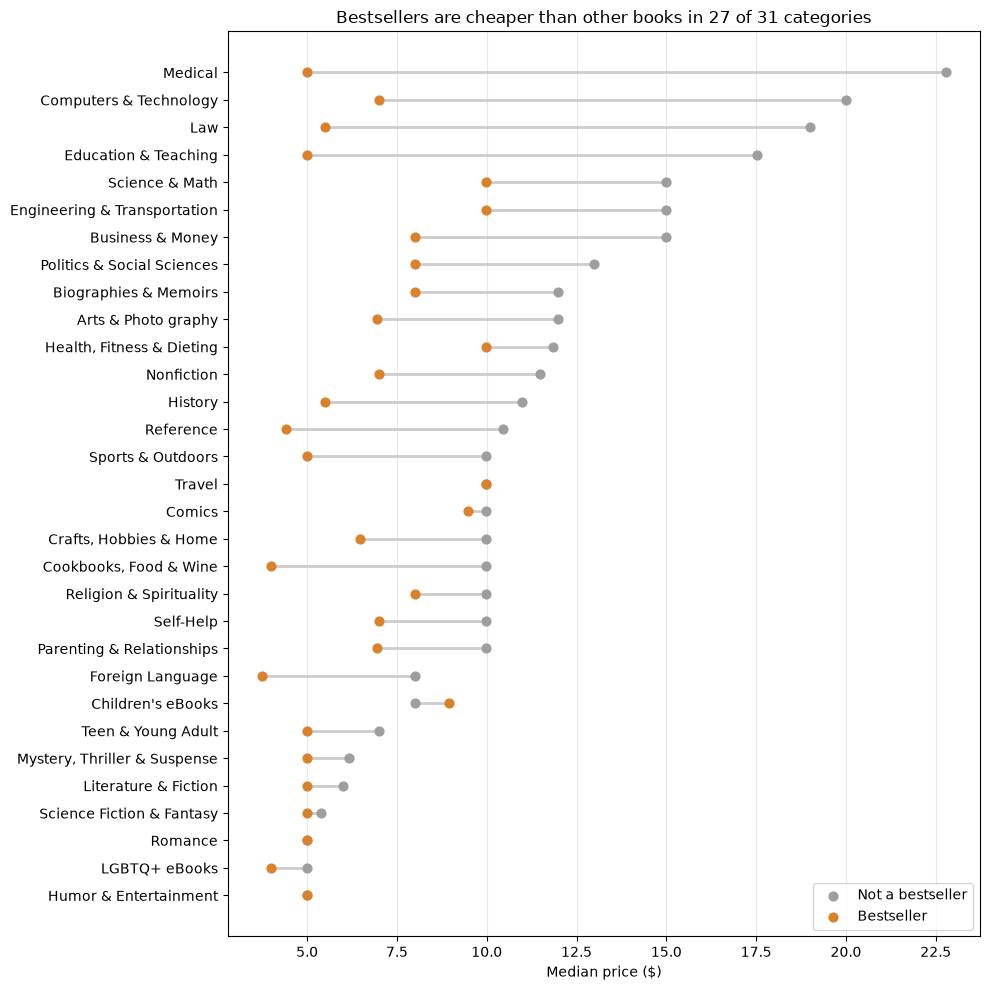

In [21]:
# Price profile of every category, with bestseller and non-bestseller medians side by side
profile = eda.groupby("category_name")["price"].agg(
    books="size", median="median", p90=lambda s: s.quantile(0.9), max="max")       # typical, high-end and top price
med = eda.pivot_table(index="category_name", columns="isBestSeller", values="price", aggfunc="median")
profile["median_not_best"] = med[False]                                  # median price of ordinary books
profile["median_best"] = med[True]                                       # median price of bestsellers (NaN if none)
profile["best_vs_not"] = profile["median_best"] / profile["median_not_best"]   # below 1 = bestsellers cost less
display(profile.sort_values("median", ascending=False).round(2))

cheaper = (profile["best_vs_not"] < 1).sum()                             # categories where bestsellers cost less
print(f"Bestsellers are cheaper in {cheaper} of {profile['best_vs_not'].notna().sum()} categories")

# Chart: dumbbell, one row per category (grey = ordinary books, orange = bestsellers)
dots = profile.sort_values("median_not_best")                            # cheapest category at the bottom
y = np.arange(len(dots))
fig, ax = plt.subplots(figsize=(10, 10))
ax.hlines(y, dots["median_best"], dots["median_not_best"], color="#cccccc", lw=2)   # line joining the two medians
ax.scatter(dots["median_not_best"], y, s=40, color="#9e9e9e", label="Not a bestseller", zorder=3)
ax.scatter(dots["median_best"], y, s=40, color="#d9822b", label="Bestseller", zorder=3)
ax.set_yticks(y, dots.index)
ax.set_xlabel("Median price ($)")
ax.set_title(f"Bestsellers are cheaper than other books in {cheaper} of {len(dots)} categories")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")
save(fig, "eda_04c_price_in_category")

In [22]:
# The 3 most expensive books in every category: are any of them bestsellers?
top3 = (eda.sort_values("price", ascending=False)                        # most expensive first
          .groupby("category_name").head(3)                              # first 3 rows of each category
          .sort_values(["category_name", "price"], ascending=[True, False])
          [["category_name", "title", "author", "price", "isBestSeller"]])
print(f"Bestsellers among the 3 most expensive books of each category: {top3['isBestSeller'].sum()} of {len(top3)}")
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 60):   # show every row, not a shortened list
    display(top3)

Bestsellers among the 3 most expensive books of each category: 0 of 93


,category_name,title,author,price,isBestSeller
79437,Arts & Photo graphy,The Architect's Handbook of Professional Practice,American Institute of Architects,218.00,False
81751,Arts & Photo graphy,The History of Art: A Global View: Prehistory to the Pre...,Jean Robertson,140.00,False
82302,Arts & Photo graphy,The Beatles Encyclopedia [2 volumes]: Everything Fab Fou...,Kenneth Womack,126.99,False
35550,Biographies & Memoirs,Cyber Crime and Cyber Terrorism (What's New in Criminal ...,Robert W. Taylor,74.99,False
38061,Biographies & Memoirs,Organized Crime (What's New in Criminal Justice),Michael D. Lyman,74.99,False
33661,Biographies & Memoirs,"William L. Shirer: Twentieth Century Journey: The Start,...",William L. Shirer,53.99,False
119926,Business & Money,Commentaries and Cases on the Law of Business Organizati...,William T. Allen,305.90,False
120890,Business & Money,"The Law of Governance, Risk Management and Compliance (A...",Geoffrey P. Miller,250.79,False
121709,Business & Money,Securities Regulation: Cases and Materials (Aspen Casebo...,James D. Cox,224.52,False
132614,Children's eBooks,"World of Children, The (Mypsychlab)",Joan Cook,213.32,False


##### EDA 5

In [23]:
# Who sells the books? Look at every seller BEFORE grouping anything
seller = eda["soldBy"].fillna("Unknown")                                 # the 9,233 missing sellers (1a) shown as "Unknown"
print("Distinct sellers:", eda["soldBy"].nunique())
sizes = seller.value_counts()                                            # books per seller, biggest first
print(f"Sellers with under 50 books: {(sizes < 50).sum()}, holding {sizes[sizes < 50].sum():,} books")
print(f"The 20 biggest sellers hold {sizes.head(20).sum() / len(eda):.1%} of all books")

all_sellers = rate_table_ci(eda, seller, sort_by_rate=False)              # books, bestsellers, rate and interval per seller
all_sellers = all_sellers.sort_values("books", ascending=False)          # biggest seller first
with pd.option_context("display.max_rows", 100):                         # show every seller, not a shortened list
    display(all_sellers.round(4))

Distinct sellers: 49
Sellers with under 50 books: 23, holding 324 books
The 20 biggest sellers hold 99.2% of all books


,books,bestsellers,rate,vs_overall,ci_low,ci_high
soldBy,,,,,,
Amazon.com Services LLC,84759,1588,0.0187,1.1153,0.0178,0.0197
Unknown,9233,180,0.0195,1.1605,0.0169,0.0225
Random House LLC,5872,51,0.0087,0.5170,0.0066,0.0114
Hachette Book Group,4736,59,0.0125,0.7416,0.0097,0.0160
Penguin Group (USA) LLC,4385,53,0.0121,0.7195,0.0093,0.0158
HarperCollins Publishers,4328,70,0.0162,0.9628,0.0128,0.0204
Macmillan,3147,39,0.0124,0.7377,0.0091,0.0169
Simon and Schuster Digital Sales Inc,3047,57,0.0187,1.1136,0.0145,0.0242
Penguin Random House Publisher Services,2390,27,0.0113,0.6725,0.0078,0.0164


,seller names in this group
publisher_grp,
Academic publishers,"[Pearson Education,Inc., JOHN WILEY AND SONS INC, Cengage Learning, Macmillan Higher Education]"
Amazon,"[Amazon.com Services LLC, Amazon.com, Amazon Digital Services LLC HN, Amazon Digital Services LLC GU, Amazon Digital Services LLC MK]"
De Marque,[De Marque]
Hachette,[Hachette Book Group]
Harlequin,[Harlequin Digital Sales Corp.]
HarperCollins,"[HarperCollins Publishers, HarperCollins Publishing]"
Macmillan,[Macmillan]
Other sellers,"[W. W. Norton & Company, Harper Collins, RH AU, Disney Book Group, INTERFORUM, Volumen, EDIGITA, Pottermore, Gallimard Lt., Flammarion Lt., GeMS SpA, Yen Press LLC, Games Workshop, Scholastic Trad..."
Penguin Random House,"[Penguin Group (USA) LLC, Random House LLC, Penguin Random House Publisher Services, PRH UK, Penguin Random House Australia Pty Ltd, Random House ZA, Random House NZ, Random House India]"


,books,bestsellers,rate,vs_overall,ci_low,ci_high
publisher_grp,,,,,,
De Marque,194,32,0.1649,9.8189,0.1193,0.2236
Unknown,9233,180,0.0195,1.1605,0.0169,0.0225
Amazon,84774,1588,0.0187,1.1151,0.0178,0.0197
HarperCollins,5460,100,0.0183,1.0902,0.0151,0.0222
Other sellers,1028,18,0.0175,1.0423,0.0111,0.0275
Simon & Schuster,4795,79,0.0165,0.9807,0.0132,0.0205
Hachette,4736,59,0.0125,0.7416,0.0097,0.0160
Macmillan,3147,39,0.0124,0.7377,0.0091,0.0169
Penguin Random House,13086,131,0.0100,0.5959,0.0084,0.0119


Cramér's V, publisher_grp: 0.056 (p = 1.5e-83)


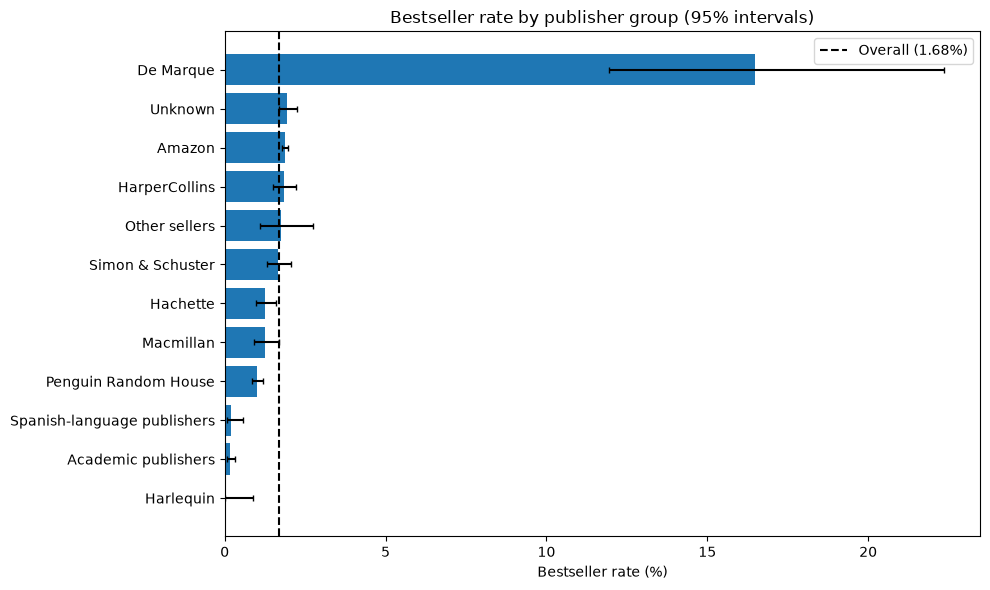

In [24]:
# Group the sellers, based on what 5a showed
# Reasons (first check): (1) one company appears under several spellings or imprints,
# (2) textbook publishers behave alike, (3) Spanish-language publishers behave alike,
# (4) many small sellers are too small to judge alone.
def publisher_group(s):
    """Parent company from the soldBy text. Rules are checked top to bottom and the first match wins."""
    if pd.isna(s):
        return "Unknown"                                                 # seller missing (1a)
    s = s.lower()
    rules = [("grupo editorial", "Spanish-language publishers"),         # checked before "penguin" (PRH Grupo Editorial)
             ("planeta", "Spanish-language publishers"),
             ("higher education", "Academic publishers"),                # checked before "macmillan" (Macmillan Higher Ed)
             ("wiley", "Academic publishers"), ("pearson", "Academic publishers"), ("cengage", "Academic publishers"),
             ("amazon", "Amazon"), ("de marque", "De Marque"), ("harlequin", "Harlequin"),
             ("penguin", "Penguin Random House"), ("random house", "Penguin Random House"), ("prh", "Penguin Random House"),
             ("harpercollins", "HarperCollins"), ("simon", "Simon & Schuster"),
             ("macmillan", "Macmillan"), ("hachette", "Hachette")]
    for key, name in rules:
        if key in s:
            return name
    return "Other sellers"                                               # the small sellers from 5a


eda["publisher_grp"] = eda["soldBy"].map(publisher_group)

# Check the grouping: which original seller names ended up in each group?
with pd.option_context("display.max_colwidth", 200):
    display(eda.groupby("publisher_grp")["soldBy"].unique().to_frame("seller names in this group"))

pub_tab = rate_table_ci(eda, "publisher_grp")                            # rate per group, highest first
display(pub_tab.round(4))
v, p = cramers_v(eda["publisher_grp"], eda["isBestSeller"])
print(f"Cramér's V, publisher_grp: {v:.3f} (p = {p:.1e})")

fig, ax = plt.subplots(figsize=(10, 6))
rate_bars(ax, pub_tab, "Bestseller rate by publisher group (95% intervals)")
save(fig, "eda_05b_publisher_groups")

In [25]:
# Follow-up to second check in section: why are 16% of De Marque's books bestsellers, and what does that do to free books (4a)?
dm = eda[eda["publisher_grp"] == "De Marque"]                            # De Marque's books only
print("De Marque books:", len(dm), "| bestsellers:", int(dm["isBestSeller"].sum()),
      "| free:", int((dm["price"] == 0).sum()), "| in KU:", int(dm["isKindleUnlimited"].sum()))
with pd.option_context("display.max_colwidth", 60):
    display(dm.loc[dm["isBestSeller"], ["title", "author", "price", "category_name"]].head(15))   # what its bestsellers are

free = eda["price"] == 0                                                 # free books
is_dm = eda["publisher_grp"] == "De Marque"
print("\nFree bestsellers:", int((free & eda["isBestSeller"]).sum()),
      "| of which De Marque:", int((free & is_dm & eda["isBestSeller"]).sum()))
print(f"Free-book bestseller rate | all free books: {eda.loc[free, 'isBestSeller'].mean():.2%} "
      f"| without De Marque: {eda.loc[free & ~is_dm, 'isBestSeller'].mean():.2%} ({(free & ~is_dm).sum():,} books)")

De Marque books: 194 | bestsellers: 32 | free: 113 | in KU: 0


,title,author,price,category_name
51,Anne Of Green Gables Complete 8 Book Set,L. M. Montgomery,1.99,Parenting & Relationships
146,Anne Of Green Gables: Complete 8-Book Box Set,L. M. Montgomery,1.99,Parenting & Relationships
23591,Wuthering Heights,Emily Brontë,0.00,"Crafts, Hobbies & Home"
31025,Think and Grow Rich,Napoleon Hill,2.85,Literature & Fiction
32238,50 Masterpieces you have to read before you die vol: 1,Joseph Conrad,1.99,Literature & Fiction
43982,Meditations,Marcus Aurelius,0.00,Politics & Social Sciences
44624,The Jungle,Upton Sinclair,0.00,Politics & Social Sciences
45436,The Complete Essays,M.E. De Montaigne,0.00,Politics & Social Sciences
45547,The Constitution of the United States of America: The De...,Founding Fathers,0.00,Politics & Social Sciences
45818,The Souls of Black Folk: The Original Unabridged and Com...,W.E.B. Du Bois,0.00,Politics & Social Sciences



Free bestsellers: 92 | of which De Marque: 25
Free-book bestseller rate | all free books: 2.26% | without De Marque: 1.69% (3,953 books)


,books,bestsellers,rate,vs_overall,ci_low,ci_high
isKindleUnlimited,,,,,,
False,97287,771,0.0079,0.4718,0.0074,0.0085
True,35815,1465,0.0409,2.4349,0.0389,0.0430


KU share of all books: 26.9% | of bestsellers: 65.5%
Cramér's V, isKindleUnlimited: 0.114 (p = 0.0e+00)
Cramér's V, publisher_grp: 0.056 (p = 1.5e-83)


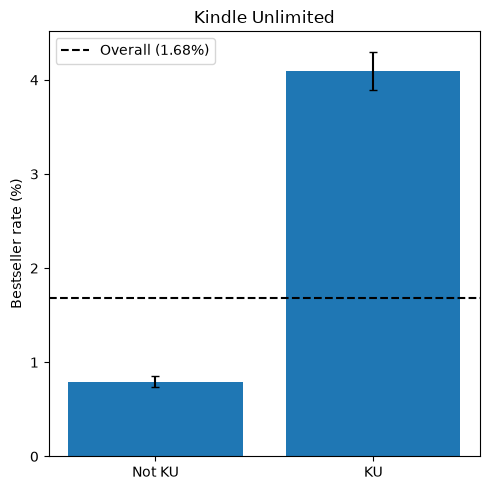

In [26]:
# Kindle Unlimited
ku_tab = rate_table_ci(eda, "isKindleUnlimited", sort_by_rate=False)
display(ku_tab.round(4))
print(f"KU share of all books: {eda['isKindleUnlimited'].mean():.1%} | "
      f"of bestsellers: {eda.loc[eda['isBestSeller'], 'isKindleUnlimited'].mean():.1%}")

for col in ["isKindleUnlimited", "publisher_grp"]:                       # strength of each link, on the same scale
    v, p = cramers_v(eda[col], eda["isBestSeller"])
    print(f"Cramér's V, {col}: {v:.3f} (p = {p:.1e})")

fig, ax = plt.subplots(figsize=(5, 5))
rate_bars(ax, ku_tab.rename(index={False: "Not KU", True: "KU"}), "Kindle Unlimited", horizontal=False)
save(fig, "eda_05d_ku")

,KU share,price: not KU,price: KU,rate: not KU,rate: KU,KU books
publisher_grp,,,,,,
Amazon,0.3857,10.99,4.99,0.0060,0.0390,32700
Unknown,0.2110,6.99,4.34,0.0141,0.0395,1948
Macmillan,0.1265,11.99,11.99,0.0073,0.0477,398
Other sellers,0.1070,9.99,9.99,0.0054,0.1182,110
Harlequin,0.0818,9.99,6.74,0.0000,0.0000,36
HarperCollins,0.0593,12.99,12.99,0.0099,0.1512,324
Simon & Schuster,0.0540,13.99,11.99,0.0115,0.1042,259
Hachette,0.0082,11.99,9.99,0.0115,0.1282,39
Spanish-language publishers,0.0006,8.99,4.99,0.0019,0.0000,1


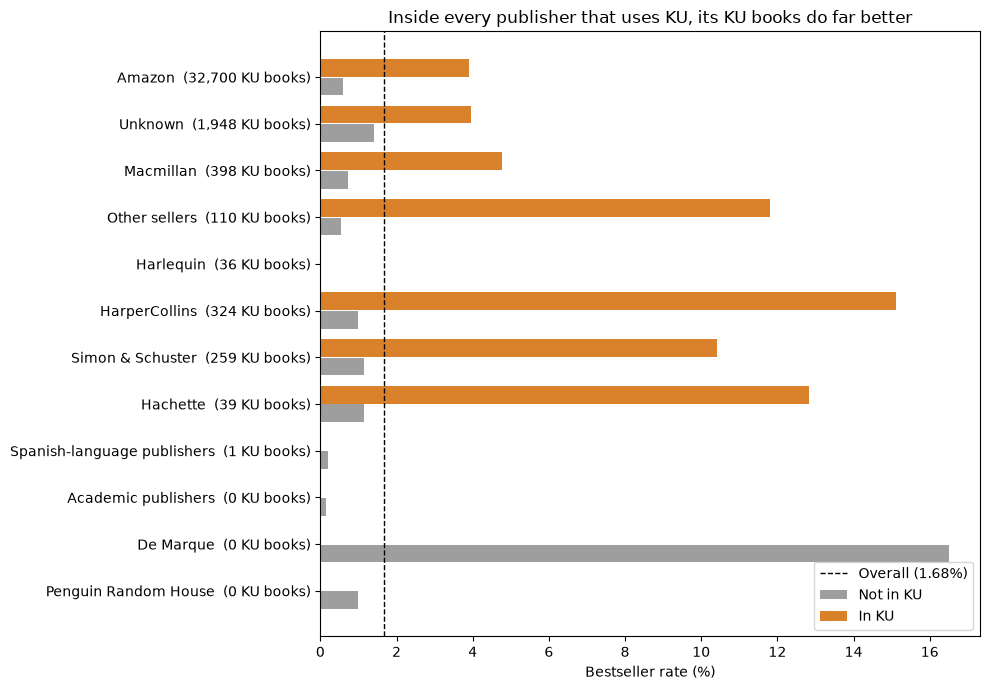

In [27]:
# How publisher, KU and price overlap: one row per publisher group
grp, ku = eda["publisher_grp"], eda["isKindleUnlimited"]
ku_share = pd.crosstab(grp, ku, normalize="index")[True]                 # share of the group's books in KU
price = eda.groupby([grp, ku])["price"].median().unstack()               # median price outside / inside KU
rate = pd.crosstab(grp, ku, values=eda["isBestSeller"], aggfunc="mean")  # bestseller rate outside / inside KU
books = pd.crosstab(grp, ku)                                             # number of books outside / inside KU

overlap = pd.DataFrame({"KU share": ku_share,
                        "price: not KU": price[False], "price: KU": price[True],
                        "rate: not KU": rate[False], "rate: KU": rate[True],
                        "KU books": books[True]})
overlap = overlap.sort_values("KU share", ascending=False)
display(overlap.round(4))                                                # NaN = the group has no KU books

# Chart: paired bars per publisher group (grey = outside KU, orange = inside KU)
plot = overlap.iloc[::-1]                                                # highest KU share at the top
y = np.arange(len(plot))
labels = [f"{g}  ({int(n):,} KU books)" for g, n in zip(plot.index, plot["KU books"])]   # how many KU books each rate rests on
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(y - 0.2, plot["rate: not KU"] * 100, height=0.38, color="#9e9e9e", label="Not in KU")
ax.barh(y + 0.2, plot["rate: KU"].fillna(0) * 100, height=0.38, color="#d9822b", label="In KU")
ax.axvline(BASE_RATE * 100, ls="--", color="black", lw=1, label=f"Overall ({BASE_RATE:.2%})")
ax.set_yticks(y, labels)
ax.set_xlabel("Bestseller rate (%)")
ax.set_title("Inside every publisher that uses KU, its KU books do far better")
ax.legend(loc="lower right")
save(fig, "eda_05e_publisher_ku")

Overall:                     KU 4.09% vs not KU 0.79% (gap +3.30%)
Inside categories (weighted): gap +5.13%
Categories where KU's rate is higher: 31 of 31


,KU share,rate KU,rate not KU
category_name,,,
Romance,0.7439,0.0140,0.0000
LGBTQ+ eBooks,0.7080,0.0036,0.0006
Science Fiction & Fantasy,0.5937,0.0118,0.0012
Literature & Fiction,0.5667,0.0701,0.0117
"Mystery, Thriller & Suspense",0.4906,0.0312,0.0041
Humor & Entertainment,0.4618,0.0116,0.0027
Teen & Young Adult,0.4326,0.0479,0.0089
Religion & Spirituality,0.3396,0.0427,0.0174
Comics,0.3013,0.0278,0.0000


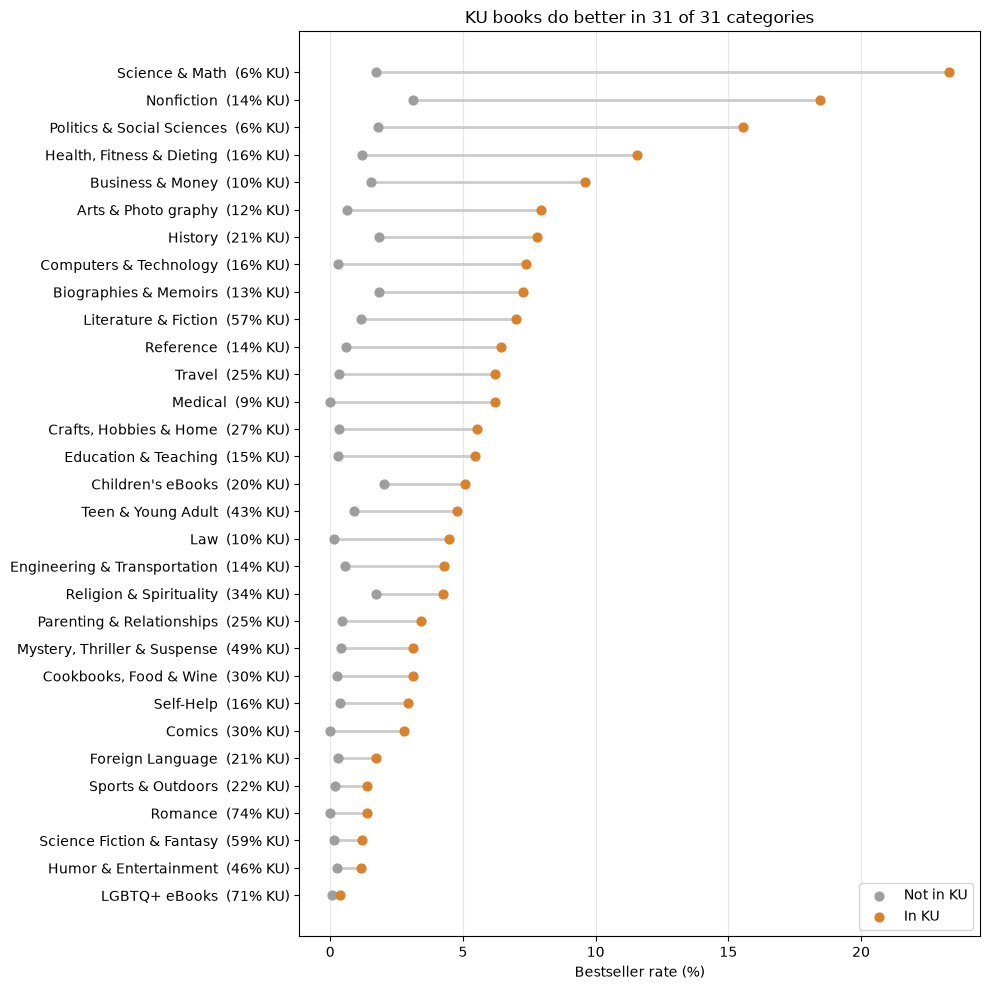

In [28]:
# Simpson's paradox test: does KU's effect survive inside each category?
g = (eda.groupby(["category_name", "isKindleUnlimited"])["isBestSeller"]
        .agg(["mean", "size"])
        .unstack())                                                      # columns: (mean|size) x (False|True)
rate_ku, rate_not = g[("mean", True)], g[("mean", False)]                # rate in each category, with / without KU
size = g[("size", True)] + g[("size", False)]                            # books per category
inside_gap = ((rate_ku - rate_not) * size).sum() / size.sum()            # KU's gap inside categories, weighted by size

overall = eda.groupby("isKindleUnlimited")["isBestSeller"].mean()
print(f"Overall:                     KU {overall[True]:.2%} vs not KU {overall[False]:.2%} "
      f"(gap {overall[True] - overall[False]:+.2%})")
print(f"Inside categories (weighted): gap {inside_gap:+.2%}")
higher = (rate_ku > rate_not).sum()
print(f"Categories where KU's rate is higher: {higher} of {rate_ku.notna().sum()}")

per_cat = pd.DataFrame({"KU share": g[("size", True)] / size,
                        "rate KU": rate_ku,
                        "rate not KU": rate_not}).sort_values("KU share", ascending=False)
display(per_cat.round(4))

# Chart: dumbbell, one row per category (grey = outside KU, orange = inside KU)
dots = per_cat.sort_values("rate KU")                                    # highest KU rate at the top
y = np.arange(len(dots))
fig, ax = plt.subplots(figsize=(10, 10))
ax.hlines(y, dots["rate not KU"] * 100, dots["rate KU"] * 100, color="#cccccc", lw=2)   # line joining the two rates
ax.scatter(dots["rate not KU"] * 100, y, s=40, color="#9e9e9e", label="Not in KU", zorder=3)
ax.scatter(dots["rate KU"] * 100, y, s=40, color="#d9822b", label="In KU", zorder=3)
ax.set_yticks(y, [f"{c}  ({s:.0%} KU)" for c, s in zip(dots.index, dots["KU share"])])   # category and its KU share
ax.set_xlabel("Bestseller rate (%)")
ax.set_title(f"KU books do better in {higher} of {rate_ku.notna().sum()} categories")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")
save(fig, "eda_05f_ku_by_category")

##### EDA 6

In [29]:
# Which authors come up most among bestsellers?
best = eda[eda["isBestSeller"]]                                         # bestseller rows only
auth = best.groupby("author").agg(bestseller_listings=("asin", "size"),           # rows, including repeat listings
                                  distinct_bestsellers=("asin", "nunique"),       # different books
                                  categories=("category_name", "nunique"))        # categories they appear in
top_authors = auth.sort_values(["distinct_bestsellers", "bestseller_listings"], ascending=False).head(20)

their_books = eda[eda["author"].isin(top_authors.index)]                # every book by these 20 authors
extra = their_books.groupby("author").agg(
    books_in_data=("asin", "nunique"),                                  # all their distinct books
    ku_share=("isKindleUnlimited", "mean"),                             # share of their books in KU
    median_price=("price", "median"),
    main_seller=("soldBy", lambda s: s.mode().iat[0] if s.notna().any() else "Unknown"))   # their most common seller
top_authors = top_authors.join(extra)
top_authors["author_rate"] = top_authors["distinct_bestsellers"] / top_authors["books_in_data"]   # share of their books that are bestsellers
display(top_authors.round(3))

,bestseller_listings,distinct_bestsellers,categories,books_in_data,ku_share,median_price,main_seller,author_rate
author,,,,,,,,
J.K. Rowling,16,16,4,113,0.885,8.99,Pottermore,0.142
DK,10,10,5,155,0.000,9.99,Penguin Group (USA) LLC,0.065
Captivating History,7,7,2,120,0.917,2.99,Amazon.com Services LLC,0.058
Freida McFadden,7,7,2,26,0.846,3.99,Amazon.com Services LLC,0.269
Paul Levine,7,7,3,14,0.929,5.99,Amazon.com Services LLC,0.500
C.W. Farnsworth,6,6,5,15,1.000,3.99,Amazon.com Services LLC,0.400
Explore ToWin,6,6,2,19,0.895,3.99,Amazon.com Services LLC,0.316
Paige Dearth,6,6,2,10,1.000,5.99,Amazon.com Services LLC,0.600
Bill O'Reilly,5,5,3,18,0.278,11.99,Macmillan,0.278


Authors with at least one bestseller: 1926
Authors with exactly one: 1722
Top 1% of these authors (19) hold 5.0% of bestselling books
Top 5% of these authors (96) hold 13.0% of bestselling books
Top 10% of these authors (192) hold 21.6% of bestselling books

Bestseller rate by the author's number of books in the data:


,books,bestsellers,rate,vs_overall,ci_low,ci_high
author_books,,,,,,
1,54295,675,0.0124,0.7400,0.0115,0.0134
2,18282,326,0.0178,1.0615,0.0160,0.0199
3-5,22718,496,0.0218,1.2996,0.0200,0.0238
6-10,14704,329,0.0224,1.3319,0.0201,0.0249
11-25,13856,248,0.0179,1.0654,0.0158,0.0202
26-100,7727,114,0.0148,0.8782,0.0123,0.0177
100+,1095,40,0.0365,2.1745,0.0269,0.0494


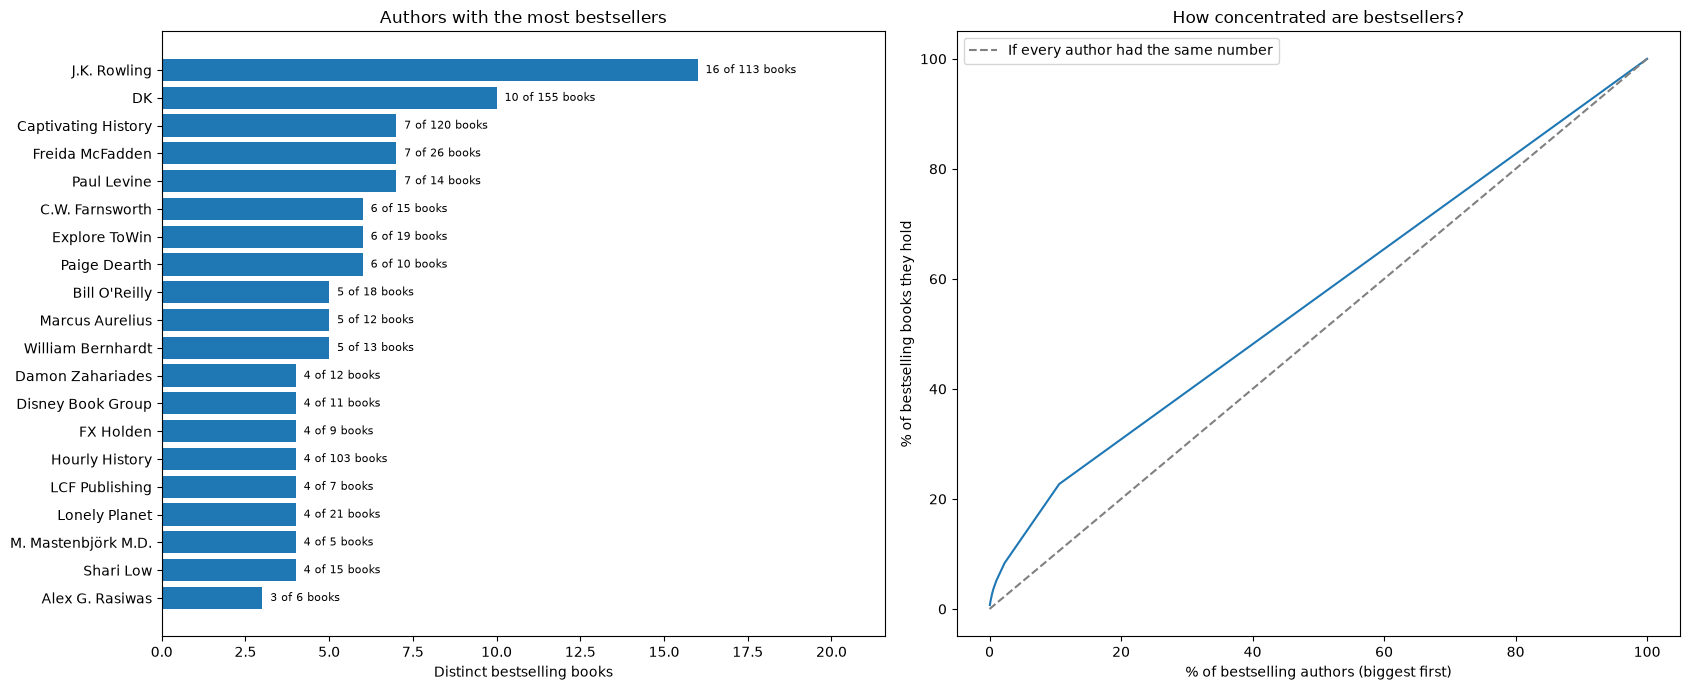

In [30]:
# How concentrated are bestsellers among authors? Does catalogue size matter?
eda["author_books"] = eda.groupby("author")["asin"].transform("nunique")   # distinct books by the same author (also used in 9a and 9b)

counts = auth["distinct_bestsellers"].sort_values(ascending=False)       # bestselling books per author, biggest first
cum_share = counts.cumsum() / counts.sum()                               # running share of all bestselling books
print("Authors with at least one bestseller:", len(counts))
print("Authors with exactly one:", (counts == 1).sum())
for share in [0.01, 0.05, 0.10]:
    k = max(1, int(len(counts) * share))                                 # how many authors make up the top x%
    print(f"Top {share:.0%} of these authors ({k}) hold {cum_share.iloc[k - 1]:.1%} of bestselling books")

size_band = pd.cut(eda["author_books"], [0, 1, 2, 5, 10, 25, 100, np.inf],
                   labels=["1", "2", "3-5", "6-10", "11-25", "26-100", "100+"])   # catalogue-size bands
print("\nBestseller rate by the author's number of books in the data:")
display(rate_table_ci(eda, size_band, sort_by_rate=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
plot = top_authors.iloc[::-1]                                            # biggest at the top of the chart
axes[0].barh(plot.index, plot["distinct_bestsellers"])
for i, (n_best, n_all) in enumerate(zip(plot["distinct_bestsellers"], plot["books_in_data"])):
    axes[0].text(n_best, i, f"  {n_best} of {n_all} books", va="center", fontsize=8)   # e.g. "12 of 15 books"
axes[0].set_xlim(0, plot["distinct_bestsellers"].max() * 1.35)          # room for the labels
axes[0].set_xlabel("Distinct bestselling books")
axes[0].set_title("Authors with the most bestsellers")

x = np.arange(1, len(counts) + 1) / len(counts) * 100                    # % of authors, biggest first
axes[1].plot(x, cum_share.to_numpy() * 100)
axes[1].plot([0, 100], [0, 100], ls="--", color="grey", label="If every author had the same number")
axes[1].set_xlabel("% of bestselling authors (biggest first)")
axes[1].set_ylabel("% of bestselling books they hold")
axes[1].set_title("How concentrated are bestsellers?")
axes[1].legend()
save(fig, "eda_06_authors")

##### EDA 7

,books,bestsellers,rate,vs_overall,ci_low,ci_high
age_months,,,,,,
Not yet out,6,0,0.0000,0.0000,0.0000,0.3903
0-3 m,6808,241,0.0354,2.1072,0.0313,0.0401
3-6 m,4415,96,0.0217,1.2944,0.0178,0.0265
6-12 m,6300,111,0.0176,1.0488,0.0147,0.0212
1-2 y,9731,197,0.0202,1.2051,0.0176,0.0232
2-5 y,20937,314,0.0150,0.8927,0.0134,0.0167
5-10 y,19464,263,0.0135,0.8043,0.0120,0.0152
10 y+,16425,175,0.0107,0.6342,0.0092,0.0123
No date,49016,839,0.0171,1.0189,0.0160,0.0183


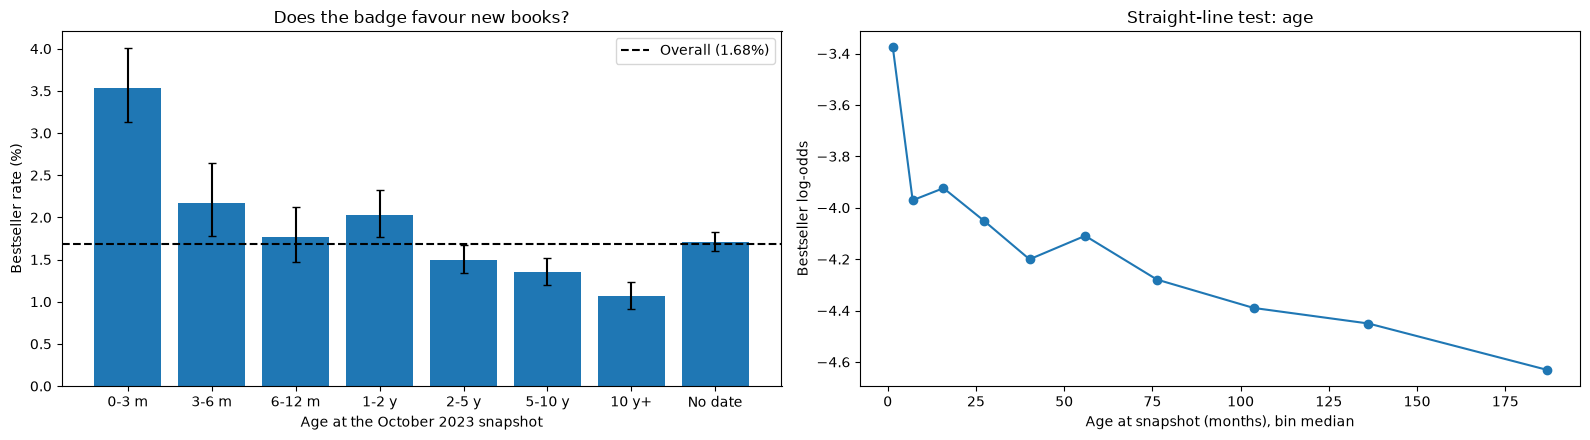

In [31]:
# Recency: does the bestseller badge favour new books? (answers the timing question raised in 1d)
age_band = pd.cut(eda["age_months"], [-np.inf, 0, 3, 6, 12, 24, 60, 120, np.inf], right=False,
                  labels=["Not yet out", "0-3 m", "3-6 m", "6-12 m", "1-2 y", "2-5 y", "5-10 y", "10 y+"])
age_band = age_band.cat.add_categories("No date").fillna("No date")      # keep undated books as their own group (1a)
age_tab = rate_table_ci(eda, age_band, sort_by_rate=False)               # keep the bands in age order
display(age_tab.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
rate_bars(axes[0], age_tab.drop(index="Not yet out"),                    # the 6 pre-orders (1d) are too few to plot
          "Does the badge favour new books?", horizontal=False)
axes[0].set_xlabel("Age at the October 2023 snapshot")

g = logodds_by_bin(eda, "age_months")                                    # the straight-line test on age
axes[1].plot(g["x"], g["log_odds"], marker="o")
axes[1].set_xlabel("Age at snapshot (months), bin median")
axes[1].set_ylabel("Bestseller log-odds")
axes[1].set_title("Straight-line test: age")
save(fig, "eda_07a_recency")

has_series    on 22.8% of books | rate with: 1.61% | without: 1.70%
has_colon     on 66.9% of books | rate with: 1.86% | without: 1.32%
has_a_novel   on  2.0% of books | rate with: 0.56% | without: 1.70%
has_brackets  on 37.3% of books | rate with: 1.76% | without: 1.63%


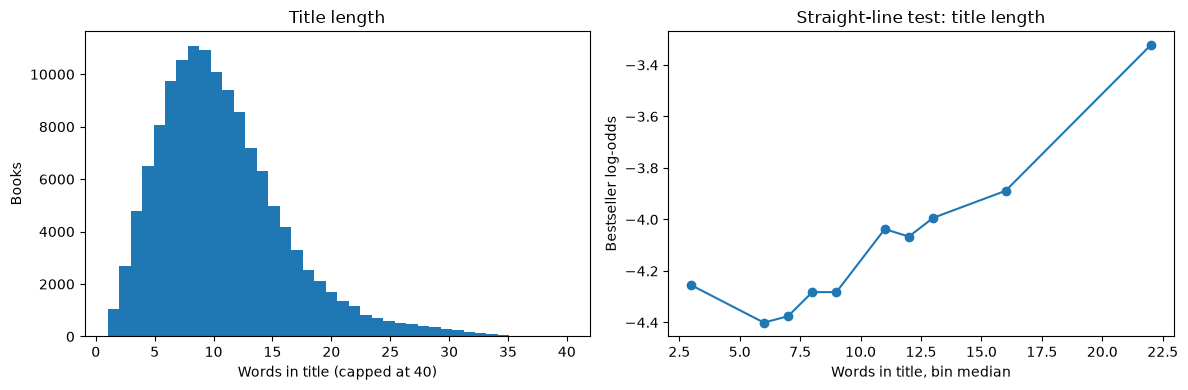

In [32]:
# Title clues: each flag's share of books and its bestseller rate with / without
title = eda["title"].str.lower()                                        # lower-case once, reuse below
eda["title_words"] = eda["title"].str.split().str.len()                 # number of words in the title
eda["has_series"] = title.str.contains(r"\bbook \d|\bseries\b|\bvol(?:ume)?\.? ?\d|#\s?\d", regex=True)   # "Book 2", "Series", "Vol 3", "#4"
eda["has_colon"] = title.str.contains(":", regex=False)                 # "Title: Subtitle", common in non-fiction
eda["has_a_novel"] = title.str.contains("a novel", regex=False)         # "...: A Novel", common in traditional fiction
eda["has_brackets"] = title.str.contains("(", regex=False)              # brackets often hold series information

for flag in ["has_series", "has_colon", "has_a_novel", "has_brackets"]:
    t = rate_table(eda, flag, sort_by_rate=False)                       # one row for False, one for True
    print(f"{flag:13s} on {eda[flag].mean():5.1%} of books | rate with: {t.loc[True, 'rate']:.2%} "
          f"| without: {t.loc[False, 'rate']:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(eda["title_words"].clip(upper=40), bins=40)                # titles longer than 40 words grouped at 40
axes[0].set_xlabel("Words in title (capped at 40)")
axes[0].set_ylabel("Books")
axes[0].set_title("Title length")

g = logodds_by_bin(eda, "title_words")                                   # the straight-line test on title length
axes[1].plot(g["x"], g["log_odds"], marker="o")
axes[1].set_xlabel("Words in title, bin median")
axes[1].set_ylabel("Bestseller log-odds")
axes[1].set_title("Straight-line test: title length")
save(fig, "eda_07b_titles")

,rate: not KU,rate: KU,KU share,books
title_words,,,,
1-5,0.0074,0.0417,0.1901,23098
6-8,0.0058,0.0290,0.2824,31363
9-11,0.0078,0.0340,0.2650,30392
12-15,0.0099,0.0379,0.2754,27019
16-20,0.0106,0.0540,0.2756,13842
21+,0.0070,0.0808,0.4407,7388


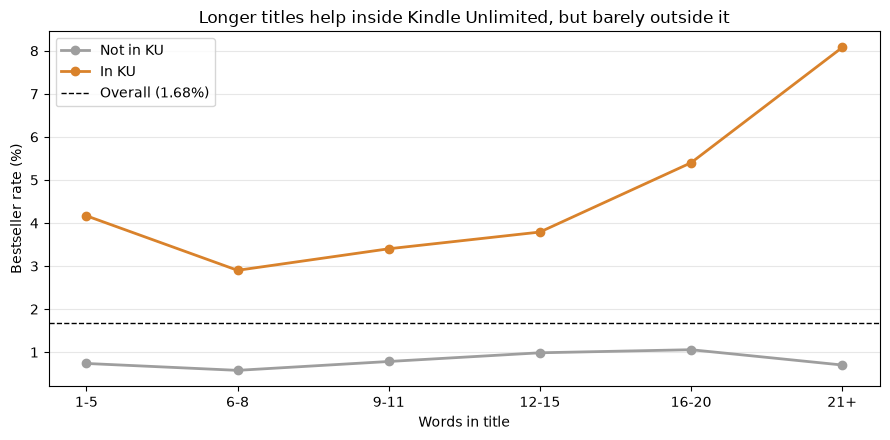

In [33]:
# Follow-up to second check in section: do long titles still help once Kindle Unlimited is taken into account?
words_band = pd.cut(eda["title_words"], [0, 5, 8, 11, 15, 20, np.inf],
                    labels=["1-5", "6-8", "9-11", "12-15", "16-20", "21+"])   # title-length bands

long_ku = pd.DataFrame({
    "rate: not KU": pd.crosstab(words_band, eda["isKindleUnlimited"],
                                values=eda["isBestSeller"], aggfunc="mean")[False],   # rate outside KU
    "rate: KU": pd.crosstab(words_band, eda["isKindleUnlimited"],
                            values=eda["isBestSeller"], aggfunc="mean")[True],        # rate inside KU
    "KU share": eda.groupby(words_band, observed=True)["isKindleUnlimited"].mean(),   # share of these titles in KU
    "books": words_band.value_counts().sort_index()})                                 # titles in each band
display(long_ku.round(4))

# Chart: one line outside KU, one inside KU
x = np.arange(len(long_ku))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x, long_ku["rate: not KU"] * 100, marker="o", lw=2, color="#9e9e9e", label="Not in KU")
ax.plot(x, long_ku["rate: KU"] * 100, marker="o", lw=2, color="#d9822b", label="In KU")
ax.axhline(BASE_RATE * 100, ls="--", color="black", lw=1, label=f"Overall ({BASE_RATE:.2%})")
ax.set_xticks(x, long_ku.index.astype(str))
ax.set_xlabel("Words in title")
ax.set_ylabel("Bestseller rate (%)")
ax.set_title("Longer titles help inside Kindle Unlimited, but barely outside it")
ax.grid(axis="y", alpha=0.3)
ax.legend()
save(fig, "eda_07c_titles_ku")

In [34]:
# Leakage check: do titles contain success words that are only added after a book sells well?
success_words = r"bestsell|best-sell|best sell|million cop|#1|award-winning|now a major"
marketing = eda["title"].str.contains(success_words, case=False, regex=True)   # True where a success phrase appears
print(f"Titles with success words: {marketing.sum():,} "
      f"| bestseller rate: {eda.loc[marketing, 'isBestSeller'].mean():.2%} "
      f"vs {eda.loc[~marketing, 'isBestSeller'].mean():.2%} without")
with pd.option_context("display.max_colwidth", 90):
    display(eda.loc[marketing & eda["isBestSeller"], ["title"]].head(10))    # bestselling titles that contain them

Titles with success words: 969 | bestseller rate: 1.96% vs 1.68% without


,title
88,The American Girl: The Number One bestselling Irish historical fiction novel of heartb...
135,What If?: The perfect laugh-out-loud romantic comedy from #1 bestseller Shari Low
238,What Next?: The BRAND NEW laugh-out-loud novel from #1 bestseller Shari Low
11355,Thinking in Systems: International Bestseller
23585,100 Clásicos de la Literatura Universal: Vol.1 (Best Sellers en español) (Spanish Edit...
28958,One Moment in Time: THE NUMBER ONE BESTSELLER
29832,The Silver Ladies Do Lunch: THE TOP 10 BESTSELLER
30857,"Always On My Mind: The uplifting, heartwarming novel from NUMBER ONE BESTSELLER Beth M..."
38295,Python Programming and SQL: 5 books in 1 - The #1 Coding Course from Beginner to Advan...
48314,Rule #1: You Can't Date the Coach's Daughter: A Standalone Sweet High School Romance (...


##### EDA 8

,books,bestsellers,rate,vs_overall,ci_low,ci_high
Editors' Pick only,5621,0,0.0000,0.0000,0.000,0.0007
Goodreads Choice only,1402,0,0.0000,0.0000,0.000,0.0027
Neither badge,126079,2236,0.0177,1.0557,0.017,0.0185


Books with Editors' Pick or Goodreads Choice: 7,023
Bestsellers among them: 0 | expected if the badges were unrelated: about 118


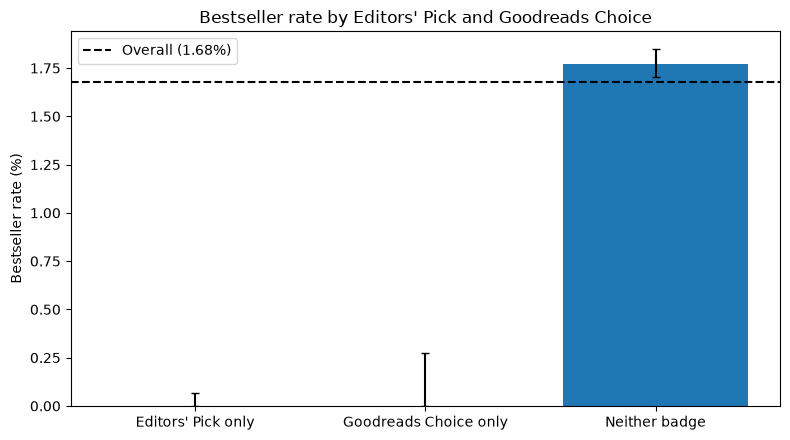

In [35]:
# Editors' Pick and Goodreads Choice: do they ever appear together with the bestseller badge?
badge_grp = np.select([eda["isEditorsPick"] & eda["isGoodReadsChoice"], eda["isEditorsPick"], eda["isGoodReadsChoice"]],
                      ["Both badges", "Editors' Pick only", "Goodreads Choice only"], default="Neither badge")   # first match wins
badge_tab = rate_table_ci(eda, badge_grp, sort_by_rate=False)            # one row per badge combination
display(badge_tab.round(4))

any_badge = eda["isEditorsPick"] | eda["isGoodReadsChoice"]              # True if the book has either badge
print(f"Books with Editors' Pick or Goodreads Choice: {any_badge.sum():,}")
print(f"Bestsellers among them: {int((any_badge & eda['isBestSeller']).sum())} "
      f"| expected if the badges were unrelated: about {any_badge.sum() * BASE_RATE:.0f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
rate_bars(ax, badge_tab, "Bestseller rate by Editors' Pick and Goodreads Choice", horizontal=False)
save(fig, "eda_08a_badges")

<img src="../reports/figures/ScreenshotPART2.png" width="200">

In [36]:
# Follow-up to first check in section: do Editors' Pick and Goodreads Choice books look like bestsellers? (hidden-badge check)
BIG_FIVE = ["Penguin Random House", "HarperCollins", "Simon & Schuster", "Hachette", "Macmillan"]   # from 5b's groups
group = np.select([eda["isBestSeller"], eda["isEditorsPick"], eda["isGoodReadsChoice"]],
                  ["Bestseller", "Editors' Pick", "Goodreads Choice"], default="No badge")   # first true condition wins
badge_profile = eda.assign(group=group).groupby("group").agg(
    books=("asin", "size"),
    ku_share=("isKindleUnlimited", "mean"),                             # share in Kindle Unlimited
    median_price=("price", "median"),
    median_stars=("stars", "median"),
    share_2023=("pub_year", lambda s: s.dropna().eq(2023).mean()),      # share of dated books published in 2023
    big_five_share=("publisher_grp", lambda s: s.isin(BIG_FIVE).mean()))   # share sold by a Big Five publisher
display(badge_profile.round(3))

,books,ku_share,median_price,median_stars,share_2023,big_five_share
group,,,,,,
Bestseller,2236,0.655,5.99,4.5,0.276,0.182
Editors' Pick,5621,0.072,11.99,4.5,0.167,0.758
Goodreads Choice,1402,0.128,9.99,4.5,0.008,0.690
No badge,123843,0.273,9.99,4.5,0.173,0.207


##### EDA 9

,set,groups,cramers_v,p_value
feature,,,,
is_ku,Set A,2,0.1138,0.0
price_band,Set A,7,0.0881,0.0
category_name,Set A,31,0.0794,0.0
publisher_grp,Set A,12,0.0563,0.0
reviews (usable counts),Set B only,7,0.0518,0.0
age (bands),Set B only,7,0.0503,0.0
title_words (bands),Set A,6,0.0488,0.0
single_book_author,Set A,2,0.0282,0.0
stars (bands),Set B only,7,0.0203,0.0


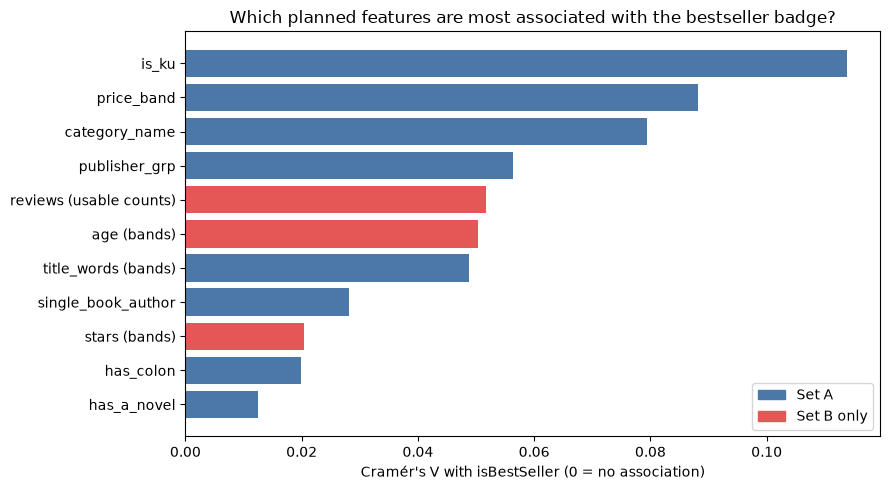

In [37]:
# Which planned features matter most? One ranking on one scale (Cramér's V with isBestSeller)

rated = eda["stars"] > 0                                                 # books with a star rating
captured = ~((eda["reviews"] == 0) & rated)                              # leaves out the lost review counts (1e)
candidates = [                                                           # (name, values, which set)
    ("is_ku",                   eda["isKindleUnlimited"],                                   "Set A"),
    ("price_band",              eda["price_band"],                                          "Set A"),
    ("category_name",           eda["category_name"],                                       "Set A"),
    ("publisher_grp",           eda["publisher_grp"],                                       "Set A"),
    ("title_words (bands)",     pd.cut(eda["title_words"], [0, 5, 8, 11, 15, 20, np.inf]),  "Set A"),
    ("has_colon",               eda["has_colon"],                                           "Set A"),
    ("has_a_novel",             eda["has_a_novel"],                                         "Set A"),
    ("single_book_author",      eda["author_books"] == 1,                                   "Set A"),
    ("stars (bands)",           eda["stars_band"],                                          "Set B only"),
    ("reviews (usable counts)", eda["reviews_band"].where(captured),                        "Set B only"),   # lost counts left out
    ("age (bands)",             pd.cut(eda["age_months"].clip(lower=0),
                                       [-1, 3, 6, 12, 24, 60, 120, np.inf]),                "Set B only"),   # undated books left out
]
rows = []
for name, x, kind in candidates:
    v, p = cramers_v(x, eda["isBestSeller"])                             # same measure for every feature
    rows.append({"feature": name, "set": kind, "groups": x.nunique(), "cramers_v": v, "p_value": p})
ranking = pd.DataFrame(rows).set_index("feature").sort_values("cramers_v", ascending=False)
display(ranking.round(4))

colors = {"Set A": "#4c78a8", "Set B only": "#e45756"}
plot = ranking.iloc[::-1]                                                # strongest at the top
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot.index, plot["cramers_v"], color=[colors[k] for k in plot["set"]])
ax.legend(handles=[Patch(color=c, label=k) for k, c in colors.items()])   # one coloured key per set
ax.set_xlabel("Cramér's V with isBestSeller (0 = no association)")
ax.set_title("Which planned features are most associated with the bestseller badge?")
save(fig, "eda_09a_feature_ranking")

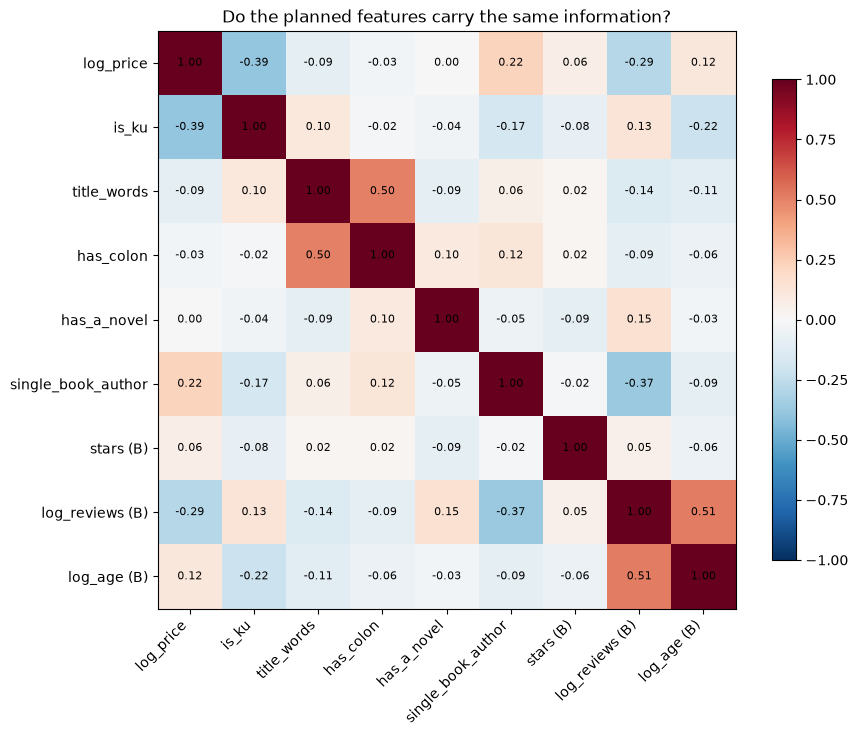

Strongest pairs:


abs corr
log_reviews (B)    log_age (B)             0.51
title_words        has_colon               0.50
log_price          is_ku                   0.39
single_book_author log_reviews (B)         0.37
log_price          log_reviews (B)         0.29
                   single_book_author      0.22
is_ku              log_age (B)             0.22
                   single_book_author      0.17

In [38]:
# Which planned features carry the same information? (correlation check before modelling)
eda["log_reviews"] = np.log1p(eda["reviews"])                            # log(1 + reviews): tames the huge counts (1c)

rated = eda["stars"] > 0                                                 # books with a star rating
captured = ~((eda["reviews"] == 0) & rated)                              # leaves out the lost review counts (1e)
feats = pd.DataFrame({
    "log_price": eda["log_price"],                                       # Set A
    "is_ku": eda["isKindleUnlimited"],
    "title_words": eda["title_words"].clip(upper=30),
    "has_colon": eda["has_colon"],
    "has_a_novel": eda["has_a_novel"],
    "single_book_author": eda["author_books"] == 1,
    "stars (B)": eda["stars"].where(rated),                              # Set B: rated books only
    "log_reviews (B)": eda["log_reviews"].where(captured),               # Set B: usable counts only
    "log_age (B)": np.log1p(eda["age_months"].clip(lower=0)),            # Set B: pre-orders set to age 0
}).astype(float)                                                         # True/False become 1/0
corr = feats.corr()                                                      # pairwise correlation, ignoring NaN

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)                    # red = move together, blue = opposite
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)   # value in each square
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Do the planned features carry the same information?")
save(fig, "eda_09b_correlation")

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))        # each pair once (upper triangle only)
print("Strongest pairs:")
display(upper.stack().dropna().abs().sort_values(ascending=False).head(8).round(2).to_frame("abs corr"))

##### Final feature plan
###### **Set A (known before launch):** `is_ku`; `log_price`, `is_under_2_99` (`is_free` to test); one-hot `category_name`; one-hot `publisher_grp`; `single_book_author`; `title_words` (capped at 30), `has_colon`, `has_a_novel`.
###### **Set B (Set A + after launch):** `stars` + `no_ratings`; `log_reviews` + `reviews_missing`; `log(1 + age_months)` + `age_missing`. To test: reviews per month.
###### **Cleaning:** remove the 7,023 badge books and physical products; drop `asin`, `imgUrl`, `productURL`, `category_id`, `isEditorsPick`, `isGoodReadsChoice`; fill missing sellers with "Unknown"; set hidden authors and lost review counts to missing; clip age at 0.
###### **Splitting:** shuffled, stratified group split by title + author (70/15/15); every count, scale and fill is calculated from the training split only.

### Data Preporation based on EDA evidance 

###### Start a fresh copy for modelling, and remove the books whose label can't be trusted (8a)

In [39]:
df = df_raw.copy()                                                      # eda keeps its exploration columns; df is for the model
print(f"Start: {len(df):,} books, {int(df['isBestSeller'].sum()):,} bestsellers ({df['isBestSeller'].mean():.2%})")

badge = df["isEditorsPick"] | df["isGoodReadsChoice"]                   # Editors' Pick or Goodreads Choice
df = df[~badge].copy()                                                  # keep only books without those badges
print(f"Removed {badge.sum():,} badge books -> {len(df):,} books left")

Start: 133,102 books, 2,236 bestsellers (1.68%)
Removed 7,023 badge books -> 126,079 books left


###### Physical products? (4d, 2b) Check only: every row is a Kindle listing, so print words in a title are not proof

In [40]:
physical = df["title"].str.contains(r"hardcover|paperback|slipcase|^rare\b", case=False, regex=True)
print(f"Titles mentioning a print format: {physical.sum()} | bestsellers among them: {int((physical & df['isBestSeller']).sum())}")
with pd.option_context("display.max_colwidth", 80, "display.max_rows", 20):
    display(df.loc[physical, ["title", "price", "category_name", "isBestSeller"]].head(15))   # mostly ebooks that mention an edition
print("Decision: keep them. Removing would drop real Kindle listings, including real bestsellers.")

Titles mentioning a print format: 92 | bestsellers among them: 3


,title,price,category_name,isBestSeller
776,Rich Kid Smart Kid: Giving Your Child a Financial Head Start (Rich Dad's (Pa...,11.99,Parenting & Relationships,False
1268,"How To Self-Publish A Children's Book: Everything You Need To Know to Write,...",2.99,Parenting & Relationships,False
2764,The Transgender Child: A Handbook for Families and Professionals (A Handbook...,12.99,Parenting & Relationships,False
5137,Attachment-Focused Parenting: Effective Strategies to Care for Children (Nor...,18.70,Parenting & Relationships,False
5531,Exploring the Urban Community: A GIS Approach (Pearson Prentice Hall Series ...,74.99,Engineering & Transportation,False
8095,Rare: The High-Stakes Race to Satisfy Our Need for the Scarcest Metals on Earth,17.99,Engineering & Transportation,False
10496,Fundamentals of Electronic Warfare (Artech House Radar Library) (Artech Hous...,174.80,Engineering & Transportation,False
14441,The Scientist as Rebel (New York Review Books (Paperback)),13.99,Science & Math,False
14780,Moon Lander: How We Developed the Apollo Lunar Module (Smithsonian History o...,15.99,Science & Math,False
14912,The Body Remembers Continuing Education Test: The Psychophysiology of Trauma...,26.99,Science & Math,False


Decision: keep them. Removing would drop real Kindle listings, including real bestsellers.


###### Authors and sellers: fix hidden blanks (2b) and group the sellers (5b)

In [41]:
placeholders = {"", "unknown", "n/a", "na", "none", "null", "-"}
hidden = df["author"].str.strip().str.lower().isin(placeholders)         # "none", "unknown"
df.loc[hidden, "author"] = np.nan                                        # treat them like the real blanks
print(f"Hidden blank authors set to missing: {hidden.sum()} | total missing authors: {df['author'].isna().sum():,}")

df["publisher_grp"] = df["soldBy"].map(publisher_group)                  # same rule as 5b; a missing seller becomes "Unknown"
print("Publisher groups:", df["publisher_grp"].nunique())
display(df["publisher_grp"].value_counts().to_frame("books"))

Hidden blank authors set to missing: 2 | total missing authors: 415
Publisher groups: 12


,books
publisher_grp,
Amazon,83813
Penguin Random House,10821
Unknown,8507
Academic publishers,4658
HarperCollins,4574
Simon & Schuster,4153
Hachette,4089
Macmillan,2358
Spanish-language publishers,1547


###### Stars and reviews (Set B only): lost counts become missing, truly unrated books get a flag (1e)

In [42]:
lost = (df["stars"] > 0) & (df["reviews"] == 0)                          # has a rating but shows 0 reviews: count lost
unrated = (df["stars"] == 0) & (df["reviews"] == 0)                      # nobody has rated it yet

df["reviews_missing"] = lost.astype(int)                                 # 1 = review count unknown
df.loc[lost, "reviews"] = np.nan                                         # "unknown", not 0 (filled from training data in Step 3)
df["no_ratings"] = unrated.astype(int)                                   # 1 = no ratings at all
df.loc[unrated, "stars"] = np.nan                                        # 0 stars means "no rating", not "rated 0"

print(f"Lost review counts set to missing: {lost.sum():,} | truly unrated books flagged: {unrated.sum():,}")

Lost review counts set to missing: 58,341 | truly unrated books flagged: 3,180


###### Dates (Set B only): age at the snapshot, clipped at 0, with a flag for missing dates (1d, 7a)

In [43]:
pub_date = pd.to_datetime(df["publishedDate"], errors="coerce", format="mixed")
df["age_months"] = ((SNAPSHOT - pub_date).dt.days / 30.44).clip(lower=0)   # pre-orders get 0, not a negative age
df["age_missing"] = df["age_months"].isna().astype(int)                     # 1 = no publication date
print(f"Books without a date: {df['age_missing'].sum():,} | pre-orders set to age 0: {(pub_date > SNAPSHOT).sum()}")

Books without a date: 47,085 | pre-orders set to age 0: 5


###### Drop the columns the model will never use, then check the result

In [44]:
drop_cols = ["imgUrl", "productURL", "category_id", "isEditorsPick", "isGoodReadsChoice", "publishedDate"]
df = df.drop(columns=drop_cols)                                         # links, a duplicate of category, badges, raw dates
df = df.reset_index(drop=True)                                          # clean row numbers 0..n-1

n_pos = int(df["isBestSeller"].sum())
print(f"Clean data: {len(df):,} books x {df.shape[1]} columns | bestsellers: {n_pos:,} ({df['isBestSeller'].mean():.2%})")
print("Columns:", list(df.columns))
display(df.isna().sum()[lambda s: s > 0].to_frame("missing"))           # only the gaps we chose to keep

Clean data: 126,079 books x 15 columns | bestsellers: 2,236 (1.77%)
Columns: ['asin', 'title', 'author', 'soldBy', 'stars', 'reviews', 'price', 'isKindleUnlimited', 'isBestSeller', 'category_name', 'publisher_grp', 'reviews_missing', 'no_ratings', 'age_months', 'age_missing']


,missing
author,415
soldBy,8507
stars,3180
reviews,58341
age_months,47085


###### Group split: 70% train, 15% validation, 15% test, every edition of a book in the same split (1i)

In [45]:
df["book_key"] = (df["title"].str.strip().str.lower() + " | "
                  + df["author"].fillna("").str.strip().str.lower())    # same "same book" key as in 1h
keys = df.groupby("book_key")["isBestSeller"].max()                     # one row per book; True if any copy is a bestseller
key_ids = keys.index.to_numpy(dtype=object)                             # plain array of keys (sklearn can't index pandas 3 text)
key_labels = keys.to_numpy(dtype=int)                                   # 1 = bestseller book, 0 = not

train_keys, rest_keys = train_test_split(key_ids, test_size=0.30, stratify=key_labels,
                                         shuffle=True, random_state=SEED)                 # 70% vs 30%
val_keys, test_keys = train_test_split(rest_keys, test_size=0.50,
                                       stratify=keys.loc[rest_keys].to_numpy(dtype=int),
                                       shuffle=True, random_state=SEED)                   # 30% -> 15% + 15%

train = df[df["book_key"].isin(train_keys)].copy()                      # every row follows its book key
val = df[df["book_key"].isin(val_keys)].copy()
test = df[df["book_key"].isin(test_keys)].copy()

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:11s} {len(part):7,} books ({len(part) / len(df):.1%}) | "
          f"bestsellers {int(part['isBestSeller'].sum()):5,} ({part['isBestSeller'].mean():.2%})")

overlap = (set(train["book_key"]) & set(val["book_key"])) | (set(train["book_key"]) & set(test["book_key"])) \
          | (set(val["book_key"]) & set(test["book_key"]))
print(f"Book keys in more than one split: {len(overlap)}  (must be 0)")
print(f"All rows used exactly once: {len(train) + len(val) + len(test) == len(df)}")

Train        88,254 books (70.0%) | bestsellers 1,567 (1.78%)
Validation   18,914 books (15.0%) | bestsellers   335 (1.77%)
Test         18,911 books (15.0%) | bestsellers   334 (1.77%)
Book keys in more than one split: 0  (must be 0)
All rows used exactly once: True


### Feature engineering (build the features into SET A & SET B)

###### learn every fill value, author count and category list from the TRAINING split only

In [46]:
REF_CATEGORY = "Mystery, Thriller & Suspense"                            # left out of the one-hot columns (comparison group, 4d)
REF_PUBLISHER = "Amazon"                                                # biggest group (P3), also left out

fit = {
    "author_books": train.groupby("author")["asin"].nunique(),           # books each author has in train (6b)
    "categories": sorted(c for c in train["category_name"].unique() if c != REF_CATEGORY),
    "publishers": sorted(p for p in train["publisher_grp"].unique() if p != REF_PUBLISHER),
    "stars_fill": train["stars"].median(),                              # middle star rating of rated train books
    "log_reviews_fill": np.log1p(train["reviews"]).median(),             # middle review count of train books whose count is known
    "log_age_fill": np.log1p(train["age_months"]).median(),              # middle age of train books with a date
}
print(f"Categories kept as columns: {len(fit['categories'])} (+ {REF_CATEGORY} as the reference)")
print(f"Publisher groups kept as columns: {len(fit['publishers'])} (+ {REF_PUBLISHER} as the reference)")
print(f"Authors seen in train: {len(fit['author_books']):,}")
print(f"Fill values from train: stars {fit['stars_fill']:.2f} | log reviews {fit['log_reviews_fill']:.2f} "
      f"(~{np.expm1(fit['log_reviews_fill']):.0f} reviews) | log age {fit['log_age_fill']:.2f} "
      f"(~{np.expm1(fit['log_age_fill']):.0f} months)")

Categories kept as columns: 30 (+ Mystery, Thriller & Suspense as the reference)
Publisher groups kept as columns: 11 (+ Amazon as the reference)
Authors seen in train: 53,759
Fill values from train: stars 4.50 | log reviews 5.61 (~271 reviews) | log age 3.89 (~48 months)


###### one function turns any split into Set A or Set B features, using only the train values in fit

In [47]:
def build_features(part, fit, feature_set, is_train):
    X = pd.DataFrame(index=part.index)
    title = part["title"].str.lower()

    # ---- Set A: known before launch ----
    X["is_ku"] = part["isKindleUnlimited"].astype(int)                   # 5d
    X["log_price"] = np.log1p(part["price"])                             # 4a
    X["is_under_2_99"] = (part["price"] < 2.99).astype(int)              # 4b: the cheapest bands behave differently
    for cat in fit["categories"]:                                        # 3a/3b: one column per category
        X[f"cat_{cat}"] = (part["category_name"] == cat).astype(int)     # a category train never saw gets all zeros
    for pub in fit["publishers"]:                                        # 5b: one column per publisher group
        X[f"pub_{pub}"] = (part["publisher_grp"] == pub).astype(int)
    seen = part["author"].map(fit["author_books"]).fillna(0)             # this author's books in train
    n_books = seen if is_train else seen + 1                             # val/test: add the book itself
    X["single_book_author"] = ((n_books == 1) & part["author"].notna()).astype(int)   # 6b; unknown author -> 0
    X["title_words"] = part["title"].str.split().str.len().clip(upper=30)   # 7b, capped at 30
    X["has_colon"] = title.str.contains(":", regex=False).astype(int)     # 7b
    X["has_a_novel"] = title.str.contains("a novel", regex=False).astype(int)   # 7b

    # ---- Set B adds: only known after launch ----
    if feature_set == "B":
        X["stars"] = part["stars"].fillna(fit["stars_fill"])             # 1g; unrated books get the train middle value
        X["no_ratings"] = part["no_ratings"]                             # ...and this flag says so
        X["log_reviews"] = np.log1p(part["reviews"]).fillna(fit["log_reviews_fill"])   # 1e/9b; lost counts filled
        X["reviews_missing"] = part["reviews_missing"]
        X["log_age"] = np.log1p(part["age_months"]).fillna(fit["log_age_fill"])        # 1d/7a; no date filled
        X["age_missing"] = part["age_missing"]
    return X.astype(float)


raw = {}
for fs in ["A", "B"]:
    for name, part in [("train", train), ("val", val), ("test", test)]:
        raw[(fs, name)] = build_features(part, fit, fs, is_train=(name == "train"))

for fs in ["A", "B"]:
    print(f"Set {fs}: {raw[(fs, 'train')].shape[1]} columns | "
          f"train {len(raw[(fs, 'train')]):,} | val {len(raw[(fs, 'val')]):,} | test {len(raw[(fs, 'test')]):,}")
display(raw[("B", "train")].head())

Set A: 48 columns | train 88,254 | val 18,914 | test 18,911
Set B: 54 columns | train 88,254 | val 18,914 | test 18,911


,is_ku,log_price,is_under_2_99,cat_Arts & Photo graphy,cat_Biographies & Memoirs,cat_Business & Money,cat_Children's eBooks,cat_Comics,cat_Computers & Technology,"cat_Cookbooks, Food & Wine","cat_Crafts, Hobbies & Home",cat_Education & Teaching,cat_Engineering & Transportation,cat_Foreign Language,"cat_Health, Fitness & Dieting",cat_History,cat_Humor & Entertainment,cat_LGBTQ+ eBooks,cat_Law,cat_Literature & Fiction,cat_Medical,cat_Nonfiction,cat_Parenting & Relationships,cat_Politics & Social Sciences,cat_Reference,...,cat_Self-Help,cat_Sports & Outdoors,cat_Teen & Young Adult,cat_Travel,pub_Academic publishers,pub_De Marque,pub_Hachette,pub_Harlequin,pub_HarperCollins,pub_Macmillan,pub_Other sellers,pub_Penguin Random House,pub_Simon & Schuster,pub_Spanish-language publishers,pub_Unknown,single_book_author,title_words,has_colon,has_a_novel,stars,no_ratings,log_reviews,reviews_missing,log_age,age_missing
0,0.0,2.396986,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,1.0,0.0,4.8,0.0,5.605802,1.0,4.615121,0.0
1,0.0,2.889816,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,16.0,1.0,0.0,4.4,0.0,5.605802,1.0,3.019495,0.0
3,0.0,2.707383,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,5.0,1.0,0.0,4.6,0.0,5.605802,1.0,5.411628,0.0
4,0.0,2.771964,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,20.0,1.0,0.0,4.6,0.0,5.605802,1.0,3.887709,1.0
5,0.0,2.638343,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,8.0,1.0,0.0,4.7,0.0,5.605802,1.0,2.937638,0.0


###### scale the number columns with the train mean and spread, then make NumPy arrays for the model

In [48]:
SCALE_COLS = ["log_price", "title_words", "stars", "log_reviews", "log_age"]   # 0/1 columns stay as they are

data = {}
for fs in ["A", "B"]:
    cols = [c for c in SCALE_COLS if c in raw[(fs, "train")].columns]
    mean = raw[(fs, "train")][cols].mean()                              # learned from train only
    std = raw[(fs, "train")][cols].std()
    for name in ["train", "val", "test"]:
        X = raw[(fs, name)].copy()
        X[cols] = (X[cols] - mean) / std                                 # same train numbers for every split
        data[(fs, name)] = X

feature_names = {fs: list(data[(fs, "train")].columns) for fs in ["A", "B"]}
Xa_train, Xa_val, Xa_test = (data[("A", n)].to_numpy() for n in ["train", "val", "test"])
Xb_train, Xb_val, Xb_test = (data[("B", n)].to_numpy() for n in ["train", "val", "test"])
y_train, y_val, y_test = (p["isBestSeller"].to_numpy(dtype=float) for p in [train, val, test])

print("Set A:", Xa_train.shape, Xa_val.shape, Xa_test.shape)
print("Set B:", Xb_train.shape, Xb_val.shape, Xb_test.shape)
print("y:", y_train.shape, y_val.shape, y_test.shape, f"| train bestseller rate {y_train.mean():.2%}")

Set A: (88254, 48) (18914, 48) (18911, 48)
Set B: (88254, 54) (18914, 54) (18911, 54)
y: (88254,) (18914,) (18911,) | train bestseller rate 1.78%


###### checks before any model sees the data

In [49]:
checks = {
    "No missing values anywhere": all(not np.isnan(a).any() for a in [Xa_train, Xa_val, Xa_test, Xb_train, Xb_val, Xb_test]),
    "Same columns in every split": all(list(data[(fs, n)].columns) == feature_names[fs]
                                       for fs in ["A", "B"] for n in ["val", "test"]),
    "Set B = Set A + 6 after-launch columns": feature_names["B"][:len(feature_names["A"])] == feature_names["A"]
                                              and len(feature_names["B"]) == len(feature_names["A"]) + 6,
    "No label or author-rate column used": not any(k in c for c in feature_names["B"]
                                                  for k in ["isBestSeller", "rate", "book_key", "author_"]),
    "Rows line up with y": len(Xa_train) == len(y_train) and len(Xb_val) == len(y_val) and len(Xb_test) == len(y_test),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

cols = [c for c in SCALE_COLS if c in feature_names["B"]]
display(pd.DataFrame({"train mean": data[("B", "train")][cols].mean(), "train std": data[("B", "train")][cols].std(),
                      "val mean": data[("B", "val")][cols].mean(), "test mean": data[("B", "test")][cols].mean()}).round(3))

PASS  No missing values anywhere
PASS  Same columns in every split
PASS  Set B = Set A + 6 after-launch columns
PASS  No label or author-rate column used
PASS  Rows line up with y


,train mean,train std,val mean,test mean
log_price,0.0,1.0,-0.008,0.004
title_words,-0.0,1.0,-0.004,0.013
stars,0.0,1.0,0.000,-0.007
log_reviews,-0.0,1.0,0.008,-0.009
log_age,0.0,1.0,-0.005,-0.002


### Model: logistic regression from scratch

###### the building blocks of logistic regression, written in NumPy

In [50]:
def sigmoid(z):
    """Turns any number into a probability between 0 and 1."""
    z = np.clip(z, -30, 30)                                              # stops overflow for very large |z|
    return 1.0 / (1.0 + np.exp(-z))


def class_weights(y):
    """Balanced weights: the rare bestsellers count as much in total as all the other books."""
    n, n_pos = len(y), y.sum()
    w_pos, w_neg = n / (2 * n_pos), n / (2 * (n - n_pos))
    return np.where(y == 1, w_pos, w_neg), w_pos / w_neg


def loss_and_grad(w, b, X, y, sw, lam):
    """Weighted log loss + L2 penalty, and its gradient (the direction that increases the loss fastest)."""
    p = sigmoid(X @ w + b)                                               # predicted probability for every book
    eps = 1e-12                                                          # keeps log() away from log(0)
    log_loss = -np.mean(sw * (y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
    loss = log_loss + 0.5 * lam * np.sum(w ** 2)                         # L2 shrinks big weights; bias is not penalised
    err = sw * (p - y)                                                   # weighted error per book
    grad_w = X.T @ err / len(y) + lam * w
    grad_b = np.mean(err)
    return loss, grad_w, grad_b


sw_a, ratio = class_weights(y_train)
print(f"Weight of a bestseller vs a non-bestseller: {ratio:.1f} to 1")
print(f"Train has {int(y_train.sum()):,} bestsellers and {int(len(y_train) - y_train.sum()):,} others")

Weight of a bestseller vs a non-bestseller: 55.3 to 1
Train has 1,567 bestsellers and 86,687 others


###### gradient check: compare the formula's gradient with a slow "nudge each weight" estimate

In [51]:
rng = np.random.default_rng(SEED)
idx = rng.choice(len(y_train), size=2000, replace=False)                 # small sample keeps this fast
Xs, ys = Xb_train[idx], y_train[idx]
sws = class_weights(ys)[0] if ys.sum() > 0 else np.ones_like(ys)
w0 = rng.normal(0, 0.1, Xs.shape[1]); b0 = 0.1; lam0 = 0.01

_, gw, gb = loss_and_grad(w0, b0, Xs, ys, sws, lam0)
h = 1e-5
num_gw = np.zeros_like(w0)
for j in range(len(w0)):                                                 # nudge one weight up and down
    wp, wm = w0.copy(), w0.copy(); wp[j] += h; wm[j] -= h
    num_gw[j] = (loss_and_grad(wp, b0, Xs, ys, sws, lam0)[0] - loss_and_grad(wm, b0, Xs, ys, sws, lam0)[0]) / (2 * h)
num_gb = (loss_and_grad(w0, b0 + h, Xs, ys, sws, lam0)[0] - loss_and_grad(w0, b0 - h, Xs, ys, sws, lam0)[0]) / (2 * h)

rel_err = np.linalg.norm(gw - num_gw) / (np.linalg.norm(gw) + np.linalg.norm(num_gw))
print(f"Weights: relative difference {rel_err:.2e}  (below 1e-6 = formula is right)")
print(f"Bias:    formula {gb:.6f} vs estimate {num_gb:.6f}")

Weights: relative difference 7.26e-11  (below 1e-6 = formula is right)
Bias:    formula -0.003936 vs estimate -0.003936


###### train with gradient descent and watch the loss fall

Stopped after 6452 steps | final loss 0.5340
Stopped after 8040 steps | final loss 0.5208


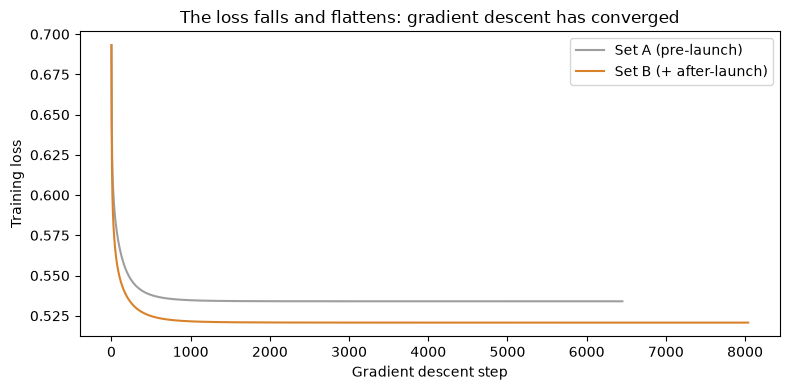

In [52]:
def train_logreg(X, y, lam=1e-3, lr=0.5, n_iter=20000, tol=1e-10, verbose=True):
    sw, _ = class_weights(y)
    w, b = np.zeros(X.shape[1]), 0.0                                     # start with every weight at 0
    history = []
    for it in range(n_iter):
        loss, gw, gb = loss_and_grad(w, b, X, y, sw, lam)
        w -= lr * gw                                                     # step downhill
        b -= lr * gb
        history.append(loss)
        if it > 0 and abs(history[-2] - history[-1]) < tol:              # stop once the loss stops improving
            break
    if verbose:
        print(f"Stopped after {it + 1} steps | final loss {history[-1]:.4f}")
    return w, b, history


def predict_proba(X, w, b):
    return sigmoid(X @ w + b)


w_a, b_a, hist_a = train_logreg(Xa_train, y_train)
w_b, b_b, hist_b = train_logreg(Xb_train, y_train)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist_a, label="Set A (pre-launch)", color="#9e9e9e")
ax.plot(hist_b, label="Set B (+ after-launch)", color="#d9822b")
ax.set_xlabel("Gradient descent step"); ax.set_ylabel("Training loss")
ax.set_title("The loss falls and flattens: gradient descent has converged")
ax.legend(); plt.tight_layout(); plt.show()

###### sanity checks: does our NumPy model match scikit-learn, and does it beat guessing?

In [53]:
lam = 1e-3
sk = LogisticRegression(C=1 / (len(y_train) * lam), max_iter=5000, tol=1e-10)    # same loss as ours
sk.fit(Xa_train, y_train, sample_weight=class_weights(y_train)[0])
gap = np.max(np.abs(sk.coef_[0] - w_a))
print(f"Set A: biggest weight difference, ours vs scikit-learn: {gap:.4f}  (close to 0 = our code is right)")

rows = []
for name, X_val, w, b in [("Set A", Xa_val, w_a, b_a), ("Set B", Xb_val, w_b, b_b)]:
    p = predict_proba(X_val, w, b)
    rows.append({"features": name, "val PR-AUC": average_precision_score(y_val, p),
                 "val ROC-AUC": roc_auc_score(y_val, p)})
rows.append({"features": "Guessing (floor)", "val PR-AUC": y_val.mean(), "val ROC-AUC": 0.5})
display(pd.DataFrame(rows).set_index("features").round(4))

Set A: biggest weight difference, ours vs scikit-learn: 0.0052  (close to 0 = our code is right)


,val PR-AUC,val ROC-AUC
features,,
Set A,0.0707,0.8228
Set B,0.0753,0.8279
Guessing (floor),0.0177,0.5000


### Tuning and baselines (validation only)

###### tune the L2 strength on validation (train on train, score on val, never touch test)

,set,lambda,val PR-AUC,val ROC-AUC,largest |weight|
0,A,1e-06,0.0815,0.8283,2.7516
1,A,1e-05,0.0814,0.8282,2.7007
2,A,1e-04,0.0804,0.8276,2.3147
3,A,1e-03,0.0707,0.8228,1.7879
4,A,1e-02,0.0579,0.7941,1.2253
5,A,1e-01,0.0420,0.7351,0.4824
6,B,1e-06,0.0817,0.8346,2.2663
7,B,1e-05,0.0818,0.8344,2.2240
8,B,1e-04,0.0806,0.8335,1.9591
9,B,1e-03,0.0753,0.8279,1.7925


Best lambda by val PR-AUC: {'A': 1e-06, 'B': 1e-05}


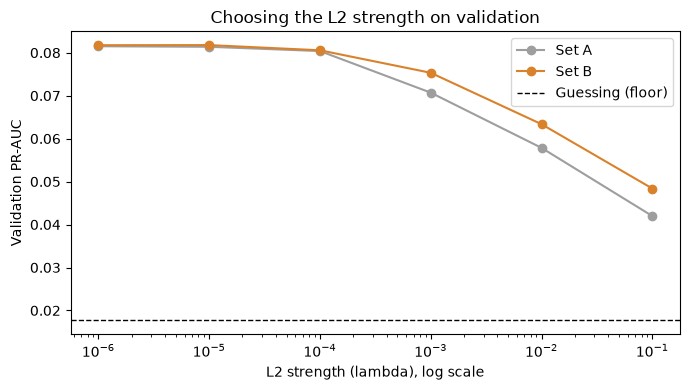

In [54]:
LAMBDAS = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]                          # weak -> strong penalty (extended: the best was at the edge)
results, models = [], {}
for fs, X_tr, X_va in [("A", Xa_train, Xa_val), ("B", Xb_train, Xb_val)]:
    for lam in LAMBDAS:
        w, b, _ = train_logreg(X_tr, y_train, lam=lam, verbose=False)
        p = predict_proba(X_va, w, b)
        models[(fs, lam)] = (w, b)
        results.append({"set": fs, "lambda": lam, "val PR-AUC": average_precision_score(y_val, p),
                        "val ROC-AUC": roc_auc_score(y_val, p), "largest |weight|": np.abs(w).max()})
tune = pd.DataFrame(results)
display(tune.round(4).assign(**{"lambda": tune["lambda"].map("{:.0e}".format)}))   # show 1e-06 instead of 0.0000

best_lam = {fs: float(tune.loc[tune[tune["set"] == fs]["val PR-AUC"].idxmax(), "lambda"]) for fs in ["A", "B"]}
print("Best lambda by val PR-AUC:", best_lam)

fig, ax = plt.subplots(figsize=(7, 4))
for fs, color in [("A", "#9e9e9e"), ("B", "#d9822b")]:
    t = tune[tune["set"] == fs]
    ax.plot(t["lambda"], t["val PR-AUC"], marker="o", color=color, label=f"Set {fs}")
ax.axhline(y_val.mean(), ls="--", color="black", lw=1, label="Guessing (floor)")
ax.set_xscale("log"); ax.set_xlabel("L2 strength (lambda), log scale"); ax.set_ylabel("Validation PR-AUC")
ax.set_title("Choosing the L2 strength on validation"); ax.legend(); plt.tight_layout(); plt.show()

###### is the model better than simple rules? (baselines on validation)

In [55]:
wA, bA = models[("A", best_lam["A"])]
wB, bB = models[("B", best_lam["B"])]
p_val = {"Set A model": predict_proba(Xa_val, wA, bA), "Set B model": predict_proba(Xb_val, wB, bB)}

ku_col = feature_names["A"].index("is_ku")
baselines = {
    "Guessing (same score for every book)": np.zeros(len(y_val)),
    "KU only (in KU = 1, else 0)": Xa_val[:, ku_col],                    # the strongest single feature (5d)
}
cat_rate = train.groupby("category_name")["isBestSeller"].mean()        # category bestseller rate, from TRAIN only
baselines["Category rate (train)"] = val["category_name"].map(cat_rate).fillna(y_train.mean()).to_numpy()

rows = []
for name, s in {**baselines, **p_val}.items():
    rows.append({"method": name, "val PR-AUC": average_precision_score(y_val, s),
                 "val ROC-AUC": roc_auc_score(y_val, s) if np.unique(s).size > 1 else 0.5})
display(pd.DataFrame(rows).set_index("method").round(4))

,val PR-AUC,val ROC-AUC
method,,
Guessing (same score for every book),0.0177,0.5000
"KU only (in KU = 1, else 0)",0.0334,0.6912
Category rate (train),0.0345,0.6878
Set A model,0.0815,0.8283
Set B model,0.0818,0.8344


###### does Set B really beat Set A? Paired bootstrap on validation

In [56]:
rng = np.random.default_rng(SEED)
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(y_val), len(y_val))                          # resample val books with replacement
    if y_val[i].sum() == 0:
        continue
    diffs.append(average_precision_score(y_val[i], p_val["Set B model"][i])
                 - average_precision_score(y_val[i], p_val["Set A model"][i]))
diffs = np.array(diffs)
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"PR-AUC gain of Set B over Set A: {diffs.mean():+.4f}  (95% CI {lo:+.4f} to {hi:+.4f})")
print("The interval includes 0: no clear gain" if lo <= 0 <= hi else "The interval excludes 0: a real gain")

PR-AUC gain of Set B over Set A: +0.0014  (95% CI -0.0056 to +0.0076)
The interval includes 0: no clear gain


###### choose the decision threshold on validation (the cut-off that turns a probability into yes/no)

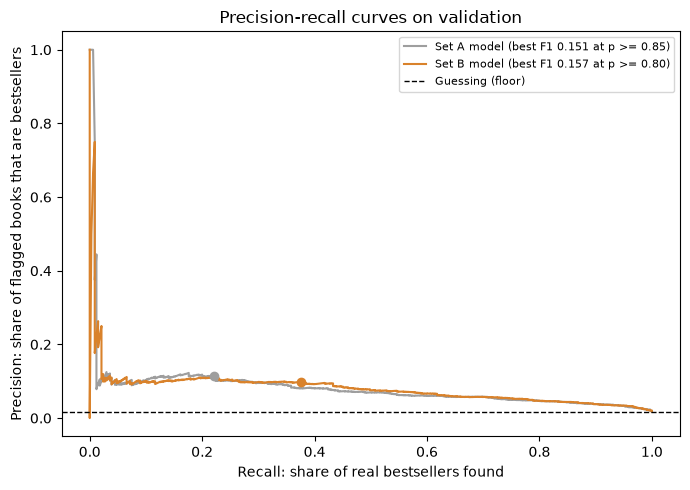

,threshold,flagged,TP,FP,FN,TN,precision,recall
model,,,,,,,,
Set A model,0.852,644,74,570,261,18009,0.115,0.221
Set B model,0.797,1274,126,1148,209,17431,0.099,0.376


In [57]:
fig, ax = plt.subplots(figsize=(7, 5))
thresholds = {}
for name, color in [("Set A model", "#9e9e9e"), ("Set B model", "#d9822b")]:
    prec, rec, thr = precision_recall_curve(y_val, p_val[name])
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    k = np.argmax(f1)                                                    # threshold with the best F1 on val
    thresholds[name] = thr[k]
    ax.plot(rec, prec, color=color, label=f"{name} (best F1 {f1[k]:.3f} at p >= {thr[k]:.2f})")
    ax.scatter(rec[k], prec[k], color=color, zorder=3)
ax.axhline(y_val.mean(), ls="--", color="black", lw=1, label="Guessing (floor)")
ax.set_xlabel("Recall: share of real bestsellers found"); ax.set_ylabel("Precision: share of flagged books that are bestsellers")
ax.set_title("Precision-recall curves on validation"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

rows = []
for name, t in thresholds.items():
    pred = p_val[name] >= t
    tp = int((pred & (y_val == 1)).sum()); fp = int((pred & (y_val == 0)).sum())
    fn = int((~pred & (y_val == 1)).sum()); tn = int((~pred & (y_val == 0)).sum())
    rows.append({"model": name, "threshold": t, "flagged": tp + fp, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1)})
display(pd.DataFrame(rows).set_index("model").round(3))

### Final evaluation on the test set (run once)

###### the ONE run on the test set: same models, same cut-offs, nothing changed after this

In [58]:
p_test = {"Set A model": predict_proba(Xa_test, wA, bA), "Set B model": predict_proba(Xb_test, wB, bB)}
scores = {
    "Guessing": np.zeros(len(y_test)),
    "KU only": Xa_test[:, ku_col],
    "Category rate (train)": test["category_name"].map(cat_rate).fillna(y_train.mean()).to_numpy(),
    **p_test,
}

def boot_ci(y, s, metric, n=1000, seed=SEED):
    """95% bootstrap interval: resample test books, recompute the score, keep the middle 95%."""
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            vals.append(metric(y[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])

rows = []
for name, s in scores.items():
    row = {"method": name, "test PR-AUC": average_precision_score(y_test, s),
           "test ROC-AUC": roc_auc_score(y_test, s) if np.unique(s).size > 1 else 0.5}
    if name in p_test:                                                   # intervals for the two models
        lo, hi = boot_ci(y_test, s, average_precision_score)
        row["PR-AUC 95% CI"] = f"{lo:.4f} to {hi:.4f}"
        pred = s >= thresholds[name]                                     # cut-off chosen on VALIDATION (T4)
        tp = int((pred & (y_test == 1)).sum()); fp = int((pred & (y_test == 0)).sum())
        fn = int((~pred & (y_test == 1)).sum())
        prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
        row.update({"flagged": tp + fp, "TP": tp, "precision": prec, "recall": rec,
                    "F1": 2 * prec * rec / max(prec + rec, 1e-12)})
    rows.append(row)
display(pd.DataFrame(rows).set_index("method").round(4).fillna(""))

rng = np.random.default_rng(SEED)
d = []
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    if y_test[i].sum() > 0:
        d.append(average_precision_score(y_test[i], p_test["Set B model"][i])
                 - average_precision_score(y_test[i], p_test["Set A model"][i]))
lo, hi = np.percentile(d, [2.5, 97.5])
print(f"Test: PR-AUC gain of Set B over Set A {np.mean(d):+.4f} (95% CI {lo:+.4f} to {hi:+.4f})")

,test PR-AUC,test ROC-AUC,PR-AUC 95% CI,flagged,TP,precision,recall,F1
method,,,,,,,,
Guessing,0.0177,0.5000,,,,,,
KU only,0.0325,0.6854,,,,,,
Category rate (train),0.0309,0.6593,,,,,,
Set A model,0.0668,0.8071,0.0551 to 0.0837,557.0,59.0,0.1059,0.1766,0.1324
Set B model,0.0739,0.8245,0.0609 to 0.0930,1207.0,101.0,0.0837,0.3024,0.1311


Test: PR-AUC gain of Set B over Set A +0.0074 (95% CI +0.0011 to +0.0148)


###### what the ranking is worth in practice: check only the books the model ranks highest

In [59]:
rows = []
for share in [0.01, 0.05, 0.10, 0.20]:
    k = int(round(share * len(y_test)))                                  # number of books checked
    row = {"top share of books checked": f"{share:.0%}", "books checked": k}
    for name in ["KU only", "Set A model", "Set B model"]:
        s = scores[name] + np.random.default_rng(SEED).random(len(y_test)) * 1e-9   # tiny tie-breaker for KU's 0/1 scores
        top = np.argsort(-s)[:k]
        found = int(y_test[top].sum())
        row[f"{name}: bestsellers found"] = found
        row[f"{name}: hit rate"] = found / k
    rows.append(row)
lift = pd.DataFrame(rows).set_index("top share of books checked")
display(lift.round(3))
print(f"Random checking finds bestsellers at the base rate: {y_test.mean():.2%} "
      f"({int(y_test.sum())} bestsellers in {len(y_test):,} test books)")

,books checked,KU only: bestsellers found,KU only: hit rate,Set A model: bestsellers found,Set A model: hit rate,Set B model: bestsellers found,Set B model: hit rate
top share of books checked,,,,,,,
1%,189,7,0.037,22,0.116,19,0.101
5%,946,43,0.045,71,0.075,89,0.094
10%,1891,88,0.047,124,0.066,134,0.071
20%,3782,157,0.042,210,0.056,229,0.061


Random checking finds bestsellers at the base rate: 1.77% (334 bestsellers in 18,911 test books)


###### what the model learned: the Set A weights as odds multipliers

,weight,odds x,kind
feature,,,
pub_De Marque,2.752,15.667,yes vs no / vs reference
cat_Children's eBooks,2.000,7.388,yes vs no / vs reference
is_ku,1.998,7.377,yes vs no / vs reference
cat_Nonfiction,1.661,5.264,yes vs no / vs reference
cat_Science & Math,1.580,4.855,yes vs no / vs reference
cat_Business & Money,1.360,3.898,yes vs no / vs reference
cat_Politics & Social Sciences,1.348,3.852,yes vs no / vs reference
cat_Biographies & Memoirs,1.238,3.450,yes vs no / vs reference
cat_History,1.184,3.266,yes vs no / vs reference


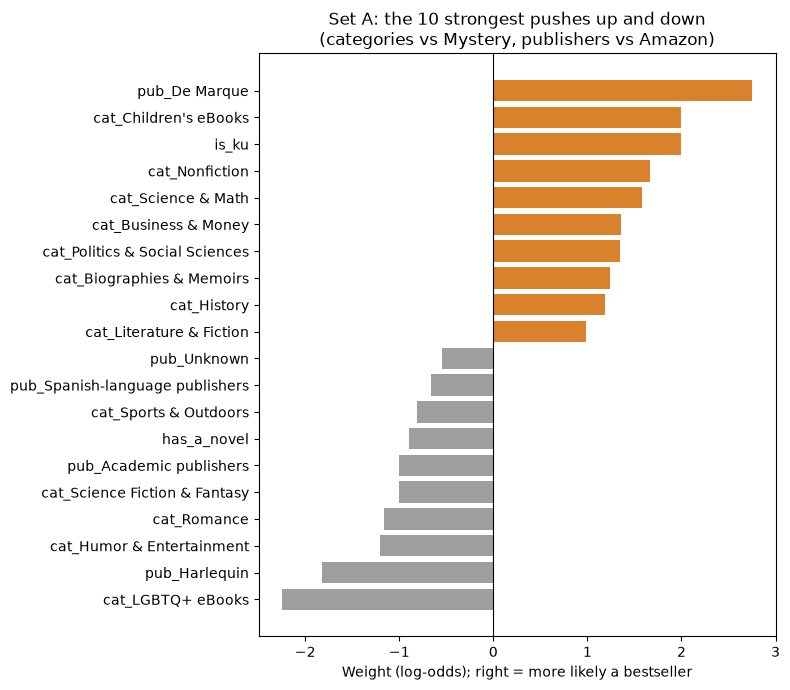

In [60]:
coef = pd.DataFrame({"feature": feature_names["A"], "weight": wA})
coef["odds x"] = np.exp(coef["weight"])                                  # e^weight = how the odds multiply
coef["kind"] = np.where(coef["feature"].isin(SCALE_COLS), "per 1 std", "yes vs no / vs reference")
coef = coef.sort_values("weight")
display(pd.concat([coef.tail(10).iloc[::-1], coef.head(10)]).set_index("feature").round(3))

show = pd.concat([coef.head(10), coef.tail(10)])
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(show["feature"], show["weight"], color=np.where(show["weight"] > 0, "#d9822b", "#9e9e9e"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Weight (log-odds); right = more likely a bestseller")
ax.set_title("Set A: the 10 strongest pushes up and down\n(categories vs Mystery, publishers vs Amazon)")
plt.tight_layout(); plt.show()

###### how much evidence sits behind each big weight? (counts from TRAIN, 0/1 columns only)

In [61]:
Xtr = raw[("A", "train")]
ev = show[~show["feature"].isin(SCALE_COLS)].copy()
ev["train books with it"] = [int(Xtr[f].sum()) for f in ev["feature"]]
ev["of which bestsellers"] = [int((Xtr[f] * y_train).sum()) for f in ev["feature"]]
ev["bestseller rate"] = ev["of which bestsellers"] / ev["train books with it"]
ev["evidence"] = np.where(ev["of which bestsellers"] < 30, "thin (< 30 bestsellers)", "solid")
display(ev.sort_values("weight", ascending=False).set_index("feature")
          [["weight", "odds x", "train books with it", "of which bestsellers", "bestseller rate", "evidence"]].round(3))
print(f"Reference groups: Mystery {int((train['category_name'] == REF_CATEGORY).sum()):,} train books | "
      f"Amazon {int((train['publisher_grp'] == REF_PUBLISHER).sum()):,} train books")

,weight,odds x,train books with it,of which bestsellers,bestseller rate,evidence
feature,,,,,,
pub_De Marque,2.752,15.667,126,24,0.190,thin (< 30 bestsellers)
cat_Children's eBooks,2.000,7.388,3792,114,0.030,solid
is_ku,1.998,7.377,24688,1031,0.042,solid
cat_Nonfiction,1.661,5.264,604,35,0.058,solid
cat_Science & Math,1.580,4.855,3850,120,0.031,solid
cat_Business & Money,1.360,3.898,1771,43,0.024,solid
cat_Politics & Social Sciences,1.348,3.852,2740,75,0.027,solid
cat_Biographies & Memoirs,1.238,3.450,3049,87,0.029,solid
cat_History,1.184,3.266,1286,47,0.037,solid


Reference groups: Mystery 3,746 train books | Amazon 58,644 train books


**Final results (test set, run once)**
- Set A (pre-launch only): test PR-AUC 0.067 (95% CI 0.055–0.084), ROC-AUC 0.81, about 3.8× guessing (0.018) and about 2× the best single rule (KU only, 0.033).
- Set B (+ stars, reviews, age): test PR-AUC 0.074 (0.061–0.093), ROC-AUC 0.82. Gain over Set A: +0.007 (95% CI +0.001 to +0.015) on test, but not significant on validation, so after-launch signals add at most a small gain.
- Test scores are slightly below validation (0.082), as expected after picking the best of 6 settings; the validation score lies inside the test CI, so the model generalises.
- The validation cut-off transferred: Set A flags 557 test books at 10.6% precision (validation 11.5%), about 6× random.
- In practice: checking the model's top 20% of books finds 63% (Set A) to 69% (Set B) of all bestsellers.
- Strongest drivers (vs a Mystery book from Amazon, all else equal): KU ×7.4; non-fiction categories ×3–7 (Children's ×7.4 despite a lower raw rate than Literature & Fiction, so holding the other features equal matters); genre fiction (Romance, SF & Fantasy, Humor) ×0.3–0.4; "A Novel" titles ×0.4. Associations, not causes.
- Evidence check (E4): positive weights rest on 35–1,031 bestsellers each. De Marque (×15.7) rests on only 126 books. Negative weights are reliable in direction (thousands of books, very few bestsellers) but not in exact size. Harlequin has 0 bestsellers in 271 books (separation): its weight is held finite only by the L2 penalty and the stopping rule, so it is not a real estimate.

### Model in use (actually tell the bookstore which books will be BestSellers)

###### the model in use: which test books does it flag as likely bestsellers?

In [62]:
view = test[["title", "author", "category_name", "price", "isKindleUnlimited", "publisher_grp", "isBestSeller"]].copy()
view["score"] = p_test["Set A model"]                                    # Set A: needs only facts known before launch
view["rank"] = view["score"].rank(ascending=False, method="first").astype(int)   # 1 = most likely bestseller
view["flagged"] = view["score"] >= thresholds["Set A model"]             # cut-off chosen on validation (T4)
view = view.sort_values("rank")

flagged = view[view["flagged"]]
print(f"Set A flags {len(flagged):,} of {len(view):,} test books as likely bestsellers; "
      f"{int(flagged['isBestSeller'].sum())} of them really are ({flagged['isBestSeller'].mean():.1%}).")
with pd.option_context("display.max_colwidth", 60):
    display(flagged.head(25)[["rank", "title", "author", "category_name", "price",
                              "isKindleUnlimited", "publisher_grp", "score", "isBestSeller"]].round(3))

Set A flags 557 of 18,911 test books as likely bestsellers; 59 of them really are (10.6%).


,rank,title,author,category_name,price,isKindleUnlimited,publisher_grp,score,isBestSeller
88864,1,Ulysses,James Joyce,Nonfiction,0.00,False,De Marque,0.983,False
43100,2,The Mis-Education of the Negro: The Original 1933 Unabri...,Carter Godwin Woodson,Politics & Social Sciences,0.00,False,De Marque,0.980,False
15648,3,The Art Of Game Theory: How To Win Life’s Ultimate Payof...,Wisdom University,Science & Math,0.00,True,Amazon,0.978,False
42049,4,Jane Eyre: The Original 1847 Unabridged and Complete Edi...,Charlotte Bronte,Politics & Social Sciences,0.00,False,De Marque,0.978,False
42426,5,The Federalist Papers,Alexander Hamilton,Politics & Social Sciences,0.00,False,De Marque,0.978,True
43954,6,Common Sense: The Unabridged and Complete Edition (Thoma...,Thomas Paine,Politics & Social Sciences,0.00,False,De Marque,0.976,False
122459,7,The Legend of Dave the Villager Books 6-10 Illustrated: ...,Dave Villager,Children's eBooks,0.00,True,Unknown,0.976,False
85642,8,The Art Of War,Sun Tzu,History,0.00,False,De Marque,0.974,False
114150,9,"Sell Futures, Not Features: How anyone can uncover hidde...",Michael Killen,Business & Money,0.99,True,Amazon,0.970,False
106062,10,The Power of Your Subconscious Mind,Joseph Murphy,"Health, Fitness & Dieting",0.00,False,De Marque,0.970,False


###### where the model goes wrong: confident false alarms and missed bestsellers

In [63]:
flag = view[view["flagged"]].copy()
flag["price group"] = np.select([flag["price"] == 0, flag["price"] < 2.99], ["free ($0.00)", "under $2.99"], "$2.99 and up")
flag["De Marque"] = np.where(flag["publisher_grp"] == "De Marque", "De Marque", "other publishers")
summary = (flag.groupby(["price group", "De Marque"])["isBestSeller"]
               .agg(flagged="size", bestsellers="sum").reset_index())
summary["precision"] = summary["bestsellers"] / summary["flagged"]
print("Flagged books, split by price and publisher (precision = share that really are bestsellers)")
display(summary.round(3))

cols = ["rank", "title", "author", "category_name", "price", "isKindleUnlimited", "publisher_grp", "score"]
with pd.option_context("display.max_colwidth", 60):
    print("Missed: real bestsellers the model ranked lowest")
    display(view[view["isBestSeller"]].tail(10)[cols].round(3))

missed = view[view["isBestSeller"] & ~view["flagged"]]
caught = view[view["isBestSeller"] & view["flagged"]]
print(f"Bestsellers missed at the cut-off: {len(missed)} of {int(view['isBestSeller'].sum())} | "
      f"share in KU: missed {missed['isKindleUnlimited'].mean():.0%} vs caught {caught['isKindleUnlimited'].mean():.0%}")

Flagged books, split by price and publisher (precision = share that really are bestsellers)


,price group,De Marque,flagged,bestsellers,precision
0,$2.99 and up,De Marque,3,0,0.000
1,$2.99 and up,other publishers,349,45,0.129
2,free ($0.00),De Marque,19,3,0.158
3,free ($0.00),other publishers,37,1,0.027
4,under $2.99,De Marque,1,0,0.000
5,under $2.99,other publishers,148,10,0.068


Missed: real bestsellers the model ranked lowest


,rank,title,author,category_name,price,isKindleUnlimited,publisher_grp,score
64079,13172,Pucking Around: A Why Choose Hockey Romance (Jacksonvill...,Emily Rath,LGBTQ+ eBooks,5.99,True,Amazon,0.171
89256,13605,"Help Me, I'm Stuck: Six Proven Methods to Shift Your Min...",Vaughn Carter,Self-Help,9.99,False,Amazon,0.161
45,13671,Real Food for Pregnancy: The Science and Wisdom of Optim...,Lily Nichols,Parenting & Relationships,9.99,False,Amazon,0.159
116190,14662,The Brussels Effect: How the European Union Rules the World,Anu Bradford,Law,9.99,False,Amazon,0.139
64272,15084,One (Angels of Wrath Book 1),Paulina Ian-Kane,LGBTQ+ eBooks,3.99,True,Amazon,0.128
64566,15468,When Dreams Change,Violet Morley,LGBTQ+ eBooks,3.99,True,Amazon,0.118
99412,16339,The 'Ohana Grill Cookbook: Easy and Delicious Hawai'i-In...,Dawn Sakamoto Paiva,"Cookbooks, Food & Wine",15.15,False,Amazon,0.095
107645,16860,Bowling Beyond the Basics: What's Really Happening on th...,James Freeman,Sports & Outdoors,9.99,False,Amazon,0.081
5021,18156,Interpersonal Process in Therapy: An Integrative Model,Edward Teyber,Engineering & Transportation,41.99,False,Academic publishers,0.048
95908,18562,"Introduction to Documentary, Third Edition",Bill Nichols,Humor & Entertainment,14.74,False,Amazon,0.034


Bestsellers missed at the cut-off: 275 of 334 | share in KU: missed 58% vs caught 93%


###### score a brand-new book before launch (what the book press would actually do)

In [64]:
a_scale_cols = [c for c in SCALE_COLS if c in feature_names["A"]]
a_mean = raw[("A", "train")][a_scale_cols].mean()                        # same train numbers as F3
a_std = raw[("A", "train")][a_scale_cols].std()

def score_new_books(books):
    """books: list of dicts with title, author, price, isKindleUnlimited, category_name, soldBy."""
    new = pd.DataFrame(books)
    new["publisher_grp"] = new["soldBy"].map(publisher_group)            # same seller grouping as 5b / P3
    X = build_features(new, fit, "A", is_train=False)                    # same features as the model saw
    X[a_scale_cols] = (X[a_scale_cols] - a_mean) / a_std                 # same scaling as F3
    new["score"] = predict_proba(X[feature_names["A"]].to_numpy(), wA, bA)
    new["flagged"] = new["score"] >= thresholds["Set A model"]
    new["beats % of test books"] = [(p_test["Set A model"] < s).mean() for s in new["score"]]
    return new

example = score_new_books([
    {"title": "The Quiet Orchard: A Novel", "author": "New Author", "price": 16.99,
     "isKindleUnlimited": False, "category_name": "Literature & Fiction", "soldBy": "Penguin Random House LLC"},
    {"title": "Small Habits for Busy Parents: A Practical Guide", "author": "New Author", "price": 2.99,
     "isKindleUnlimited": True, "category_name": "Parenting & Relationships", "soldBy": "Amazon.com Services LLC"},
    {"title": "Dinosaur Days", "author": "New Author", "price": 0.99,
     "isKindleUnlimited": True, "category_name": "Children's eBooks", "soldBy": "Amazon.com Services LLC"},
])
display(example[["title", "price", "isKindleUnlimited", "category_name", "publisher_grp",
                 "score", "beats % of test books", "flagged"]].round(3))

,title,price,isKindleUnlimited,category_name,publisher_grp,score,beats % of test books,flagged
0,The Quiet Orchard: A Novel,16.99,False,Literature & Fiction,Penguin Random House,0.181,0.329,False
1,Small Habits for Busy Parents: A Practical Guide,2.99,True,Parenting & Relationships,Amazon,0.576,0.789,False
2,Dinosaur Days,0.99,True,Children's eBooks,Amazon,0.957,0.998,True


**Model in use**
- The top of the ranking is dominated by free books (all of the top 25 cost $0.00–0.99; only 2 are bestsellers). Split by group (E6), flagged books priced $2.99 and up are bestsellers 12.9% of the time, under $2.99 only 6.8%, and free books from publishers other than De Marque only 2.7% (1 of 37), barely above the 1.77% base rate. De Marque's free classics do well (15.8%). The straight-line price feature pushes cheap books too high, and free books most of all, although EDA showed free books are only average outside De Marque.
- 275 of the 334 test bestsellers are missed at the cut-off. The model leans on KU: 93% of the bestsellers it catches are in KU, against 58% of those it misses. Non-KU bestsellers, and KU books in low-weight categories (e.g. LGBTQ+), are its blind spots.
- New books can be scored before launch : a $0.99 KU children's book outranks 99.8% of test books, while a $16.99 Penguin Random House literary novel outranks 33%.

### Explanation Figures and saving the model

###### Why one bestseller was caught and another was missed: the model's running total, push by push

The Stoic way of Life: The Ultimate Guid total +3.298 | score 0.964 (E5 says 0.964)
Pucking Around: A Why Choose Hockey Roma total -1.579 | score 0.171 (E5 says 0.171)


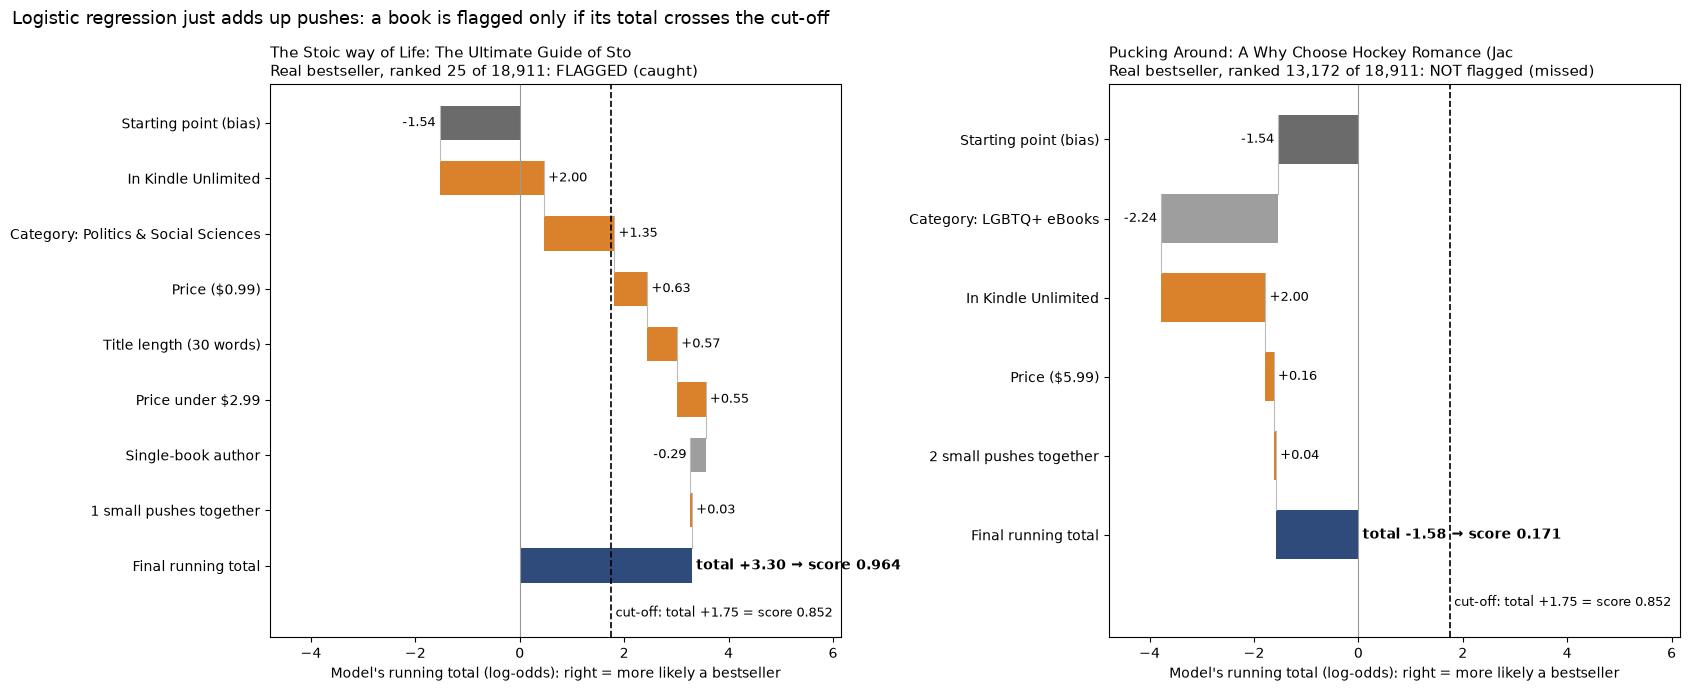

In [65]:
BOOKS = [("The Stoic way of Life", "caught"), ("Pucking Around", "missed")]   # titles to look up in the test set (E5's view)
CUT = thresholds["Set A model"]
cut_total = np.log(CUT / (1 - CUT))                                          # the cut-off on the running-total scale

def pretty(f, idx):
    """A readable name for a feature, with the book's own value where it helps."""
    if f == "is_ku": return "In Kindle Unlimited"
    if f == "log_price": return f"Price (${test.loc[idx, 'price']:.2f})"
    if f == "is_under_2_99": return "Price under $2.99"
    if f == "title_words": return f"Title length ({int(raw[('A', 'test')].loc[idx, 'title_words'])} words)"
    if f == "single_book_author": return "Single-book author"
    if f == "has_colon": return "Colon in title"
    if f == "has_a_novel": return '"A Novel" in title'
    if f.startswith("cat_"): return "Category: " + f[4:]
    if f.startswith("pub_"): return "Publisher: " + f[4:]
    return f

fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharex=True)
lo, hi = 0.0, 0.0                                                            # widest running total, to fit both panels
for ax, (needle, outcome) in zip(axes, BOOKS):
    match = view[view["title"].str.contains(needle, case=False, regex=False)]
    if match.empty:
        ax.set_title(f"'{needle}' not found in the test set"); ax.axis("off"); continue
    idx = match.index[0]                                                      # highest-ranked edition of that title
    all_push = pd.Series(data[("A", "test")].loc[idx].to_numpy() * wA, index=feature_names["A"])   # push = number x weight
    big = all_push[all_push.abs() >= 0.05]                                    # pushes that visibly move this book
    big = big.reindex(big.abs().sort_values(ascending=False).index)           # biggest first
    steps = [("Starting point (bias)", bA)] + [(pretty(f, idx), v) for f, v in big.items()]
    rest = all_push.sum() - big.sum()                                         # every tiny push together
    if abs(rest) >= 0.005:
        steps.append((f"{(all_push.abs() > 0).sum() - len(big)} small pushes together", rest))
    total = bA + all_push.sum()
    score = 1 / (1 + np.exp(-total))                                          # the sigmoid turns the total into the score

    run = 0.0
    for i, (name, v) in enumerate(steps):
        colour = "#6b6b6b" if i == 0 else ("#d9822b" if v > 0 else "#9e9e9e")  # orange = pushes up, grey = pushes down
        ax.barh(i, v, left=run, color=colour, height=0.62)
        if v >= 0:
            ax.text(run + v + 0.08, i, f"{v:+.2f}", va="center", ha="left", fontsize=9)
        else:
            ax.text(run + v - 0.08, i, f"{v:+.2f}", va="center", ha="right", fontsize=9)
        if i > 0:
            ax.plot([run, run], [i - 1.31, i - 0.31], color="#bbbbbb", lw=0.8)  # thin link from the previous running total
        lo, hi = min(lo, run + v, run), max(hi, run + v, run)
        run += v
    last = len(steps)
    ax.plot([run, run], [last - 1.31, last - 0.31], color="#bbbbbb", lw=0.8)
    ax.barh(last, total, color="#2f4b7c", height=0.62)
    ax.text(max(0, total) + 0.08, last, f"total {total:+.2f} → score {score:.3f}", va="center", fontsize=10, fontweight="bold")
    ax.axvline(cut_total, color="black", ls="--", lw=1.2)
    ax.text(cut_total + 0.08, last + 0.85, f"cut-off: total {cut_total:+.2f} = score {CUT:.3f}", fontsize=9, va="center")
    ax.axvline(0, color="#999999", lw=0.8)
    ax.set_yticks(range(last + 1)); ax.set_yticklabels([s for s, _ in steps] + ["Final running total"])
    ax.set_ylim(last + 1.3, -0.7)                                             # top to bottom, with room for the cut-off label
    lo, hi = min(lo, total, cut_total), max(hi, total, cut_total)
    r = view.loc[idx]
    verdict = "FLAGGED (caught)" if score >= CUT else "NOT flagged (missed)"
    ax.set_title(f"{str(r['title'])[:48]}\nReal bestseller, ranked {int(r['rank']):,} of {len(view):,}: {verdict}",
                 loc="left", fontsize=11)
    ax.set_xlabel("Model's running total (log-odds): right = more likely a bestseller")
    print(f"{str(r['title'])[:40]:40s} total {total:+.3f} | score {score:.3f} (E5 says {r['score']:.3f})")
axes[0].set_xlim(lo - 1.0, hi + 2.6)                                         # room for the value labels
fig.suptitle("Logistic regression just adds up pushes: a book is flagged only if its total crosses the cut-off",
             fontsize=13, x=0.01, ha="left")
plt.tight_layout(); fig.savefig(FIG_DIR / "fig_why_caught_or_missed.png", dpi=150, bbox_inches="tight"); plt.show()

###### Watching gradient descent learn: the six strongest weights, step by step, ending on scikit-learn's answer

Converged after 6,452 steps | biggest gap to scikit-learn over all 48 weights: 0.0052


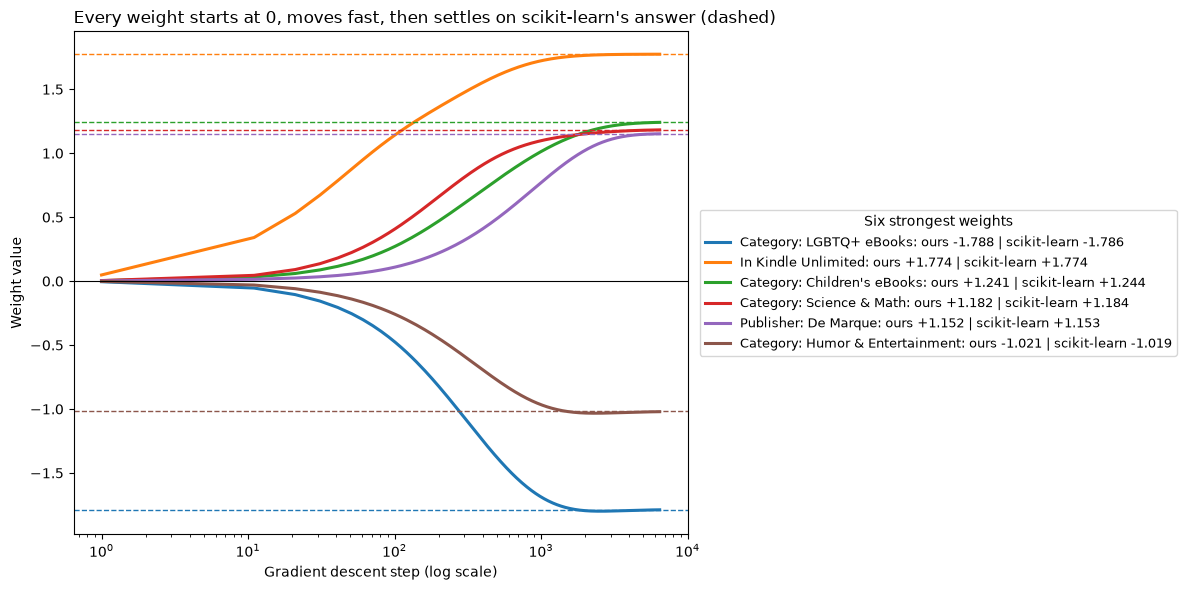

In [66]:
def nice_name(f):
    """A readable name for a feature column (this cell's own copy, so it runs on its own)."""
    names = {"is_ku": "In Kindle Unlimited", "log_price": "Price (log)", "is_under_2_99": "Price under $2.99",
             "title_words": "Title length", "single_book_author": "Single-book author",
             "has_colon": "Colon in title", "has_a_novel": '"A Novel" in title'}
    if f in names: return names[f]
    if f.startswith("cat_"): return "Category: " + f[4:]
    if f.startswith("pub_"): return "Publisher: " + f[4:]
    return f

LAM = 1e-3                                                                   # same setting as M3 and the M4 scikit-learn check
sw, _ = class_weights(y_train)
w, b, prev = np.zeros(Xa_train.shape[1]), 0.0, None
snap_step, snap_w = [], []
for it in range(20000):                                                      # the same loop as train_logreg (M3) ...
    loss, gw, gb = loss_and_grad(w, b, Xa_train, y_train, sw, LAM)
    w -= 0.5 * gw
    b -= 0.5 * gb
    if it % 10 == 0:                                                         # ... plus a snapshot of every weight every 10 steps
        snap_step.append(it + 1); snap_w.append(w.copy())
    if prev is not None and abs(prev - loss) < 1e-10:
        break
    prev = loss
snap_step.append(it + 1); snap_w.append(w.copy())
snap_w = np.array(snap_w)

sk = LogisticRegression(C=1 / (len(y_train) * LAM), max_iter=5000, tol=1e-10)
sk.fit(Xa_train, y_train, sample_weight=sw)                                  # the referee: same loss, solved its own way
top = np.argsort(-np.abs(w))[:6]                                             # the six strongest final weights
print(f"Converged after {it + 1:,} steps | biggest gap to scikit-learn over all 48 weights: "
      f"{np.max(np.abs(w - sk.coef_[0])):.4f}")

fig, ax = plt.subplots(figsize=(12, 6))
colours = plt.cm.tab10(np.arange(6))
for c, j in zip(colours, top):
    ax.plot(snap_step, snap_w[:, j], color=c, lw=2.2,
            label=f"{nice_name(feature_names['A'][j])}: ours {w[j]:+.3f} | scikit-learn {sk.coef_[0][j]:+.3f}")
    ax.axhline(sk.coef_[0][j], color=c, ls="--", lw=1)                       # where scikit-learn says the weight should end
ax.axhline(0, color="black", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("Gradient descent step (log scale)")
ax.set_ylabel("Weight value")
ax.set_title("Every weight starts at 0, moves fast, then settles on scikit-learn's answer (dashed)",
             loc="left", fontsize=12)
ax.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.01, 0.5), title="Six strongest weights")
plt.tight_layout(); fig.savefig(FIG_DIR / "fig_gradient_descent_learning.png", dpi=150, bbox_inches="tight"); plt.show()

###### What the model does to 1,000 books: why accuracy was dropped, and what precision and recall mean

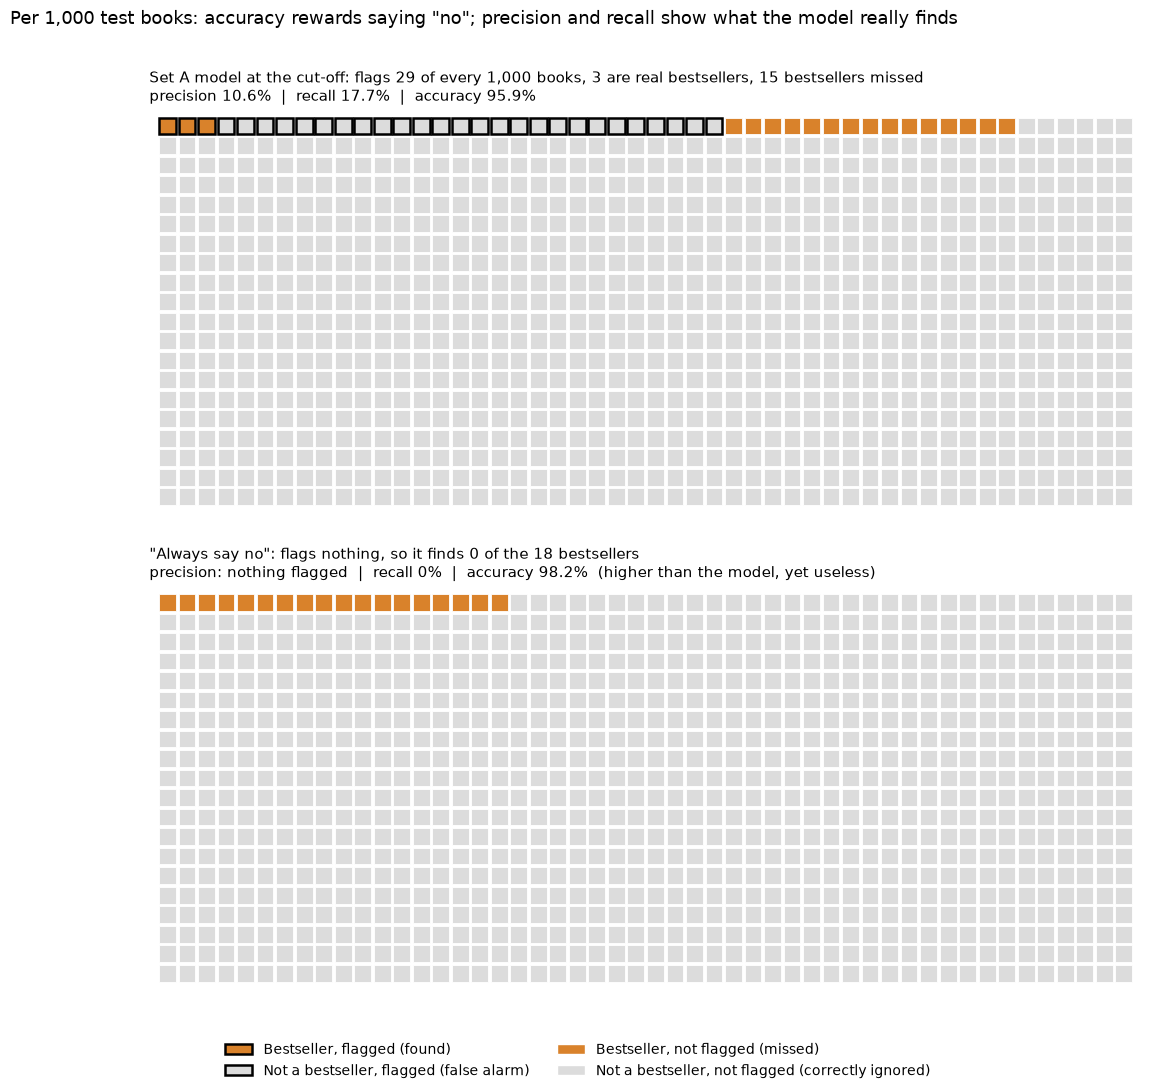

Real counts on 18,911 test books: found 59, false alarms 498, missed 275, correctly ignored 18,079


In [67]:
N = len(y_test)
pred = p_test["Set A model"] >= thresholds["Set A model"]
tp = int((pred & (y_test == 1)).sum()); fp = int((pred & (y_test == 0)).sum())
fn = int((~pred & (y_test == 1)).sum()); tn = N - tp - fp - fn
per = lambda count: int(round(count / N * 1000))                            # scale a count to "per 1,000 books"
TP, FP, FN = per(tp), per(fp), per(fn)
TN = 1000 - TP - FP - FN
acc_model, acc_no = (tp + tn) / N, (tn + fp) / N                             # accuracy: model vs "always say no"
ORANGE, LIGHT = "#d9822b", "#dcdcdc"

def grid(ax, kinds, title):
    cols = 50                                                                # 50 x 20 = 1,000 squares
    for k, kind in enumerate(kinds):
        row, col = divmod(k, cols)
        face = ORANGE if kind in ("TP", "FN") else LIGHT
        edge, lw = ("black", 1.8) if kind in ("TP", "FP") else ("white", 0.6)
        ax.add_patch(plt.Rectangle((col, -row), 0.86, 0.86, facecolor=face, edgecolor=edge, linewidth=lw))
    ax.set_xlim(-0.5, cols + 0.5); ax.set_ylim(-20.3, 1.3); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, loc="left", fontsize=11)

fig, axes = plt.subplots(2, 1, figsize=(13, 11))
grid(axes[0], ["TP"] * TP + ["FP"] * FP + ["FN"] * FN + ["TN"] * TN,
     f"Set A model at the cut-off: flags {TP + FP} of every 1,000 books, {TP} are real bestsellers, {FN} bestsellers missed\n"
     f"precision {tp / (tp + fp):.1%}  |  recall {tp / (tp + fn):.1%}  |  accuracy {acc_model:.1%}")
grid(axes[1], ["FN"] * (TP + FN) + ["TN"] * (1000 - TP - FN),
     f"\"Always say no\": flags nothing, so it finds 0 of the {TP + FN} bestsellers\n"
     f"precision: nothing flagged  |  recall 0%  |  accuracy {acc_no:.1%}  (higher than the model, yet useless)")
fig.legend(handles=[Patch(facecolor=ORANGE, edgecolor="black", linewidth=1.8, label="Bestseller, flagged (found)"),
                    Patch(facecolor=LIGHT, edgecolor="black", linewidth=1.8, label="Not a bestseller, flagged (false alarm)"),
                    Patch(facecolor=ORANGE, edgecolor="white", label="Bestseller, not flagged (missed)"),
                    Patch(facecolor=LIGHT, edgecolor="white", label="Not a bestseller, not flagged (correctly ignored)")],
           loc="lower center", ncol=2, fontsize=10, frameon=False)
fig.suptitle("Per 1,000 test books: accuracy rewards saying \"no\"; precision and recall show what the model really finds",
             fontsize=13, x=0.01, ha="left")
plt.tight_layout(rect=(0, 0.06, 1, 0.97)); fig.savefig(FIG_DIR / "fig_1000_books.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Real counts on {N:,} test books: found {tp}, false alarms {fp}, missed {fn}, correctly ignored {tn:,}")

###### Save the from-scratch Set A model to one file, reload it into fresh variables, and prove it still gives the same scores

In [68]:
MODEL_DIR = Path("..") / "models"                                           # the project's models folder (next to notebooks/)
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "bestseller_setA_logreg.json"

scale_cols = [c for c in SCALE_COLS if c in feature_names["A"]]             # log_price, title_words
model_file = {
    "model": "Logistic regression from scratch (NumPy), Set A: pre-launch features only",
    "saved_on": str(date.today()),
    "lambda": float(best_lam["A"]),
    "cut_off": float(thresholds["Set A model"]),                            # chosen on validation (T4)
    "features": list(feature_names["A"]),                                   # the exact column order the weights belong to
    "weights": [float(v) for v in wA],
    "bias": float(bA),
    "scale_mean": {c: float(raw[("A", "train")][c].mean()) for c in scale_cols},   # training mean and spread (F3)
    "scale_std": {c: float(raw[("A", "train")][c].std()) for c in scale_cols},
    "categories": list(fit["categories"]), "reference_category": REF_CATEGORY,      # F1
    "publishers": list(fit["publishers"]), "reference_publisher": REF_PUBLISHER,
    "author_books": {str(a): int(n) for a, n in fit["author_books"].items()},       # books per author in training (F1)
}
MODEL_PATH.write_text(json.dumps(model_file))
print(f"Saved to {MODEL_PATH.resolve()} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")


def score_with_saved(books, m):
    """Score books with a saved model file. books: DataFrame with title, author, price,
    isKindleUnlimited, category_name and publisher_grp (make it from soldBy with publisher_group, cell 5b)."""
    X = pd.DataFrame(index=books.index)
    title = books["title"].str.lower()
    X["is_ku"] = books["isKindleUnlimited"].astype(int)
    X["log_price"] = np.log1p(books["price"])
    X["is_under_2_99"] = (books["price"] < 2.99).astype(int)
    for c in m["categories"]:
        X[f"cat_{c}"] = (books["category_name"] == c).astype(int)
    for p in m["publishers"]:
        X[f"pub_{p}"] = (books["publisher_grp"] == p).astype(int)
    n_books = books["author"].map(m["author_books"]).fillna(0) + 1          # earlier books by this author + this book
    X["single_book_author"] = ((n_books == 1) & books["author"].notna()).astype(int)
    X["title_words"] = books["title"].str.split().str.len().clip(upper=30)
    X["has_colon"] = title.str.contains(":", regex=False).astype(int)
    X["has_a_novel"] = title.str.contains("a novel", regex=False).astype(int)
    for c in m["scale_mean"]:
        X[c] = (X[c] - m["scale_mean"][c]) / m["scale_std"][c]
    z = X[m["features"]].to_numpy(dtype=float) @ np.array(m["weights"]) + m["bias"]
    score = 1 / (1 + np.exp(-np.clip(z, -30, 30)))
    return pd.DataFrame({"score": score, "flagged": score >= m["cut_off"]}, index=books.index)


saved = json.loads(MODEL_PATH.read_text())                                  # reload into a fresh variable
check = score_with_saved(val, saved)
p_live = predict_proba(Xa_val, wA, bA)                                      # the model still in memory
print(f"Reloaded model vs model in memory, {len(val):,} validation books: "
      f"largest score difference {np.max(np.abs(check['score'].to_numpy() - p_live)):.2e} | "
      f"same flag decision on {np.mean(check['flagged'].to_numpy() == (p_live >= saved['cut_off'])):.2%}")

Saved to /home/francois/projects/bestseller_lr/models/bestseller_setA_logreg.json (1.2 MB)
Reloaded model vs model in memory, 18,914 validation books: largest score difference 0.00e+00 | same flag decision on 100.00%


###### Saving and reusing the model. The trained Set A model is saved as one readable file, models/bestseller_setA_logreg.json. It holds everything needed to score a book: the 48 weights and the bias, the exact feature order, the cut-off chosen on validation (0.852), the training mean and spread used for scaling, the category and publisher lists, and each author’s training book count. Nothing has to be retrained. To reuse it, load the file with json.loads(Path(...).read_text()), put the new titles in a table with title, author, price, isKindleUnlimited, category_name and publisher_grp (made from the seller name with publisher_group, cell 5b), and call score_with_saved(books, saved). It returns each book’s score and whether it passes the cut-off. The reloaded model was checked against the one in memory and produced identical scores on all 18,914 validation books. As with the model itself, the score is a ranking (higher means more likely a bestseller), not a percentage chance.

## Limitations

**Data**
- **One snapshot.** The data is a single scrape (around October 2023). "Bestseller" means "had the badge on that day", so books that were bestsellers before or after it count as non-bestsellers, and the model cannot see timing.
- **Weak after-launch signals.** 58,341 review counts were lost (stars shown with 0 reviews), 47,085 books have no date, and stars barely vary (most books sit at 4.3–4.7). Set B's small gain may undersell what clean review and sales history could add.
- **Removed badge books.** The 7,023 Editors' Pick / Goodreads Choice books contained 0 bestsellers against about 118 expected, suggesting a scraping effect. They were removed, so the results do not cover those books.
- **Hand-built groups.** Publisher groups come from text rules on `soldBy` (8,507 books "Unknown"). Same-book matching uses title + author, so editions with different titles could still sit in different splits.
- **Print-format words kept.** 92 titles mention hardcover/paperback; they were checked and kept because every row is a Kindle listing.

**Model**
- **Straight-line model.** Logistic regression adds effects together. It cannot learn that KU might help more in one category than another unless such interaction columns are added.
- **Free and very cheap books are over-ranked.** `log_price` treats "cheaper" as "better" all the way down to $0. Among flagged test books, precision is 12.9% at $2.99 and up, 6.8% under $2.99, and 2.7% for free books outside De Marque, close to random. EDA showed free books are only average outside De Marque, so the real price effect is not a straight line. An `is_free` flag or price bands would let the model learn this; they were not added after seeing the test results, to keep the test honest.
- **Heavy reliance on KU.** 93% of the caught bestsellers are in KU against 58% of the missed ones, so traditionally published (non-KU) bestsellers are mostly missed.
- **Small groups give unstable weights.** De Marque rests on 126 books. Harlequin (0 bestsellers in 271 books) shows separation: its weight is set by the penalty, not the data.
- **Scores are a ranking, not a probability.** The 55× class weight inflates the outputs: a score of 0.85 corresponds to about 11% real precision. Calibration (e.g. Platt scaling on validation) would be needed before reading scores as chances.
- **Associations, not causes.** KU books are chosen by publishers and authors (self-selection), so the KU weight does not mean that enrolling a book in KU would make it a bestseller.
- **Validation and test disagree on Set B.** The Set B gain was not significant on validation but was small and significant on test, so the size of the after-launch effect is uncertain.

## Conclusion

A logistic regression written from scratch in NumPy (gradient-checked, and matching scikit-learn to within 0.005) predicts Kindle bestsellers well above chance using **only facts known before launch**: test PR-AUC 0.067 (95% CI 0.055–0.084) against 0.018 for guessing and 0.033 for the best single rule. In practice, checking the model's top 20% of books finds about two-thirds of all bestsellers, and the press can score a new title before release.

The strongest pre-launch signals are Kindle Unlimited membership (odds ×7.4), category (non-fiction above genre fiction once other features are held equal) and publisher group. Adding after-launch signals (stars, reviews, age) gives at most a small extra gain (+0.007 PR-AUC on test, not significant on validation), so most of what predicts a bestseller in this snapshot is already known before the book is released. Looking at the flagged books shows the model's blind spots: it ranks free and very cheap books too high (flagged free books outside De Marque are bestsellers only 2.7% of the time) and mostly misses bestsellers outside KU.

**Future work:** an `is_free` flag or price bands, chosen on validation, so the price effect need not be a straight line; KU × category interaction columns; calibrated probabilities; data collected over time so "becoming a bestseller" can be tracked rather than inferred from one day; and a bootstrap of the weights to give each one a confidence interval.